# Reading the database 


In [1]:
from Functions import *
from Rewiring_functions import *

In [2]:
Ilist=read_database()

In [3]:
#create a dictionary with the matrix of each site-eachyear
networks={}
for site in Sites:
    #print(site)
    networks[site]={}
    for year in Years:
        Imat = Ilist.xs((site,year),level=["Site_ID", "Year"]).pivot(index="Plant_gen_sp",columns="Pollinator_gen_sp",values="Frequency").fillna(0)
        networks[site][year]=Imat


Now we select any two networks to quantify how they change.

In [4]:
#hay que elegir sitio y año!
site=Sites[0] #2,1/9.3/10/6 /0.4
year=Years[0]#4
web1=networks[site][year]
web2=networks[site][year+1]

# Quantification of interaction reorganization - UNWEIGHTED


In [8]:
web1/(web1.sum().sum())

Pollinator_gen_sp,andrena flavipes,andrena nigroaenea,andrena nitidiuscula,andrena sp,andrena tenuistriata,anthophora dispar,anthophora sp,apis mellifera,bombus terrestris,calliphora sp,...,macroglossum stellatarum,merodon sp,osmia adunca,osmia leaiana,panurgus calcaratus,pseudoanthidium lituratum,rhyncomyia cuprea,syrphido sp,volucella elegans,xylocopa cantabrita
Plant_gen_sp,,,,,,,,,,,,,,,,,,,,,
asphodelus fistulosus,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.025974,0.012987,0.012987,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
cistus crispus,0.000000,0.012987,0.012987,0.000000,0.012987,0.000000,0.000000,0.038961,0.000000,0.000000,...,0.000000,0.000000,0.012987,0.012987,0.025974,0.012987,0.000000,0.000000,0.000000,0.012987
cistus ladanifer,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.051948,0.000000,0.000000,...,0.000000,0.012987,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
cistus monspeliensis,0.012987,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012987,0.000000,0.000000,...,0.000000,0.012987,0.000000,0.000000,0.000000,0.000000,0.000000,0.012987,0.012987,0.012987
cistus salviifolius,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012987,0.000000,0.000000,...,0.000000,0.012987,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012987
echium plantagineum,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.012987,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
lavandula pedunculata,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012987,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
lavandula stoechas,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012987,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.012987
lavatera cretica,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.012987,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [6]:
#rewiring_py_new(web1,web2)
rewiring_freq_py(web1,web2)

(   metric  n_interactions  freq_sum
 0   CN_CI               9      12.0
 1   CN_DI               3       5.0
 2   CN_II               5      13.0
 3   CN_LI              10      10.0
 4   CN_GI              10      11.0
 5  L1N_LI              25      29.0
 6  LBN_LI               4       4.0
 7  G1N_GI              31      40.0
 8  GBN_GI               3       6.0,
   metric  n_species
 0     PA         12
 1     PP          8
 2     A1         23
 3     P1          3
 4     A2         20
 5     P2          7)

## Representación gráfica de las 2 matrices

podemos ver que el conteo cualitativo hecho en la función es correcto: 

CN_SI= CN_CI+CN_DI+CN_II = 9 + 3 + 5 =17
GN_GI= GBN_GI+B1N_GI= 3 + 31 = 34 
LN_LI= LBN_LI + L1N_LI= 4 + 25 = 29 

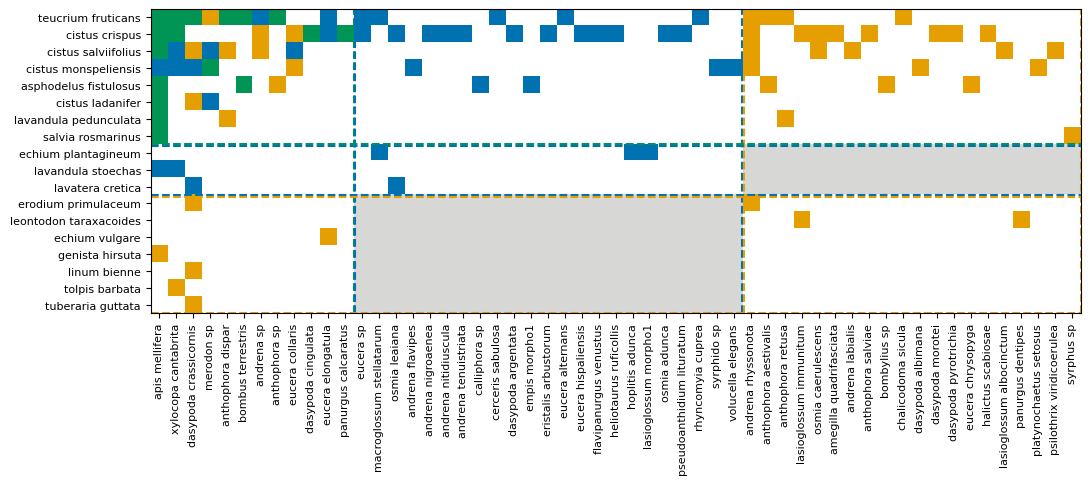

In [9]:
#La identificación la tenemos que hacer en la red NO pesada, que nos permite sabes cuales son las especies permanente sy cuales no
plt.rcParams.update({'font.size': 15})
# Create a figure
fig, ax1 = plt.subplots(figsize=(12, 8))
#plot_betadiversity_matrix_to_ax(web1/web1,web2/web2,ax=ax1)
plot_betadiversity_Wmatrix_to_ax(web1,web2,ax=ax1,weighted=False,names=True)
plt.show()


# Quantification of interaction reorganization - WEIGHTED

In [10]:
changes_df, nodes_df=rewiring_freq_py(web1, web2)
changes_df#.sum(numeric_only=True)

changes_df["metric"].tolist()

['CN_CI',
 'CN_DI',
 'CN_II',
 'CN_LI',
 'CN_GI',
 'L1N_LI',
 'LBN_LI',
 'G1N_GI',
 'GBN_GI']

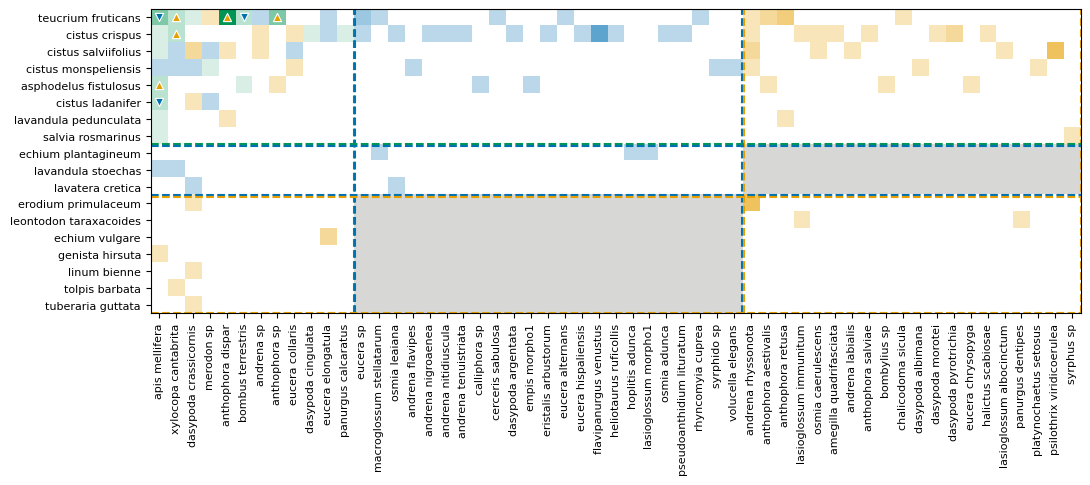

In [9]:
fig, ax1 = plt.subplots(figsize=(12, 8))
plot_betadiversity_Wmatrix_to_ax(web1,web2,ax=ax1,names=True)
plt.show()

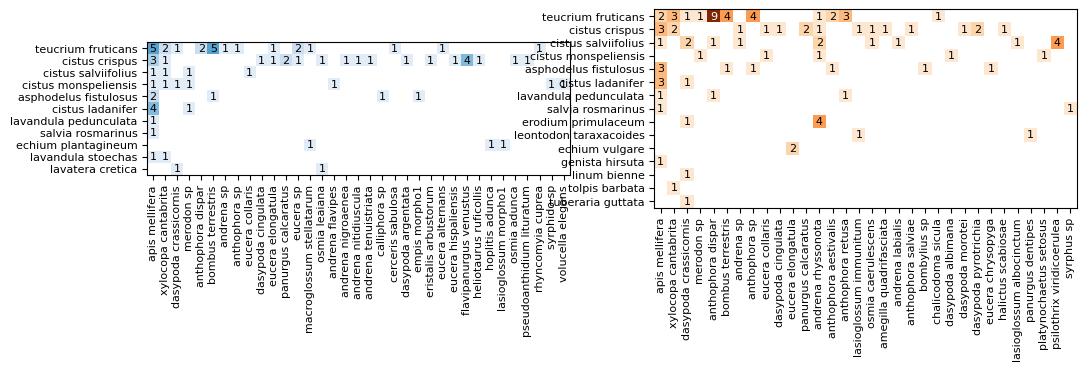

In [11]:
plot_networks_separately_matched_order(web1, web2);

In [11]:
B3,B4,beta_dict2=get_betadiversity_Wnetwork_by_year(networks[site][year+1],networks[site][year+2])#16-17

NameError: name 'B3' is not defined

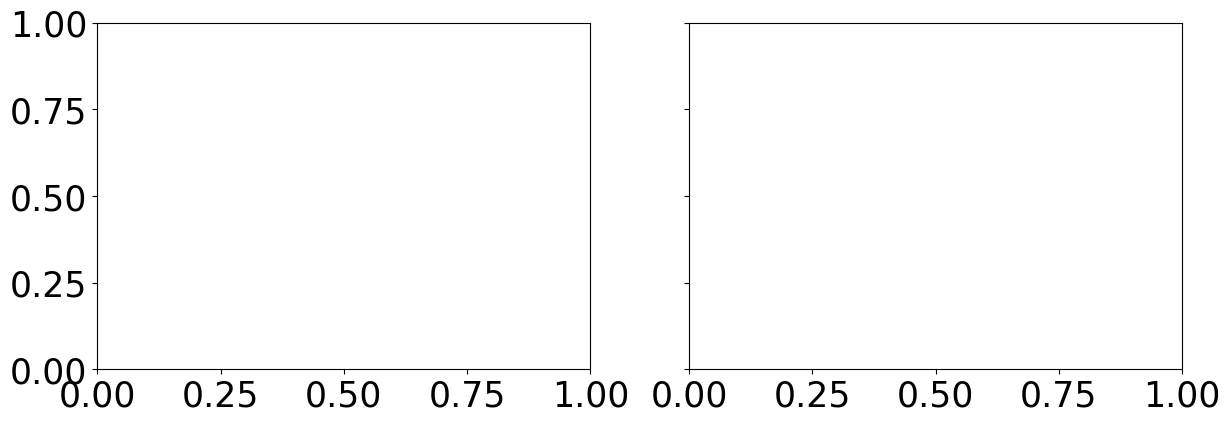

In [12]:
## vamos a hacer una figura con las redes y la matrizs

ncol=2
nrow=1
plt.rcParams.update({'font.size': 25})
fig, axs = plt.subplots(nrow, ncol,figsize=(7*ncol,4.5*nrow),sharey=True)#row


plot_bipartite_Wnetwork_to_ax(B3,draw_labels=False,node_cathegories=beta_dict2,w=1,h=0.3,buffer=8,lw=3,ax=axs[0],edge_color="#0072B2")
plot_bipartite_Wnetwork_to_ax(B4,draw_labels=False,node_cathegories=beta_dict2,w=1,h=0.3,buffer=8,lw=3,ax=axs[1],edge_color="#E69F00")
plt.show()


In [13]:
beta_dict2

{'anthophora sp': 'common',
 'dasypoda crassicornis': 'common',
 'psilothrix viridicoerulea': 'common',
 'chalicodoma sicula': 'common',
 'xylocopa cantabrita': 'common',
 'bombus terrestris': 'common',
 'apis mellifera': 'common',
 'eucera chrysopyga': 'common',
 'anthophora aestivalis': 'common',
 'anthophora retusa': 'common',
 'eucera collaris': 'common',
 'andrena rhyssonota': 'common',
 'lasioglossum albocinctum': 'common',
 'halictus scabiosae': 'y1',
 'panurgus dentipes': 'y1',
 'amegilla quadrifasciata': 'y1',
 'lasioglossum immunitum': 'y1',
 'merodon sp': 'y1',
 'dasypoda pyrotrichia': 'y1',
 'eucera elongatula': 'y1',
 'bombylius sp': 'y1',
 'andrena sp': 'y1',
 'panurgus calcaratus': 'y1',
 'andrena labialis': 'y1',
 'dasypoda albimana': 'y1',
 'syrphus sp': 'y1',
 'dasypoda morotei': 'y1',
 'osmia caerulescens': 'y1',
 'anthophora salviae': 'y1',
 'platynochaetus setosus': 'y1',
 'anthophora dispar': 'y1',
 'dasypoda cingulata': 'y1',
 'dasypoda argentata': 'y2',
 'xyloco

# Global cuantification of changes

Vamos a hacer la cuantificacion de ambas juntas, auqnue plotearemos por separado para unweighted y weighted. 

Primero guardmos todos los cambios de t1 con t2 para cada sitio. 
Luego lo que vamos a hacer es sacar los cambios uanto son por rewiring (CN_LI + CN_GI) y cuantos por ineracciones entre transient y permanentes (L1N_LI + G1N_GI) y cuantos son por 2 especies que cambian (LBN_LI+GBN_GI). 

Esas variables las queremos normalizar al total de cambios, que son : CN_LI+CN_GI+LBN_LI+L1N_LS+GBN_GI+G1N_GI 


In [13]:
metric=['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
metric_N=["PA","PP","A1","P1","A2","P2"]
mi2=pd.MultiIndex.from_product([Sites,Years[1::],metric],names=["Site_ID", "year","metric"])
Changes_df=pd.DataFrame(index=mi2,columns=["n_interactions","freq_interactions"])
Changes_df.sort_index(inplace=True)
mi2N=pd.MultiIndex.from_product([Sites,Years[1::],metric_N],names=["Site_ID", "year","metric"])
Nodes_df=pd.DataFrame(index=mi2N,columns=["n_nodes"])
Nodes_df.sort_index(inplace=True)
#Changes_df

for site in Sites:
    for year in Years[0:-1]:
        changes, nodes = rewiring_freq_py(networks[site][year], networks[site][year+1])
        changes = changes.set_index('metric')          # <- AÑADIR esto
        nodes = nodes.set_index('metric')          # <- AÑADIR esto
        for m in changes.index:                        # <- 'm', NO 'metric'
            Changes_df.loc[(site, year+1, m), 'n_interactions'] = changes.loc[m, 'n_interactions']
            Changes_df.loc[(site, year+1, m), 'freq_interactions'] = changes.loc[m, 'freq_sum']
        for m in nodes.index:                        # <- 'm', NO 'metric'
                    Nodes_df.loc[(site, year+1, m), 'n_nodes'] = nodes.loc[m, 'n_species']

Changes_df     

n_interactions freq_interactions
Site_ID           year metric                                 
aznalcazar        2016 CN_CI               9              12.0
                       CN_DI               3               5.0
                       CN_GI              10              11.0
                       CN_II               5              13.0
                       CN_LI              10              10.0
...                                      ...               ...
villamanrique sur 2022 CN_LI               1               2.0
                       G1N_GI              6               7.0
                       GBN_GI              0               0.0
                       L1N_LI             15              46.0
                       LBN_LI             10              30.0

[756 rows x 2 columns]

In [14]:
Nodes_df

n_nodes
Site_ID           year metric        
aznalcazar        2016 A1          23
                       A2          20
                       P1           3
                       P2           7
                       PA          12
...                               ...
villamanrique sur 2022 A2           5
                       P1           3
                       P2           0
                       PA           7
                       PP           5

[504 rows x 1 columns]

# Temporal study
Lets choose one site (for simplicity) and study how it changes from year to year


<Axes: xlabel='year', ylabel='n_interactions'>

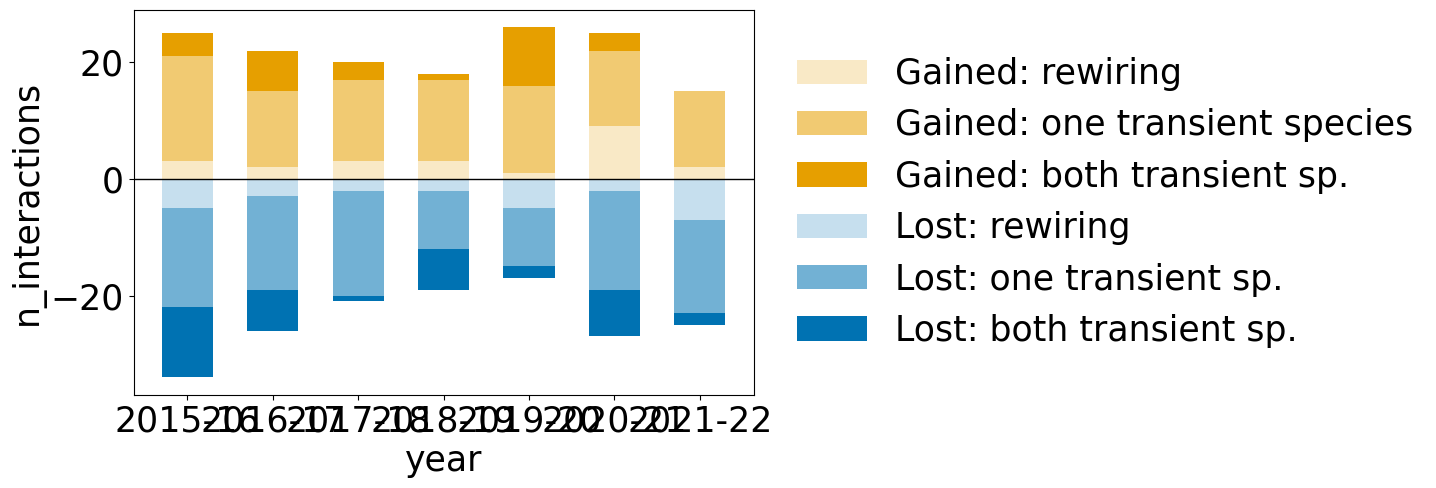

In [16]:
site=Sites[1] #sites 1
df_site=Changes_df.loc[site]
#['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']

plot_diverging_bars(df_site, value_col='n_interactions')

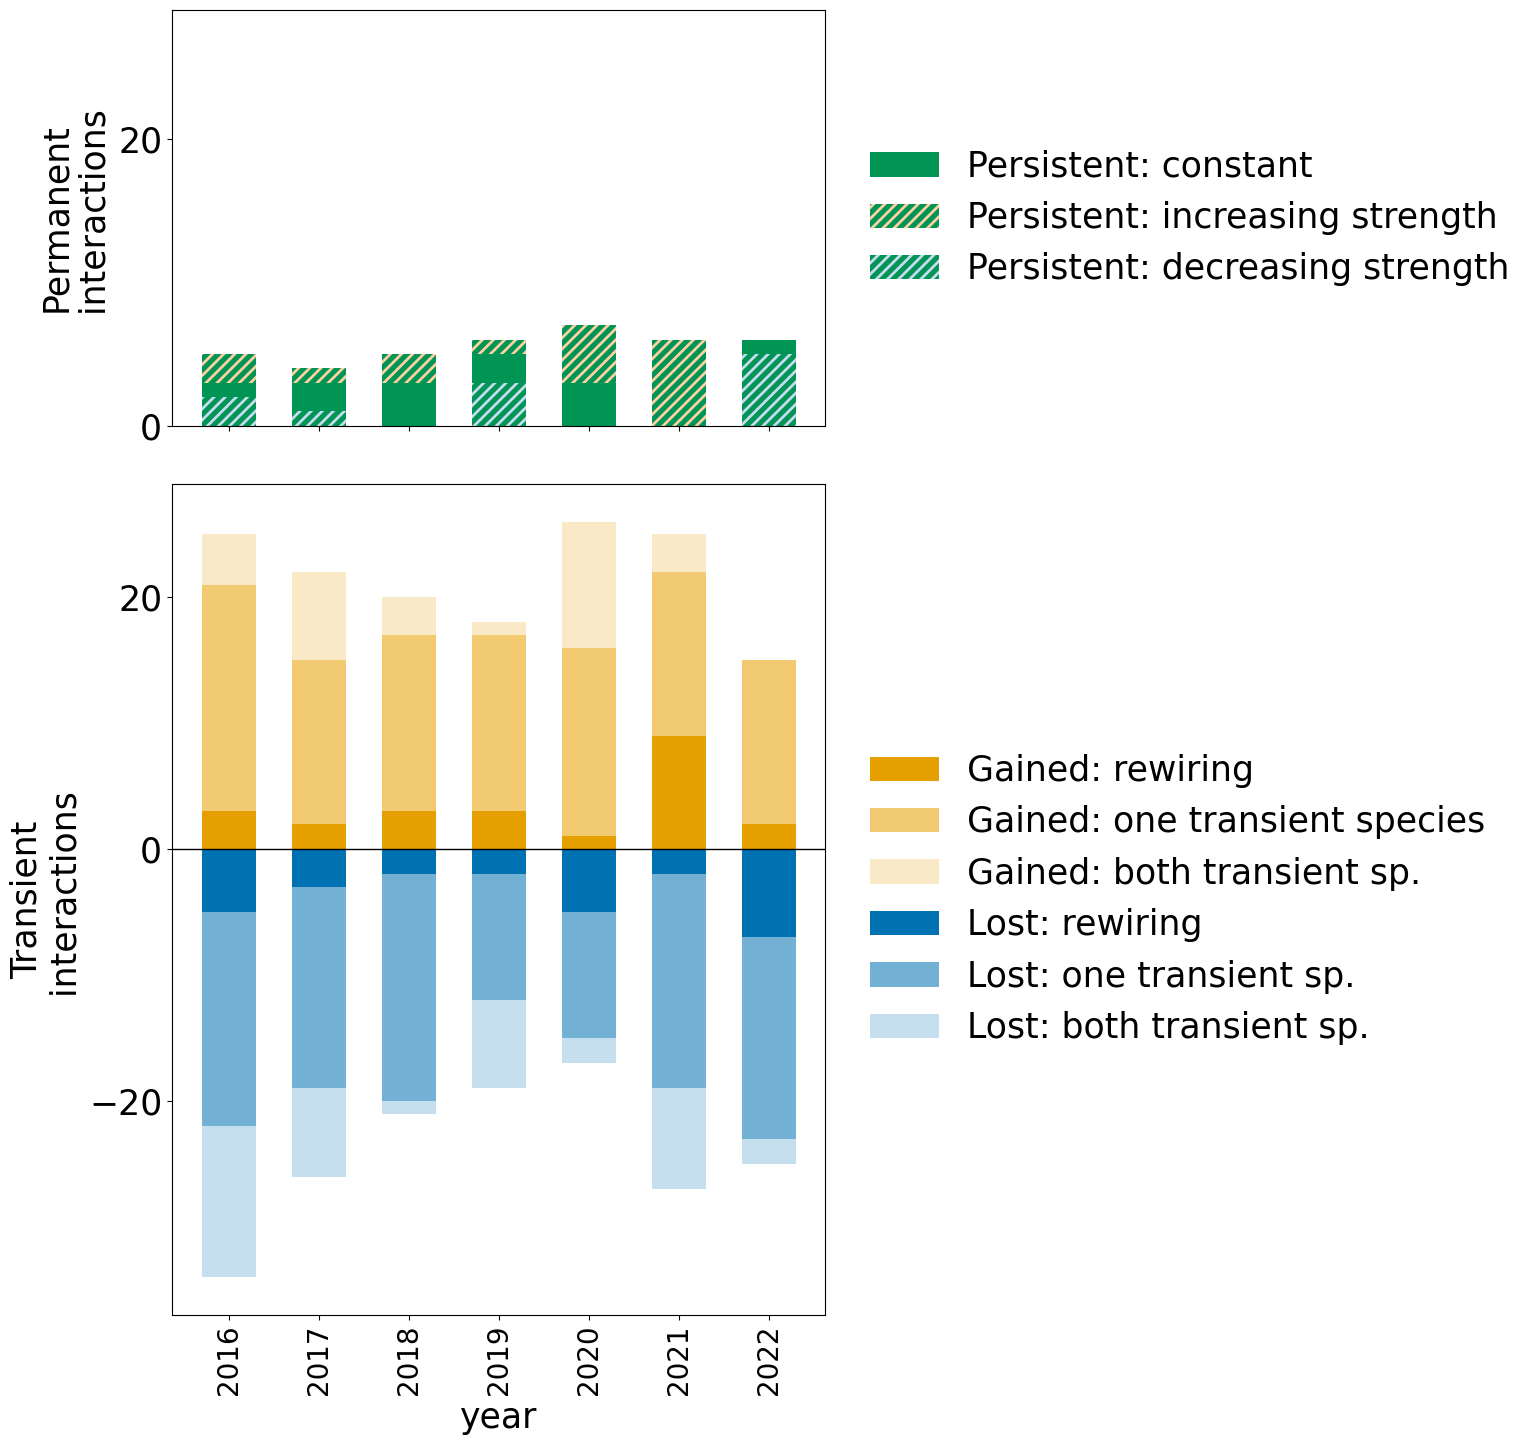

In [17]:
fig, (ax_top, ax_bottom) = plot_diverging_bars_with_constant(df_site, value_col='n_interactions')

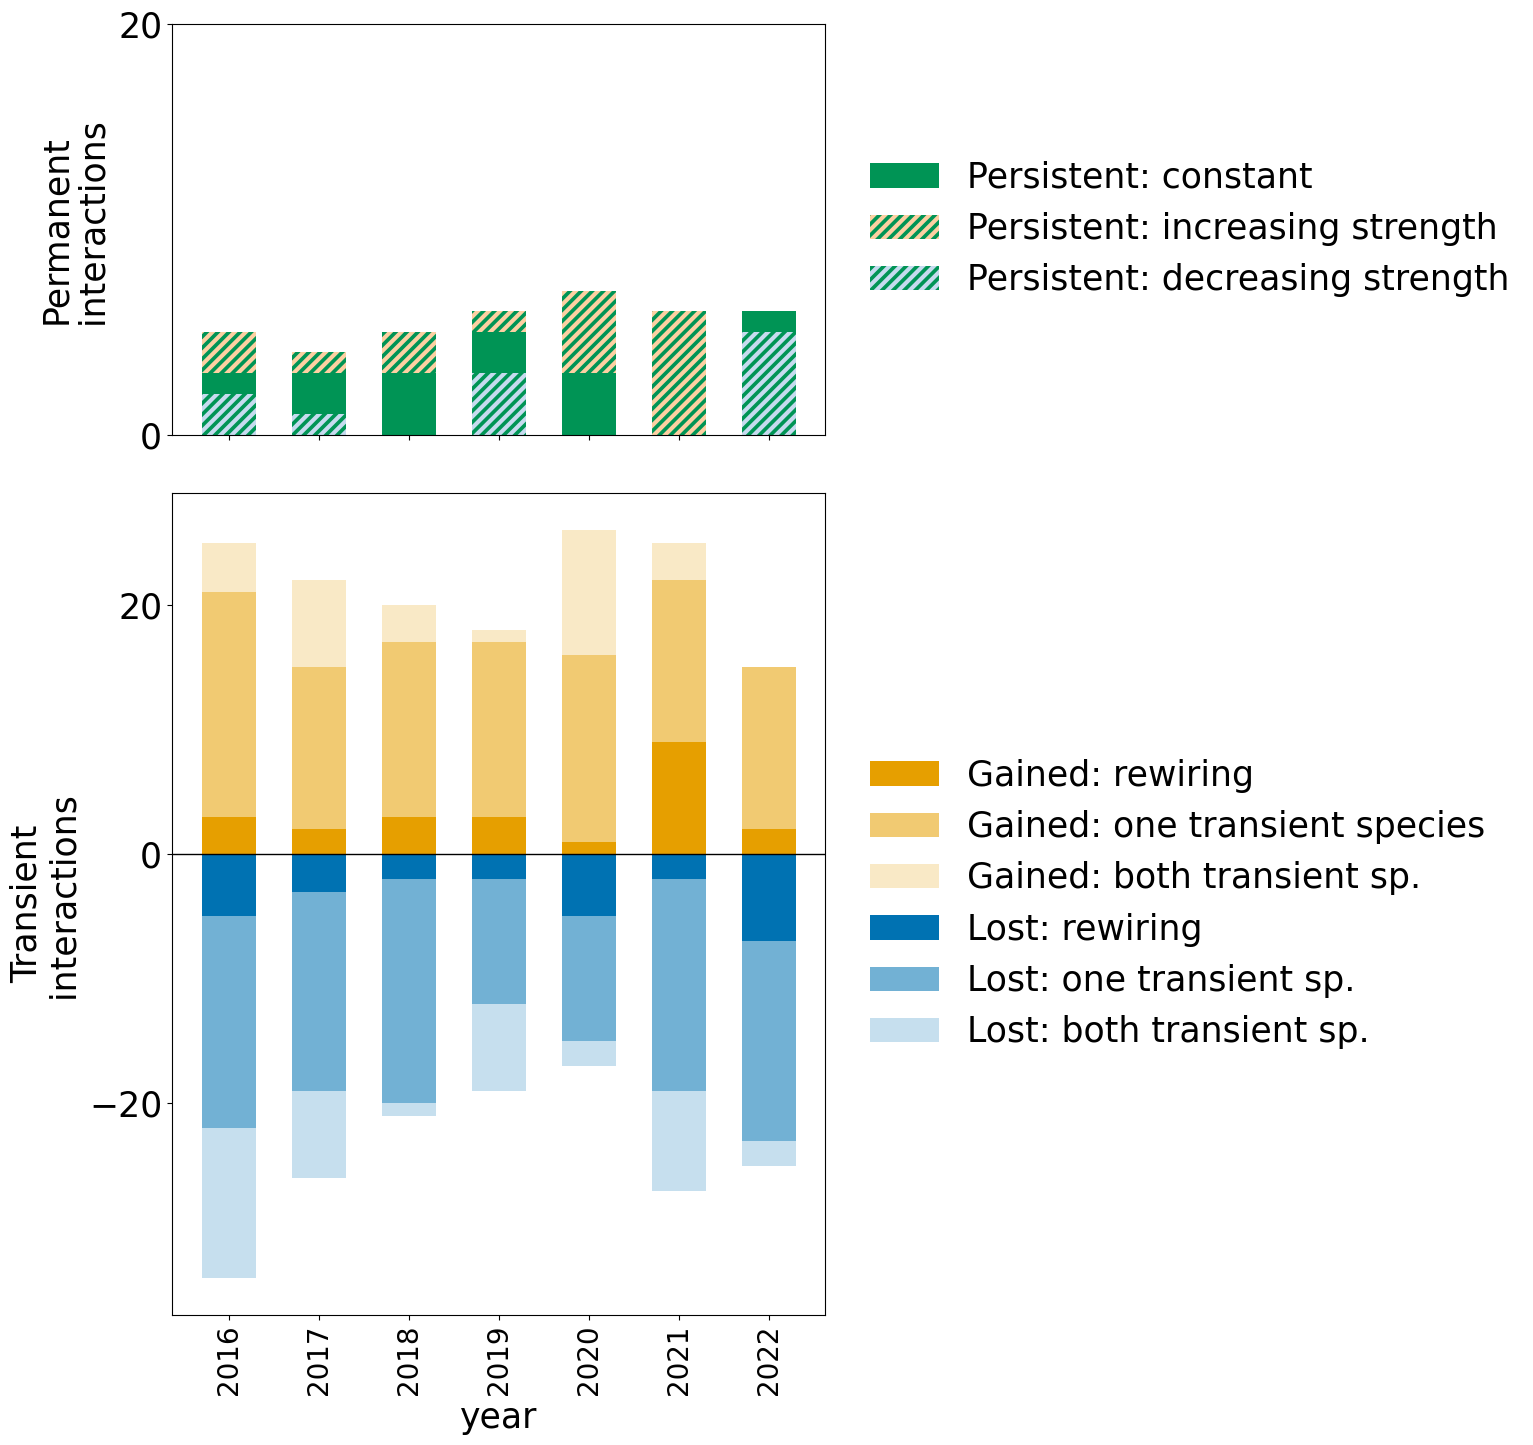

In [18]:
fig, (ax_top, ax_bottom) = plot_diverging_bars_with_constant(df_site, value_col='n_interactions',hatch_linewidth=3,ylim_top=(0, 20))


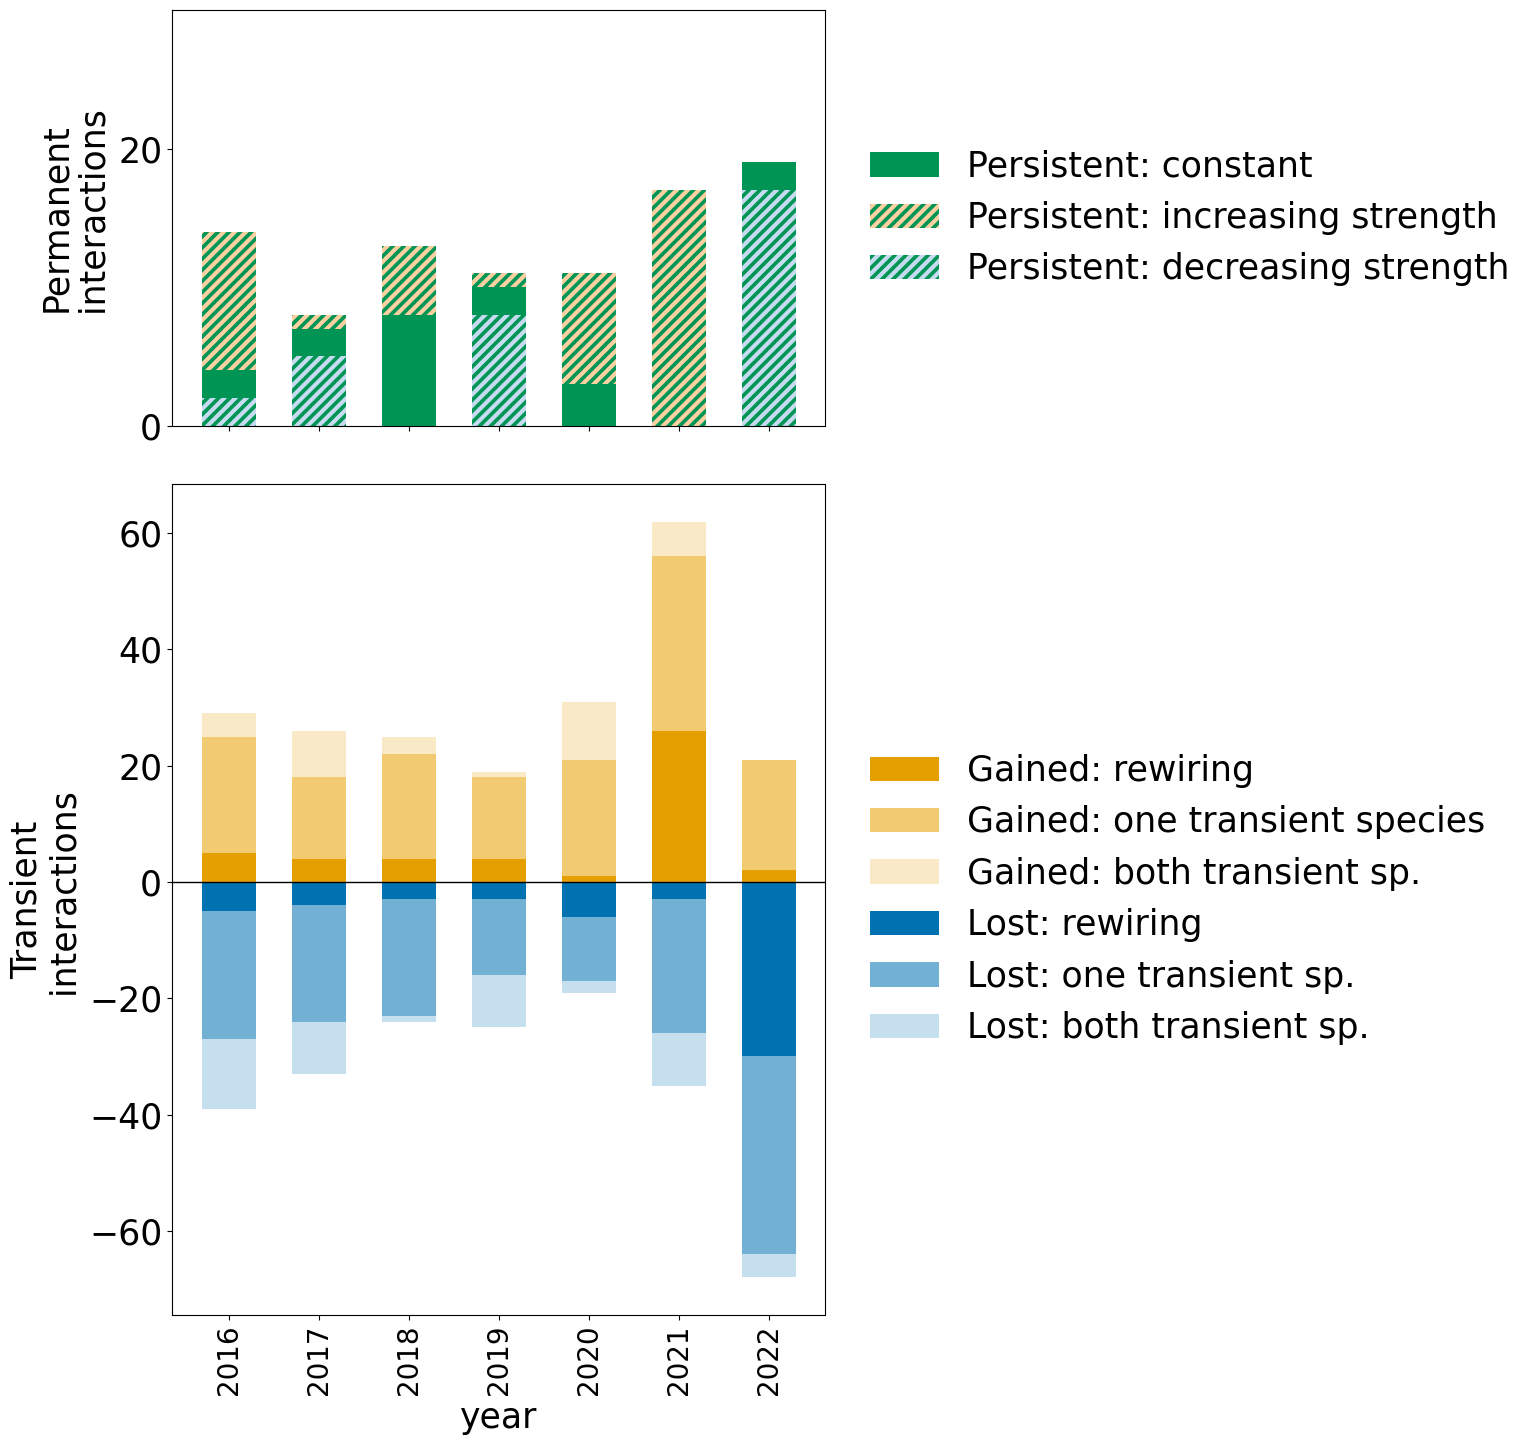

In [19]:
fig, (ax_top, ax_bottom) = plot_diverging_bars_with_constant(df_site, value_col='freq_interactions',hatch_linewidth=3,ylim_top=(0, 30))

Vale, podemos de aqui ver que se sueleng anar tanas como se pierden, tanto en los cambios como en intensidad. 
sin embargo, mientras que la mayoria de interacciones transient tienen una itnensidad de x, la frecuencia de las int permanentes, especialmente de las que aumentan o disminuyen son algo más intensas, lo que hace que cuando tenemos en cuenta la red pesada, la mayoria de interacciones cambia  de un año para otro. No se mu bien como decir esto. 

 

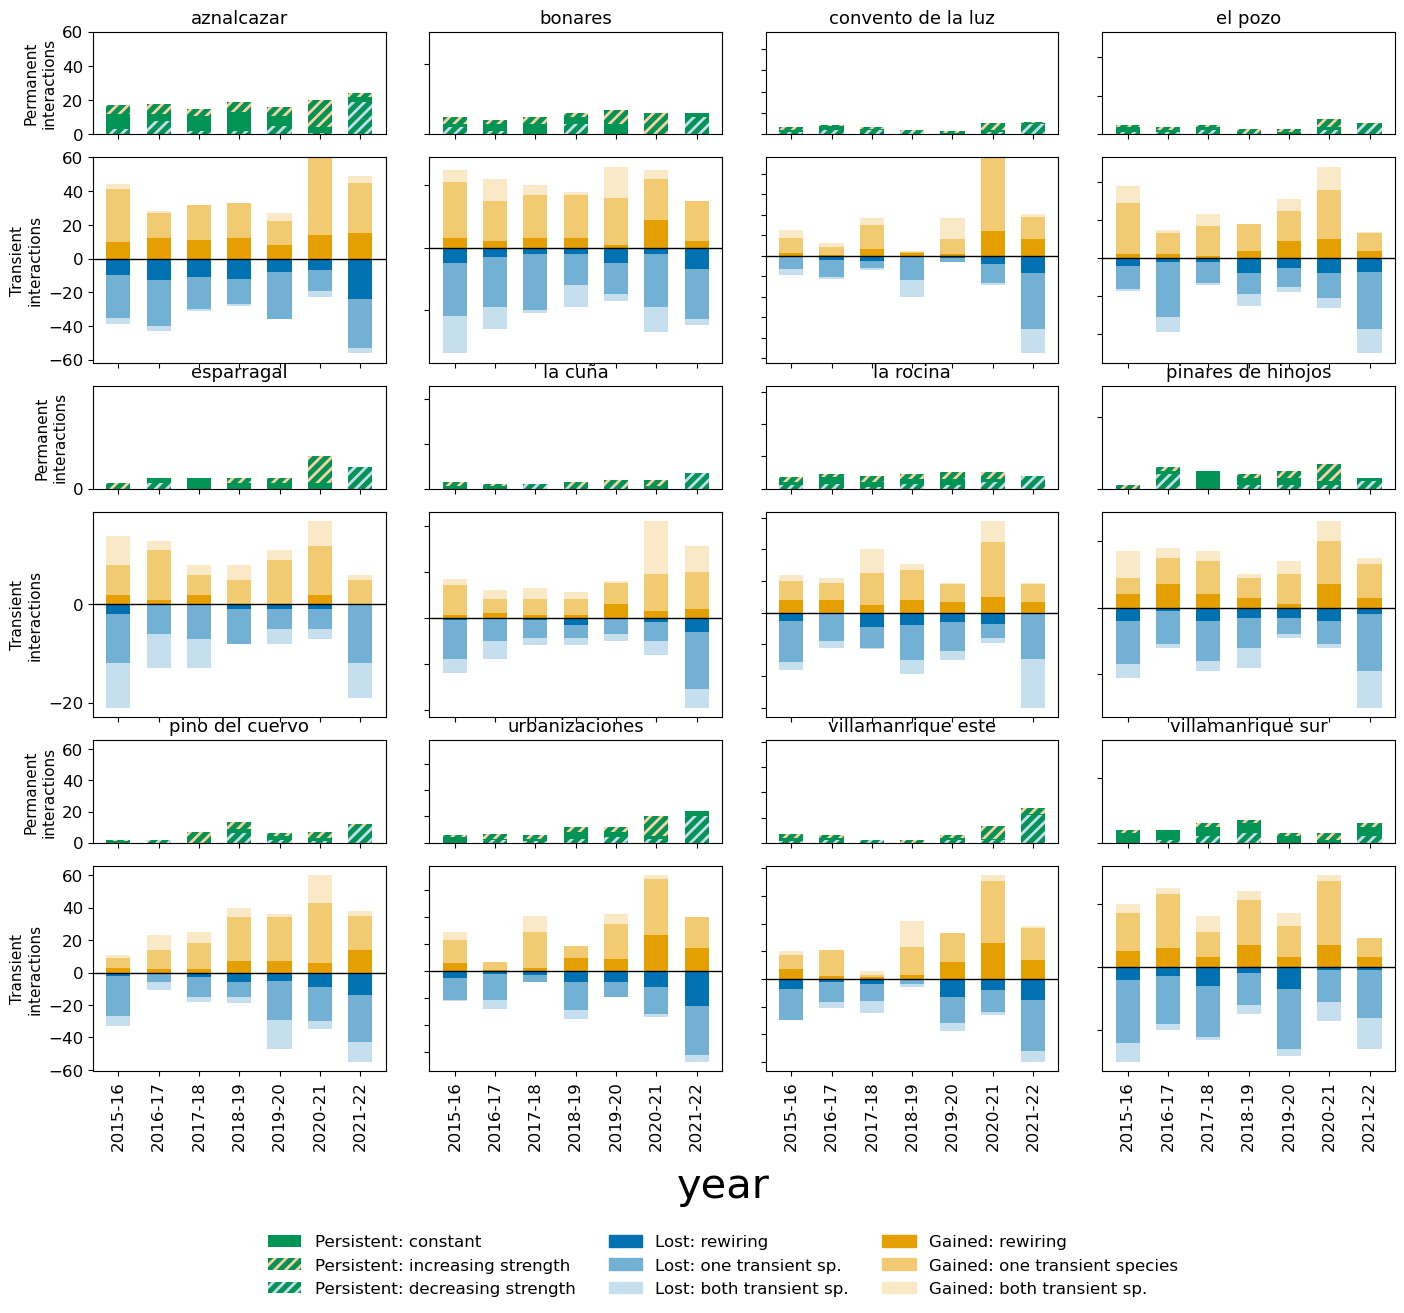

In [20]:
fig, site_axes = plot_diverging_bars_with_constant_all_sites(Changes_df, value_col='n_interactions', sharey=False, year_label_dict=year_label_dict, label_dict=label_dict)
plt.savefig("all_sites.png", dpi=250, bbox_inches='tight')

In [21]:
nodes_df

,metric,n_species
0,PA,12
1,PP,8
2,A1,23
3,P1,3
4,A2,20
5,P2,7


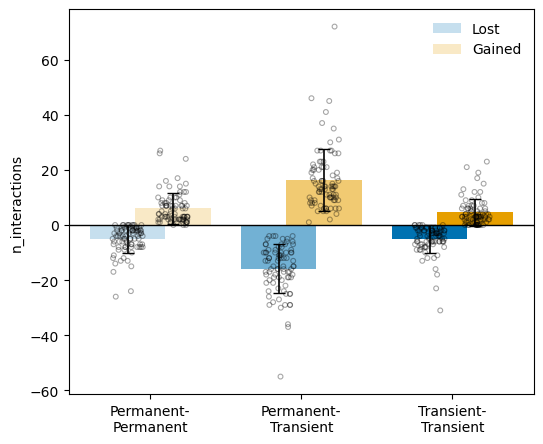

In [22]:
fig, ax = plt.subplots(figsize=(6,5))
plot_diverging_bars_mean_error(Changes_df, value_col='n_interactions', ax=ax)
plt.savefig("mean_error.png", dpi=150, bbox_inches='tight')

NameError: name 'plot_diverging_bars_mean_error_polar' is not defined

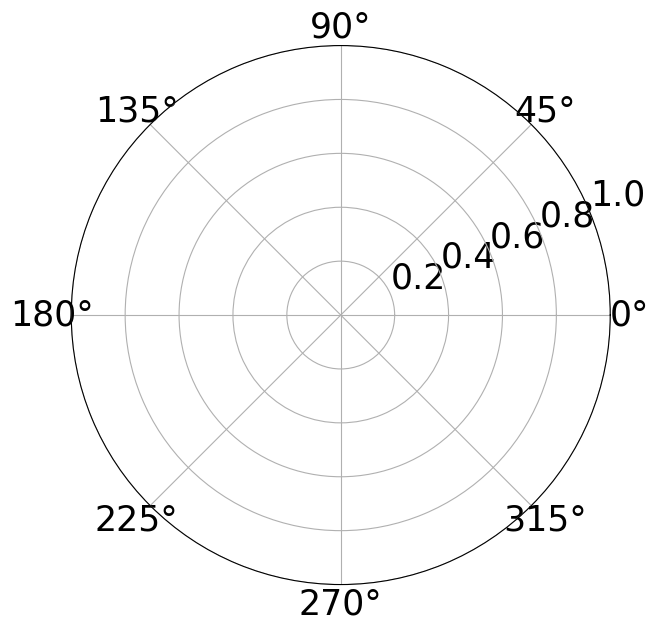

In [23]:
fig, ax = plt.subplots(figsize=(7,7), subplot_kw={'projection': 'polar'})
plot_diverging_bars_mean_error_polar(Changes_df, value_col='n_interactions', ax=ax,show_points=False)
plt.savefig("polar.png", dpi=150, bbox_inches='tight')

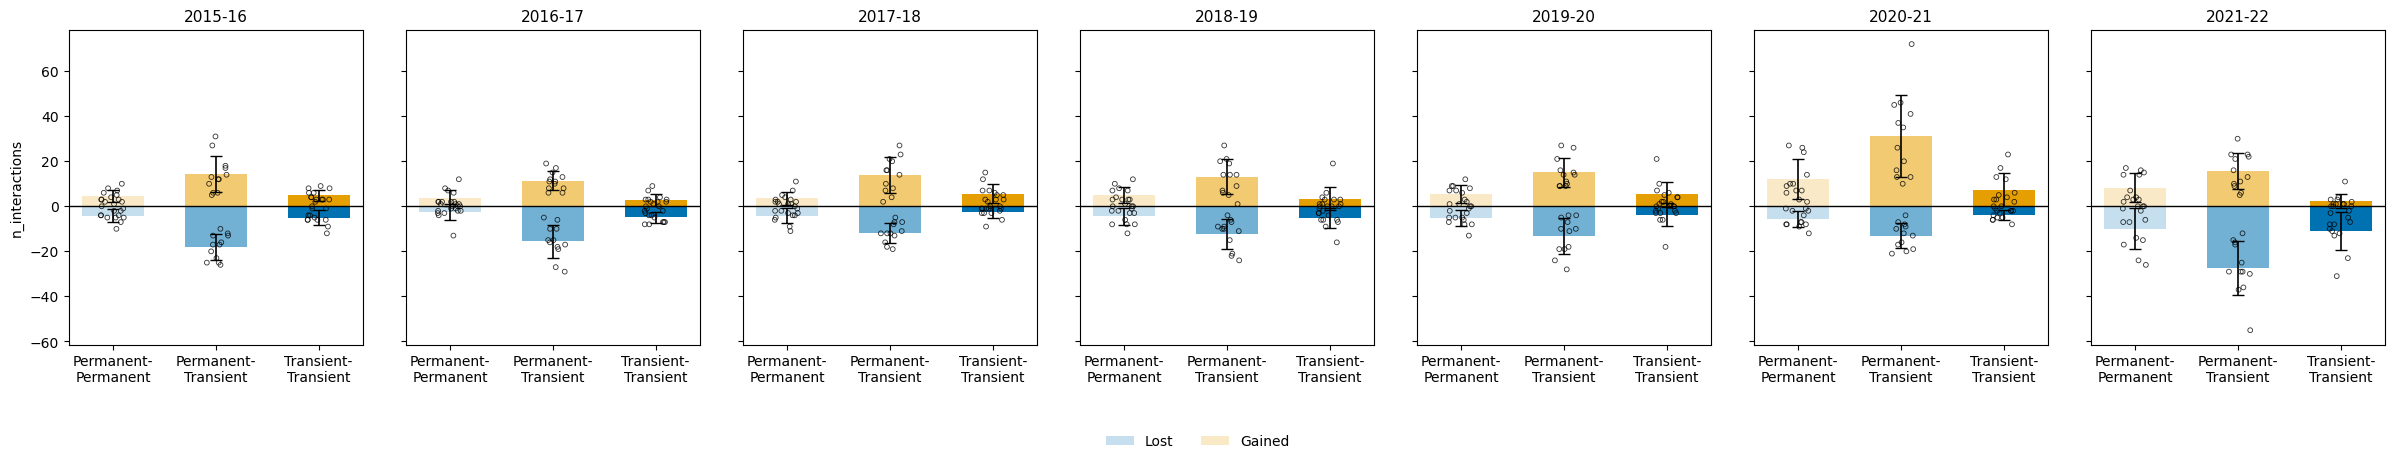

In [ ]:
fig, year_axes = plot_diverging_bars_mean_error_by_year(Changes_df, value_col='n_interactions', year_label_dict=year_label_dict)
plt.savefig("by_year.png", dpi=150, bbox_inches='tight')

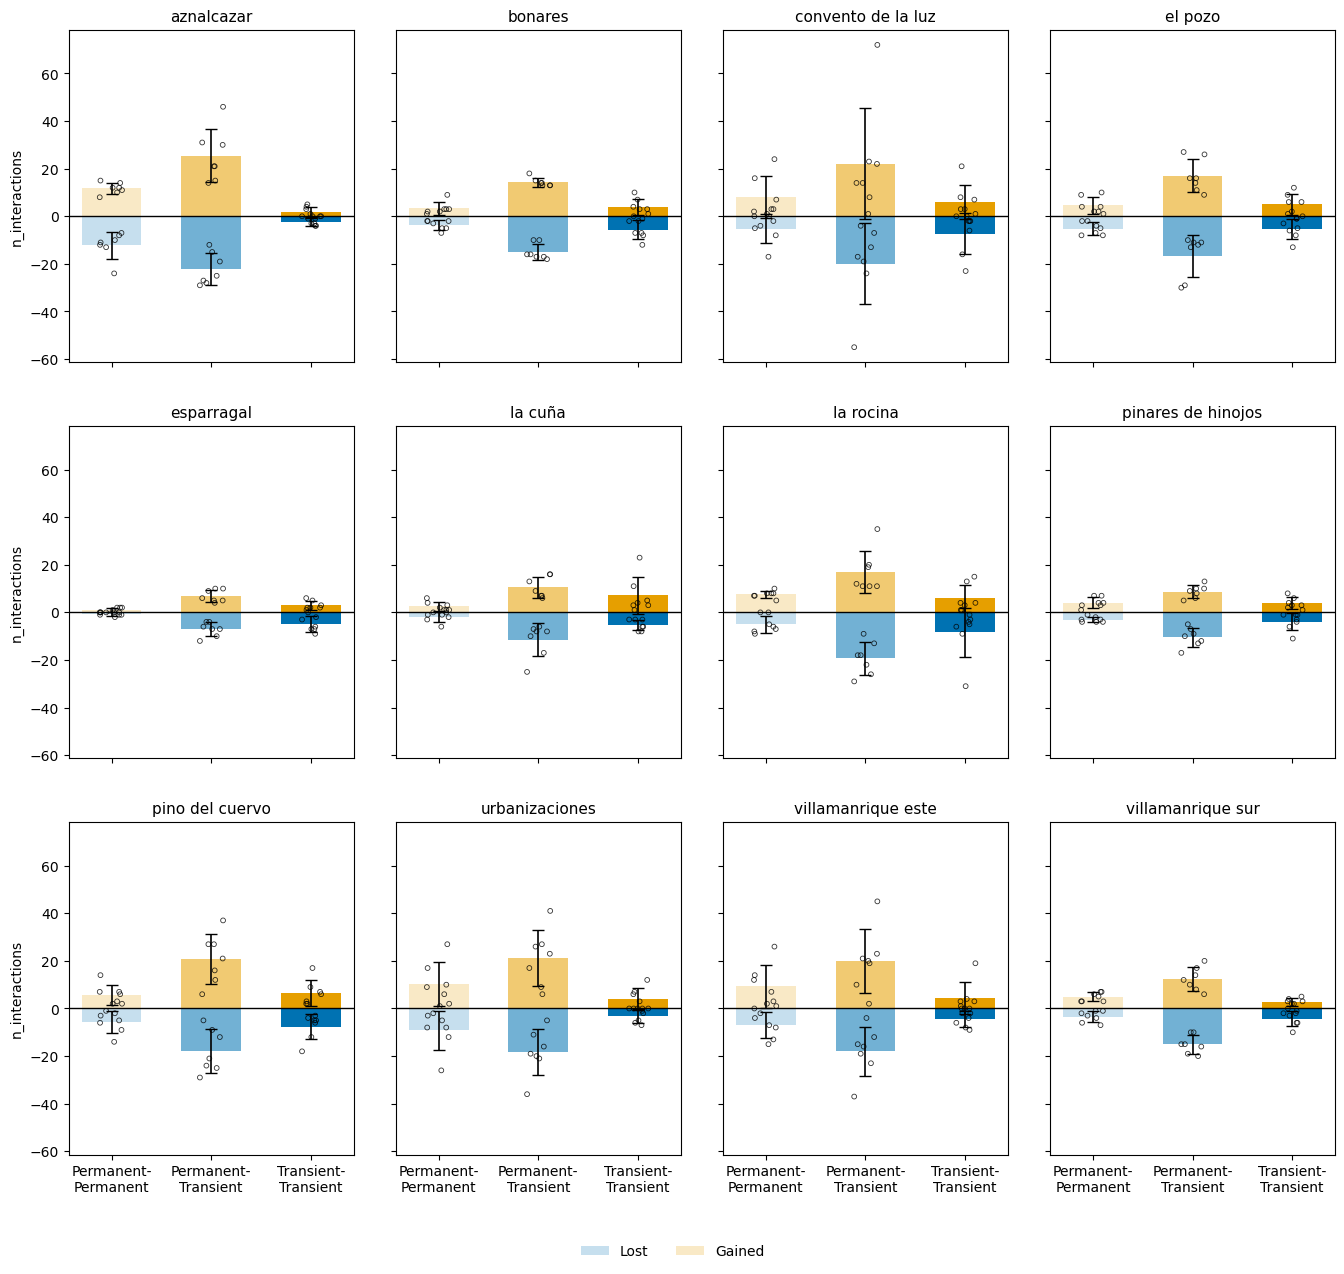

In [ ]:
fig, site_axes = plot_diverging_bars_mean_error_by_site(Changes_df, value_col='n_interactions')
plt.savefig("by_site.png", dpi=150, bbox_inches='tight')

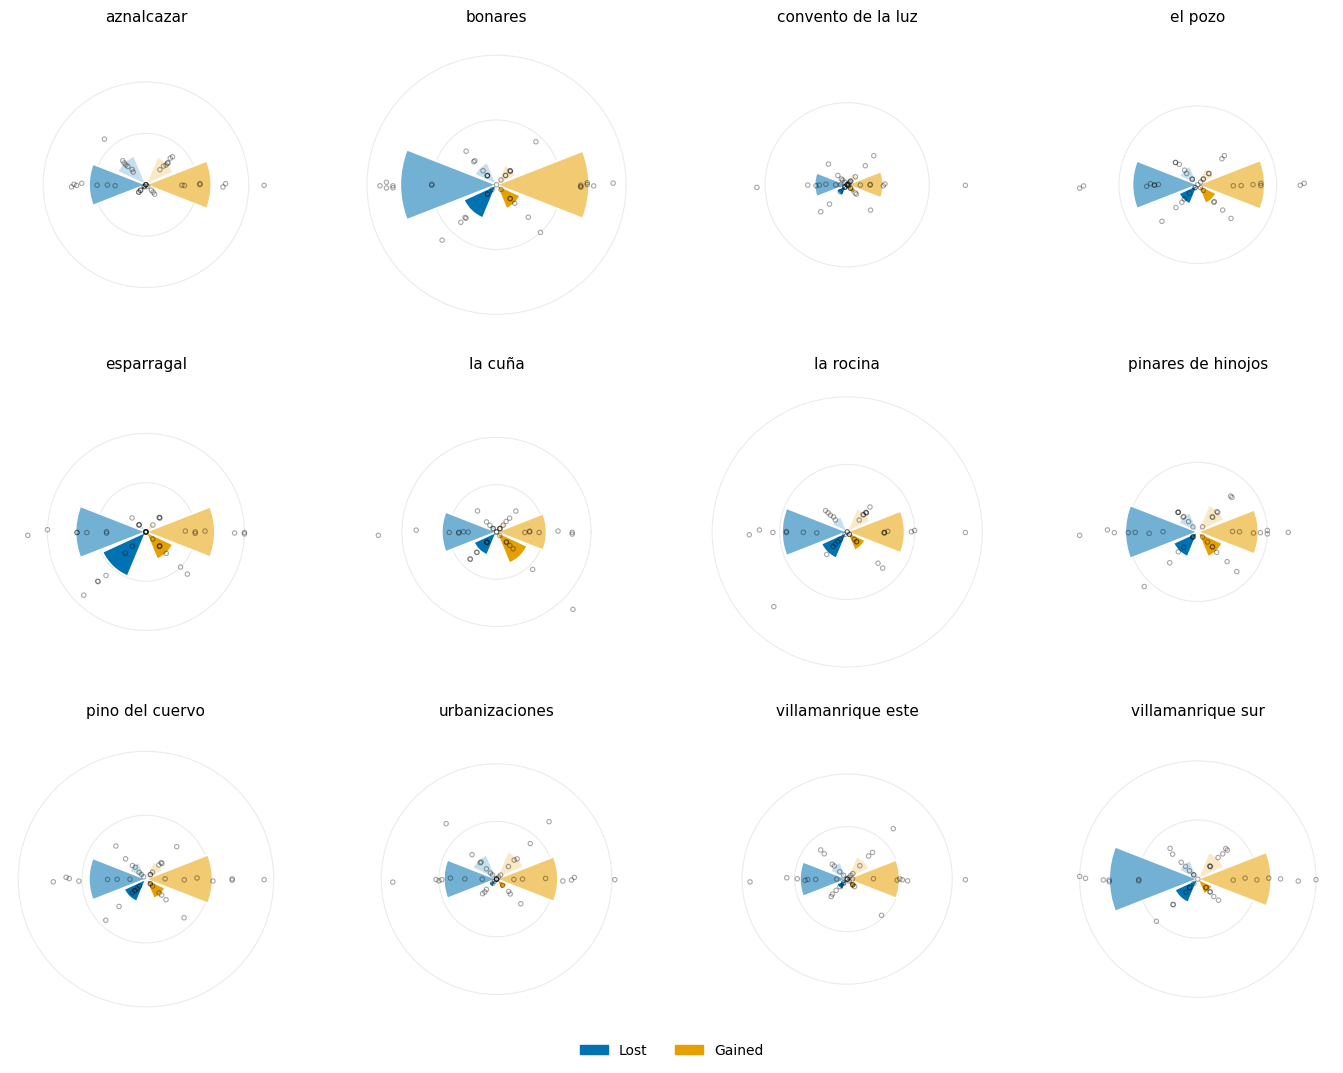

In [ ]:
fig, site_axes = plot_diverging_bars_mean_error_polar_by_site(Changes_df, value_col='n_interactions', show_points=True)   # o True)
plt.savefig("polar_by_site.png", dpi=150, bbox_inches='tight')

In [ ]:
import matplotlib.gridspec as gridspec

def plot_diverging_bars_with_constant_all_sites(
        df, value_col='freq_sum', ncol=4, nrow=3, figsize=None,
        height_ratios_per_site=(1, 2), sharey='row', sharex=True,
        match_scale=True, ylim_top=None, ytick_step=20,
        loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
        gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
        loss_colors=('#C6DFEE', '#72B1D4', '#0072B2'),
        gain_colors=('#F9E9C6', '#F1CA72', '#E69F00'),
        constant_metrics=('CN_DI', 'CN_CI', 'CN_II'),
        constant_facecolor='#009455',
        constant_edgecolors=('#C6DBEF', None, '#FDD0A2'),
        constant_hatches=('///', None, '///'),
        hatch_linewidth=2.0,
        year_col='year', metric_col='metric', site_level='Site_ID',
        rotate_years=90, year_label_dict=None, label_dict=None,
        hatch_legend_order=(1, 2, 0), legend_ncol=3):
    """
    Version 'todos los sitios' de plot_diverging_bars_with_constant: para CADA
    Site_ID, dibuja los dos paneles (constante arriba + divergente abajo),
    organizados en una grilla nrow x ncol (por defecto 3x4, para 12 sitios).

    Replica los mismos parametros/colores/comportamiento que la version de
    un solo sitio (MultipleLocator para los ticks del eje y, year_label_dict
    para las etiquetas de año, orden del hatch en la leyenda) para que ambas
    figuras sean visualmente coherentes.

    Parameters
    ----------
    year_label_dict : dict o None
        {año: texto legible}. Si None, se usan los años tal cual.
    label_dict : dict o None
        {codigo_metrica: texto legible}, usado en la leyenda combinada.
    hatch_legend_order : tuple de int
        Orden de las 3 entradas del bloque "constante" en la leyenda, como
        indices sobre constant_metrics=('CN_DI','CN_CI','CN_II'). Por defecto
        (1, 2, 0) = CN_CI, CN_II, CN_DI (constante, aumenta, disminuye).
    sharey : {'row', 'all', None}
        Igual que en plot_diverging_bars_all_sites.
    ytick_step : float
        Paso de MultipleLocator para el eje y de TODOS los paneles.

    Devuelve
    -------
    fig, site_axes : dict {site: (ax_top, ax_bottom)}
    """
    if year_label_dict is None:
        year_label_dict = {}
    if label_dict is None:
        label_dict = {}

    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()
    sites = sorted(df_flat[site_level].unique())

    if figsize is None:
        figsize = (4.2 * ncol, (height_ratios_per_site[0] + height_ratios_per_site[1]) * 1.5 * nrow)

    fontsize=12

    fig = plt.figure(figsize=figsize)
    height_ratios = list(height_ratios_per_site) * nrow
    gs = gridspec.GridSpec(nrow * 2, ncol, figure=fig, height_ratios=height_ratios,
                            hspace=0.15, wspace=0.15)

    site_axes = {}
    ref_x_by_col = {}
    ref_ytop_by_row = {}
    ref_ybottom_by_row = {}
    ref_ytop_global = [None]
    ref_ybottom_global = [None]

    for i, site in enumerate(sites):
        row_group = i // ncol
        col = i % ncol

        sharex_ax = ref_x_by_col.get(col) if sharex else None
        if sharey == 'row':
            sharey_top_ax = ref_ytop_by_row.get(row_group)
            sharey_bottom_ax = ref_ybottom_by_row.get(row_group)
        elif sharey == 'all':
            sharey_top_ax = ref_ytop_global[0]
            sharey_bottom_ax = ref_ybottom_global[0]
        else:
            sharey_top_ax = None
            sharey_bottom_ax = None

        ax_top = fig.add_subplot(gs[row_group * 2, col], sharex=sharex_ax, sharey=sharey_top_ax)
        ax_bottom = fig.add_subplot(gs[row_group * 2 + 1, col], sharex=sharex_ax, sharey=sharey_bottom_ax)

        if sharex and col not in ref_x_by_col:
            ref_x_by_col[col] = ax_bottom
        if sharey == 'row':
            ref_ytop_by_row.setdefault(row_group, ax_top)
            ref_ybottom_by_row.setdefault(row_group, ax_bottom)
        elif sharey == 'all':
            if ref_ytop_global[0] is None:
                ref_ytop_global[0] = ax_top
            if ref_ybottom_global[0] is None:
                ref_ybottom_global[0] = ax_bottom

        df_site = df_flat[df_flat[site_level] == site]

        _plot_constant_on_ax(df_site, value_col, ax_top, constant_metrics,
                              constant_facecolor, constant_edgecolors,
                              constant_hatches, hatch_linewidth, year_col, metric_col)

        _plot_diverging_on_ax(df_site, value_col, ax_bottom, loss_metrics, gain_metrics,
                               loss_colors, gain_colors, year_col, metric_col)

        ax_top.set_title(str(site), fontsize=fontsize + 1)
        ax_top.set_xlabel('')
        ax_top.tick_params(axis='both', labelsize=fontsize)
        ax_bottom.tick_params(axis='both', labelsize=fontsize)

        years = sorted(df_site[year_col].unique())
        ax_bottom.set_xticks(np.arange(len(years)))
        ax_bottom.set_xticklabels([year_label_dict.get(y, y) for y in years],
                                   rotation=rotate_years, fontsize=fontsize)

        site_axes[site] = (ax_top, ax_bottom)

    # ylim del panel superior, DESPUES de que sharey sincronizo los inferiores
    for site, (ax_top, ax_bottom) in site_axes.items():
        if ylim_top is not None:
            ax_top.set_ylim(*ylim_top)
        elif match_scale:
            ax_top.set_ylim(0, ax_bottom.get_ylim()[1])
        ax_top.yaxis.set_major_locator(MultipleLocator(ytick_step))
        ax_bottom.yaxis.set_major_locator(MultipleLocator(ytick_step))

    # oculta labels interiores (deja solo bordes: año abajo, valores a la izq)
    for site, (ax_top, ax_bottom) in site_axes.items():
        ax_top.label_outer()
        ax_bottom.label_outer()

    # ylabels solo en la columna izquierda (los paneles ya comparten via label_outer,
    # pero el texto del label hay que ponerlo a mano en la primera columna de cada fila)
    for row_group in range(nrow):
        first_site_idx = row_group * ncol
        if first_site_idx < len(sites):
            ax_top, ax_bottom = site_axes[sites[first_site_idx]]
            ax_top.set_ylabel('Permanent\ninteractions', fontsize=fontsize-1)
            ax_bottom.set_ylabel('Transient\ninteractions', fontsize=fontsize-1)

    # leyenda UNICA combinada, debajo de toda la figura, con el orden del hatch aplicado
    handles = []
    ordered_constant = [(constant_metrics[j], constant_edgecolors[j], constant_hatches[j]) for j in hatch_legend_order]
    for metric, edgecolor, hatch in ordered_constant:
        handles.append(mpatches.Patch(
            facecolor=constant_facecolor,
            edgecolor=edgecolor if edgecolor else constant_facecolor,
            hatch=hatch, linewidth=0, label=label_dict.get(metric, metric)))
    for metric, color in zip(loss_metrics, loss_colors):
        handles.append(mpatches.Patch(color=color, label=label_dict.get(metric, metric)))
    for metric, color in zip(gain_metrics, gain_colors):
        handles.append(mpatches.Patch(color=color, label=label_dict.get(metric, metric)))

    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0),
               ncol=legend_ncol, frameon=False,fontsize=fontsize)

    fig.supxlabel(year_col)

    return fig, site_axes


# -----------------------------------------------------------------------
# helpers internos -- dibujan sobre un ax dado, sin crear figura/leyenda propia
# -----------------------------------------------------------------------

def _plot_constant_on_ax(df_site, value_col, ax, constant_metrics, constant_facecolor,
                          constant_edgecolors, constant_hatches, hatch_linewidth,
                          year_col, metric_col):
    import matplotlib as mpl
    mpl.rcParams['hatch.linewidth'] = hatch_linewidth

    years = sorted(df_site[year_col].unique())
    x = np.arange(len(years))
    bottom = np.zeros(len(years))
    for metric, edgecolor, hatch in zip(constant_metrics, constant_edgecolors, constant_hatches):
        vals = np.array([
            df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
        ax.bar(x, vals, bottom=bottom, facecolor=constant_facecolor,
               edgecolor=edgecolor if edgecolor else constant_facecolor,
               hatch=hatch, linewidth=0, width=0.6)
        bottom += vals
    ax.set_xticks(x)


def _plot_diverging_on_ax(df_site, value_col, ax, loss_metrics, gain_metrics,
                           loss_colors, gain_colors, year_col, metric_col):
    years = sorted(df_site[year_col].unique())
    x = np.arange(len(years))

    bottom = np.zeros(len(years))
    for metric, color in zip(loss_metrics, loss_colors):
        vals = np.array([
            -df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
        ax.bar(x, vals, bottom=bottom, color=color, width=0.6)
        bottom += vals

    top = np.zeros(len(years))
    for metric, color in zip(gain_metrics, gain_colors):
        vals = np.array([
            df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
        ax.bar(x, vals, bottom=top, color=color, width=0.6)
        top += vals

    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)

In [ ]:
def plot_diverging_bars_mean_error(df, value_col='freq_sum', ax=None, figsize=(6, 5),
                                    loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
                                    gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
                                    category_labels=('Permanent-\nPermanent', 'Permanent-\nTransient', 'Transient-\nTransient'),
                                    loss_colors=('#C6DFEE', '#72B1D4', '#0072B2'),
                                    gain_colors=('#F9E9C6', '#F1CA72', '#E69F00'),
                                    year_col='year', metric_col='metric', site_level='Site_ID',
                                    bar_width=0.6, capsize=4, fontsize=10,
                                    show_points=True, point_color='black',
                                    point_alpha=0.8, point_size=12, jitter=0.12):
    """
    Grafico de barras con barra de error, para TODOS los sitios a la vez.
 
    Eje x: las 3 categorias de nodo (Permanent-Permanent / Permanent-Transient /
    Transient-Transient), NO los años. Para cada categoria hay DOS barras
    (perdida hacia abajo, ganancia hacia arriba), SIN apilar entre si.
 
    Altura de cada barra = media de value_col a traves de TODOS los
    Site_ID x year para esa metrica. Barra de error = desviacion estandar
    a traves de esa misma coleccion de sitios x años. Opcionalmente (show_points),
    se superponen los valores individuales (un punto por Site_ID x year) con
    jitter horizontal, discretos (alpha bajo, tamaño pequeño) para no competir
    visualmente con la barra.
 
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame COMPLETO (todos los sitios, todos los años), con
        Site_ID/year/metric como MultiIndex o como columnas.
    loss_metrics, gain_metrics : tuple de 3 str
        En el orden (CN, 1-nuevo, ambas-nuevas).
    category_labels : tuple de 3 str
        Etiquetas del eje x, mismo orden que loss_metrics/gain_metrics.
    loss_colors, gain_colors : tuple de 3 str
        Un color por categoria (mismo orden que loss_metrics/gain_metrics).
    show_points : bool
        Si True (por defecto), superpone los valores individuales (un punto
        por Site_ID x year) sobre cada barra, con jitter horizontal.
    point_color : str
        Color de los puntos (por defecto negro, discreto).
    point_alpha : float
        Opacidad de los puntos (bajo por defecto, para poco protagonismo).
    point_size : float
        Tamaño (en puntos^2, como el parametro 's' de scatter) de cada punto.
    jitter : float
        Dispersion horizontal aleatoria de los puntos alrededor de cada barra
        (fraccion de bar_width aproximadamente).
 
    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
 
    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()
 
    x = np.arange(len(loss_metrics))
 
    def mean_std_vals(metric):
        vals = df_flat.loc[df_flat[metric_col] == metric, value_col]
        return vals.mean(), vals.std(), vals.values
 
    loss_stats = [mean_std_vals(m) for m in loss_metrics]
    gain_stats = [mean_std_vals(m) for m in gain_metrics]
 
    rng = np.random.default_rng(0)  # semilla fija -- jitter reproducible entre llamadas
 
    for i in range(len(x)):
        loss_mean, loss_std, loss_vals = loss_stats[i]
        gain_mean, gain_std, gain_vals = gain_stats[i]
 
        ax.bar(x[i], -loss_mean, yerr=loss_std, color=loss_colors[i],
               width=bar_width, capsize=capsize,
               label='Lost' if i == 0 else None,
               error_kw={'elinewidth': 1.2}, zorder=2)
        ax.bar(x[i], gain_mean, yerr=gain_std, color=gain_colors[i],
               width=bar_width, capsize=capsize,
               label='Gained' if i == 0 else None,
               error_kw={'elinewidth': 1.2}, zorder=2)
 
        if show_points:
            jitter_x_loss = x[i] + rng.uniform(-jitter, jitter, size=len(loss_vals))
            jitter_x_gain = x[i] + rng.uniform(-jitter, jitter, size=len(gain_vals))
            ax.scatter(jitter_x_loss, -loss_vals, facecolors='none', edgecolors=point_color,alpha=point_alpha,
                       s=point_size, zorder=3, linewidths=0.6)
            ax.scatter(jitter_x_gain, gain_vals, facecolors='none', edgecolors=point_color,alpha=point_alpha,
                       s=point_size, zorder=3, linewidths=0.6)
 
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(category_labels, fontsize=fontsize)
    ax.set_ylabel(value_col, fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.legend(frameon=False, fontsize=fontsize)
 
    return ax

def plot_diverging_bars_mean_error_by_year(
        df, value_col='freq_sum', ncol=None, nrow=1, figsize=None,
        year_col='year', metric_col='metric', year_label_dict=None,
        share_legend=True, fontsize=10, **kwargs):
    """
    Version 'un panel por año' de plot_diverging_bars_mean_error.

    En vez de agregar TODOS los Site_ID x year juntos en una sola figura,
    aqui se agrupa por AÑO: se crea un panel POR AÑO, y dentro de cada panel
    la media +- std se calcula A TRAVES DE LOS SITIOS para ese año concreto
    (en vez de a traves de sitios x años como hacia la version original).

    Simplemente filtra el df a cada año y reutiliza
    plot_diverging_bars_mean_error tal cual (que ya calcula media/std sobre
    lo que le pases) -- no duplica logica de calculo.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame COMPLETO (todos los sitios, todos los años).
    ncol, nrow : int o None
        Tamaño de la grilla. Si ncol es None, se pone igual al numero de
        años (todos en una fila, nrow=1) -- ajusta si tienes muchos años.
    year_label_dict : dict o None
        {año: texto legible} para el titulo de cada panel.
    share_legend : bool
        Si True (por defecto), UNA sola leyenda para toda la figura (se quita
        la leyenda individual de cada panel). Si False, cada panel mantiene
        su propia leyenda (como hace plot_diverging_bars_mean_error por defecto).
    **kwargs :
        Cualquier otro parametro de plot_diverging_bars_mean_error (loss_metrics,
        gain_metrics, category_labels, loss_colors, gain_colors, show_points,
        point_color, point_alpha, point_size, jitter, bar_width, capsize...)
        se reenvia tal cual a CADA panel.

    Devuelve
    -------
    fig, axes : dict {year: ax}
    """
    if year_label_dict is None:
        year_label_dict = {}

    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()
    years = sorted(df_flat[year_col].unique())

    if ncol is None:
        ncol = len(years)

    if figsize is None:
        figsize = (3.5 * ncol, 4.5 * nrow)

    fig, axs = plt.subplots(nrow, ncol, figsize=figsize, sharey=True)
    axs_flat = np.atleast_1d(axs).ravel()

    year_axes = {}
    for i, yr in enumerate(years):
        ax = axs_flat[i]
        df_year = df_flat[df_flat[year_col] == yr]

        plot_diverging_bars_mean_error(df_year, value_col=value_col, ax=ax,
                                        year_col=year_col, metric_col=metric_col,
                                        fontsize=fontsize, **kwargs)

        ax.set_title(str(year_label_dict.get(yr, yr)), fontsize=fontsize + 1)
        if share_legend:
            ax.get_legend().remove()
        year_axes[yr] = ax

    # oculta ejes sobrantes si hay menos años que celdas en la grilla
    for j in range(len(years), len(axs_flat)):
        axs_flat[j].axis('off')

    # solo el panel izquierdo de cada fila conserva el ylabel (comparten escala)
    for i, ax in enumerate(axs_flat[:len(years)]):
        if i % ncol != 0:
            ax.set_ylabel('')

    if share_legend:
        handles, labels = axs_flat[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0),
                   ncol=2, frameon=False, fontsize=fontsize)

    plt.tight_layout()

    return fig, year_axes

def plot_diverging_bars_mean_error_by_site(
        df, value_col='freq_sum', ncol=4, nrow=3, figsize=None,
        year_col='year', metric_col='metric', site_level='Site_ID',
        share_legend=True, fontsize=10, **kwargs):
    """
    Version 'un panel por sitio' de plot_diverging_bars_mean_error -- lo
    contrario de plot_diverging_bars_mean_error_by_year.
 
    Se crea un panel POR SITIO (grilla nrow x ncol, por defecto 3x4 para 12
    sitios), y dentro de cada panel la media +- std se calcula A TRAVES DE
    LOS AÑOS para ese sitio concreto (en vez de a traves de sitios x años,
    o de sitios para un año concreto).
 
    Simplemente filtra el df a cada Site_ID y reutiliza
    plot_diverging_bars_mean_error tal cual -- no duplica logica de calculo.
 
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame COMPLETO (todos los sitios, todos los años).
    ncol, nrow : int
        Tamaño de la grilla. Por defecto 4x3=12, pensado para 12 sitios.
    share_legend : bool
        Si True (por defecto), UNA sola leyenda para toda la figura. Si
        False, cada panel mantiene su propia leyenda.
    **kwargs :
        Cualquier otro parametro de plot_diverging_bars_mean_error (loss_metrics,
        gain_metrics, category_labels, loss_colors, gain_colors, show_points,
        point_color, point_alpha, point_size, jitter, bar_width, capsize...)
        se reenvia tal cual a CADA panel. Con show_points=True, cada punto
        superpuesto representa un AÑO (en vez de un sitio como en la version
        por-año).
 
    Devuelve
    -------
    fig, axes : dict {site: ax}
    """
    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()
    sites = sorted(df_flat[site_level].unique())
 
    if figsize is None:
        figsize = (3.5 * ncol, 4.2 * nrow)
 
    fig, axs = plt.subplots(nrow, ncol, figsize=figsize, sharey=True)
    axs_flat = np.atleast_1d(axs).ravel()
 
    site_axes = {}
    for i, site in enumerate(sites):
        ax = axs_flat[i]
        df_site = df_flat[df_flat[site_level] == site]
 
        plot_diverging_bars_mean_error(df_site, value_col=value_col, ax=ax,
                                        year_col=year_col, metric_col=metric_col,
                                        fontsize=fontsize, **kwargs)
 
        ax.set_title(str(site), fontsize=fontsize + 1)
        if share_legend:
            ax.get_legend().remove()
        site_axes[site] = ax
 
    # oculta ejes sobrantes si hay menos sitios que celdas en la grilla
    for j in range(len(sites), len(axs_flat)):
        axs_flat[j].axis('off')
 
    # solo el panel izquierdo de cada fila conserva el ylabel (comparten escala)
    for i, ax in enumerate(axs_flat[:len(sites)]):
        if i % ncol != 0:
            ax.set_ylabel('')
 
    # solo la fila de abajo (o el ultimo panel de cada columna) conserva
    # las etiquetas del eje x, para que no se repitan en cada fila
    n_full_rows = (len(sites) + ncol - 1) // ncol
    for i, ax in enumerate(axs_flat[:len(sites)]):
        row = i // ncol
        col = i % ncol
        is_last_in_col = (row == n_full_rows - 1) or (i + ncol >= len(sites))
        if not is_last_in_col:
            ax.set_xticklabels([])
 
    if share_legend:
        handles, labels = axs_flat[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0),
                   ncol=2, frameon=False, fontsize=fontsize)
 
    plt.tight_layout()
 
    return fig, site_axes
 


In [ ]:
def plot_diverging_bars_mean_error_polar(
        df, value_col='freq_sum', ax=None, figsize=(7, 7),
        loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
        gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
        category_labels=('Permanent-\nPermanent', 'Permanent-\nTransient', 'Transient-\nTransient'),
        loss_colors=('#C6DFEE', '#72B1D4', '#0072B2'),
        gain_colors=('#F9E9C6', '#F1CA72', '#E69F00'),
        year_col='year', metric_col='metric',
        arc_span_frac=0.75, gap=0.04, fontsize=10,
        show_points=True, point_color='black', point_alpha=0.35,
        point_size=10, jitter=0.05, show_legend=True):
    """
    Version POLAR (estilo 'planetary boundaries' / coxcomb chart) del grafico
    de barras divergente con media +- std: perdidas como cuñas hacia la
    IZQUIERDA del circulo, ganancias hacia la DERECHA, 3 cuñas por lado
    (Permanent-Permanent / Permanent-Transient / Transient-Transient),
    longitud radial = media, linea = +-std. Opcionalmente se superponen los
    valores individuales (un punto por fila de df para esa metrica) con
    jitter angular.

    Parameters
    ----------
    df : pd.DataFrame
        Datos ya agregados al nivel que quieras (todos los sitios x años, o
        ya filtrado a un año/sitio concreto -- la media/std se calcula sobre
        lo que le pases, igual que en plot_diverging_bars_mean_error).
    loss_metrics, gain_metrics : tuple de 3 str
        En el orden (CN, 1-nuevo, ambas-nuevas).
    category_labels : tuple de 3 str
        Etiquetas alrededor del circulo, mismo orden.
    loss_colors, gain_colors : tuple de 3 str
        Un color por categoria.
    arc_span_frac : float
        Fraccion de pi que ocupa cada mitad (perdida/ganancia) del circulo.
        0.75 (por defecto) deja hueco arriba y abajo entre ambas mitades.
    gap : float
        Hueco angular (radianes) entre cuñas contiguas.
    show_points : bool
        Superpone los valores individuales con jitter angular.

    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, subplot_kw={'projection': 'polar'})

    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()

    n = len(loss_metrics)
    arc_span = np.pi * arc_span_frac
    width = arc_span / n - gap

    # Ambos lados con el MISMO orden visual de arriba a abajo (Permanent-Permanent
    # arriba, Permanent-Transient en medio, Transient-Transient abajo). Para el
    # lado de ganancias (derecha) el angulo aumenta hacia arriba, asi que hay que
    # invertir el orden del linspace para que el indice 0 (CN, "arriba" en el
    # lado de perdidas) tambien caiga arriba aqui.
    theta_gain = np.linspace(arc_span/2 - width/2, -arc_span/2 + width/2, n)
    theta_loss = np.linspace(np.pi - arc_span/2 + width/2, np.pi + arc_span/2 - width/2, n)

    def mean_std_vals(metric):
        vals = df_flat.loc[df_flat[metric_col] == metric, value_col]
        return vals.mean(), vals.std(), vals.values

    rng = np.random.default_rng(0)
    r_max = 0

    for i in range(n):
        g_mean, g_std, g_vals = mean_std_vals(gain_metrics[i])
        l_mean, l_std, l_vals = mean_std_vals(loss_metrics[i])
        r_max = max(r_max, g_mean + g_std, l_mean + l_std,
                     g_vals.max() if len(g_vals) else 0, l_vals.max() if len(l_vals) else 0)

        ax.bar(theta_gain[i], g_mean, width=width, color=gain_colors[i],
               bottom=0, edgecolor='white', linewidth=1.2, zorder=2)
        ax.bar(theta_loss[i], l_mean, width=width, color=loss_colors[i],
               bottom=0, edgecolor='white', linewidth=1.2, zorder=2)

        #ax.plot([theta_gain[i], theta_gain[i]], [max(g_mean - g_std, 0), g_mean + g_std],                color='black', lw=1.3, zorder=3)
        #ax.plot([theta_loss[i], theta_loss[i]], [max(l_mean - l_std, 0), l_mean + l_std],                color='black', lw=1.3, zorder=3)

        if show_points:
            jit_g = theta_gain[i] + rng.uniform(-jitter, jitter, size=len(g_vals))
            jit_l = theta_loss[i] + rng.uniform(-jitter, jitter, size=len(l_vals))
            ax.scatter(jit_g, g_vals, facecolors='none', edgecolors=point_color,
                       alpha=point_alpha, s=point_size, linewidths=0.8, zorder=4)
            ax.scatter(jit_l, l_vals, facecolors='none', edgecolors=point_color,
                       alpha=point_alpha, s=point_size, linewidths=0.8, zorder=4)

    ax.set_theta_zero_location('E')
    ax.set_xticks([])
    ax.set_yticklabels([])
    ax.spines['polar'].set_visible(False)
    ax.grid(alpha=0.25)
    ax.set_ylim(0, r_max * 0.4)

    if show_legend:
        handles = [mpatches.Patch(color=loss_colors[i], label=f'Lost: {category_labels[i]}'.replace('\n', ' '))
                   for i in range(n)]
        handles += [mpatches.Patch(color=gain_colors[i], label=f'Gained: {category_labels[i]}'.replace('\n', ' '))
                    for i in range(n)]
        ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, -0.05),
                  ncol=2, frameon=False, fontsize=fontsize)

    return ax

In [ ]:
def plot_diverging_bars_mean_error_polar_by_site(
        df, value_col='freq_sum', ncol=4, nrow=3, figsize=None,
        year_col='year', metric_col='metric', site_level='Site_ID',
        show_points=True, share_legend=True, fontsize=9, **kwargs):
    """
    Version 'un panel polar por sitio' de plot_diverging_bars_mean_error_polar.
 
    Grilla nrow x ncol (por defecto 3x4, para 12 sitios), cada panel es el
    grafico polar (estilo planetary boundaries) de UN sitio, con la media +-std
    calculada a traves de los AÑOS de ese sitio. Reutiliza
    plot_diverging_bars_mean_error_polar tal cual -- no duplica logica.
 
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame COMPLETO (todos los sitios, todos los años).
    show_points : bool
        Si True (por defecto), cada panel superpone los valores individuales
        (un punto por año) con jitter. Ponlo en False para ocultarlos en
        TODOS los paneles a la vez.
    share_legend : bool
        Si True (por defecto), UNA sola leyenda (Lost/Gained) para toda la
        figura, en vez de una por panel.
    **kwargs :
        Cualquier otro parametro de plot_diverging_bars_mean_error_polar
        (loss_metrics, gain_metrics, category_labels, loss_colors,
        gain_colors, arc_span_frac, gap, point_color, point_alpha,
        point_size, jitter...) se reenvia a CADA panel.
 
    Devuelve
    -------
    fig, site_axes : dict {site: ax}
    """
    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()
    sites = sorted(df_flat[site_level].unique())
 
    if figsize is None:
        figsize = (3.6 * ncol, 3.6 * nrow)
 
    fig, axs = plt.subplots(nrow, ncol, figsize=figsize,
                             subplot_kw={'projection': 'polar'})
    axs_flat = np.atleast_1d(axs).ravel()
 
    site_axes = {}
    for i, site in enumerate(sites):
        ax = axs_flat[i]
        df_site = df_flat[df_flat[site_level] == site]
 
        plot_diverging_bars_mean_error_polar(
            df_site, value_col=value_col, ax=ax,
            year_col=year_col, metric_col=metric_col,
            show_points=show_points, fontsize=fontsize,
            show_legend=False, **kwargs)
 
        ax.set_title(str(site), fontsize=fontsize + 2, pad=20)
        site_axes[site] = ax
 
    # oculta ejes sobrantes si hay menos sitios que celdas en la grilla
    for j in range(len(sites), len(axs_flat)):
        axs_flat[j].axis('off')
 
    if share_legend:
        loss_color = kwargs.get('loss_colors', ('#C6DFEE', '#72B1D4', '#0072B2'))[-1]
        gain_color = kwargs.get('gain_colors', ('#F9E9C6', '#F1CA72', '#E69F00'))[-1]
        handles = [mpatches.Patch(color=loss_color, label='Lost'),
                   mpatches.Patch(color=gain_color, label='Gained')]
        fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.02),
                   ncol=2, frameon=False, fontsize=fontsize + 1)
 
    plt.tight_layout()
 
    return fig, site_axes
 

 


In [ ]:
import matplotlib.patches as mpatches
from matplotlib.ticker import MultipleLocator
label_dict={'CN_CI':'Persistent: constant', 'CN_DI':'Persistent: decreasing strength', 'CN_II': 'Persistent: increasing strength', 'CN_LI':'Lost: rewiring', 
'CN_GI': 'Gained: rewiring', 'L1N_LI':'Lost: one transient sp.', 'LBN_LI': 'Lost: both transient sp.', 
'G1N_GI':'Gained: one transient species', 'GBN_GI':'Gained: both transient sp.'}
year_label_dict={2016:'2015-16', 2017:'2016-17', 2018:'2017-18', 2019:'2018-19', 2020:'2019-20', 2021:'2020-21', 2022:'2021-22'}
def plot_diverging_bars(df_site, value_col='freq_sum', ax=None,
                         loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
                         gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
                        loss_colors=('#C6DFEE', '#72B1D4', '#0072B2'),
                        gain_colors=('#F9E9C6', '#F1CA72', '#E69F00'),
                         #
                         year_col='year', metric_col='metric'):
    """
    c_blue = '#0072B2'
    c_yellow = '#E69F00'
    c_green = '#009455'
    Grafico de barras apiladas DIVERGENTE: las metricas de perdida (loss_metrics)
    se apilan hacia ABAJO (valores negativos), las de ganancia (gain_metrics) se
    apilan hacia ARRIBA (valores positivos) -- una barra por año.

    (Sin cambios respecto a la version anterior -- se mantiene para poder
    seguir usandola sola si no quieres el panel superior.)
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    df_site = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()

    years = sorted(df_site[year_col].unique())
    x = np.arange(len(years))

    top = np.zeros(len(years))
    for metric, color in zip(gain_metrics, gain_colors):
        vals = np.array([
            df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
        #ax.bar(x, vals, bottom=top, color=color, label=metric, width=0.6)
        ax.bar(x, vals, bottom=top, color=color, label=label_dict[metric], width=0.6)
        top += vals

    bottom = np.zeros(len(years))
    for metric, color in zip(loss_metrics, loss_colors):
        vals = np.array([
            -df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
        #ax.bar(x, vals, bottom=bottom, color=color, label=metric, width=0.6)
        ax.bar(x, vals, bottom=bottom, color=color, label=label_dict[metric], width=0.6)
        bottom += vals



    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)
    #ax.set_xticklabels(years)
    ax.set_xticklabels([year_label_dict.get(y, y) for y in years])
    ax.set_ylabel(value_col)
    ax.set_xlabel(year_col)
    #ax.legend(bbox_to_anchor=(1.02, 1), loc='center left', frameon=False)
    ax.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False)

    return ax


def plot_constant_bars(df_site, value_col='freq_sum', ax=None,
                        constant_metrics=('CN_DI', 'CN_CI', 'CN_II'),
constant_facecolor='#009455',
constant_edgecolors=('#C6DFEE', None, '#F9E9C6'),
                        constant_hatches=('///', None, '///'),
                        hatch_linewidth=2.0,
                        year_col='year', metric_col='metric'):
    """
    Panel SUPERIOR: barras apiladas (NO divergentes, todo hacia arriba) con las
    categorias del bloque de especies permanentes que NO implican perdida/ganancia
    de nodo -- CN_DI (disminuye), CN_CI (constante), CN_II (aumenta).

    Todas usan el MISMO color de fondo gris (constant_facecolor), para que no se
    confundan con los colores solidos rojo/azul del panel divergente. Para poder
    distinguir DI de CI de II sin añadir colores nuevos, se usa un patron de
    rayas (hatch) en el borde:
      - CN_DI: gris de fondo + rayas ROJAS (mismo rojo que las perdidas de abajo)
      - CN_CI: gris liso, SIN rayas (no cambia -- ni perdida ni ganancia)
      - CN_II: gris de fondo + rayas AZULES (mismo azul que las ganancias de abajo)

    Las rayas se dibujan SIN el marco/borde exterior de la barra (linewidth=0
    en la barra), y su grosor se controla aparte via hatch_linewidth -- son dos
    cosas independientes en matplotlib (el borde del rectangulo usa 'linewidth',
    las rayas del hatch usan rcParams['hatch.linewidth']).

    Mismo eje x (años) que plot_diverging_bars, pensado para compartir figura.

    Parameters
    ----------
    constant_facecolor : str
        Color de fondo UNICO para las tres categorias (gris, para no competir
        con el rojo/azul del panel de abajo).
    constant_edgecolors : tuple de (str o None)
        Color de las rayas de cada categoria, en el mismo orden que
        constant_metrics. None = sin rayas (gris liso).
    constant_hatches : tuple de (str o None)
        Patron de rayas de cada categoria (p.ej. '///', 'xxx'), mismo orden
        que constant_metrics. None = sin rayas.
    hatch_linewidth : float
        Grosor de las rayas del hatch (NO del borde de la barra, que se deja
        siempre en 0). Sube este valor para rayas mas gruesas/visibles.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 2.5))

    df_site = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()

    years = sorted(df_site[year_col].unique())
    x = np.arange(len(years))

    bottom = np.zeros(len(years))
    # IMPORTANTE: hatch.linewidth se lee en el momento de RENDERIZAR la figura
    # (plt.savefig/plt.show), no en el momento de crear las barras con ax.bar().
    # Por eso NO usamos un "with rc_context(...)" (se cerraria antes de que el
    # usuario llame a savefig fuera de esta funcion, y el valor se perderia sin
    # tener efecto). En su lugar lo fijamos de forma persistente en rcParams.
    import matplotlib as mpl
    mpl.rcParams['hatch.linewidth'] = hatch_linewidth

    for metric, edgecolor, hatch in zip(constant_metrics, constant_edgecolors, constant_hatches):
        vals = np.array([
            df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
        # linewidth=0 siempre -- sin marco/borde exterior; las rayas del hatch
        # se dibujan igualmente (usan hatch.linewidth, no el linewidth del patch)
        ax.bar(x, vals, bottom=bottom, facecolor=constant_facecolor,
               edgecolor=edgecolor if edgecolor else constant_facecolor,
               #hatch=hatch, linewidth=0, label=metric, width=0.6)
               hatch=hatch, linewidth=0, label=label_dict[metric], width=0.6)
        bottom += vals

    ax.set_xticks(x)
    ax.set_ylabel(value_col)
    #ax.legend(bbox_to_anchor=(1.02, 1), loc='center left', frameon=False)
    handles, labels = ax.get_legend_handles_labels()
    order = [1, 2, 0]  # CN_CI, CN_II, CN_DI (indices sobre constant_metrics=('CN_DI','CN_CI','CN_II'))
    ax.legend([handles[i] for i in order], [labels[i] for i in order],
          bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False)
    #ax.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False)

    return ax


def plot_diverging_bars_with_constant(df_site, value_col='freq_sum', figsize=(16, 15),
                                       height_ratios=(1, 2), match_scale=True,
                                       ylim_top=None,
                                       loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
                                       gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
loss_colors=('#C6DFEE', '#72B1D4', '#0072B2'),
gain_colors=('#F9E9C6', '#F1CA72', '#E69F00'),
                                       constant_metrics=('CN_DI', 'CN_CI', 'CN_II'),
                                       constant_facecolor='#009455',#'#BEBEBE',
                                       constant_edgecolors=('#C6DBEF', None, '#FDD0A2'),
                                       constant_hatches=('///', None, '///'),
                                       hatch_linewidth=2.0,
                                       year_col='year', metric_col='metric',
                                       rotate_years=90):
    """
    '#08519C', '#4292C6', '#C6DBEF'
    Figura de UN sitio con DOS paneles, eje x (año) compartido:
      - panel superior: plot_constant_bars -- CN_DI/CN_CI/CN_II (bloque
        permanente, sin cambio de nodo), barras apiladas normales (solo positivo).
      - panel inferior: plot_diverging_bars -- perdidas/ganancias de nodo,
        barras apiladas divergentes (abajo/arriba).

    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID (p.ej. df.loc["sitio_1"]).
    height_ratios : (float, float)
        Alto relativo panel superior vs inferior. Por defecto (1, 2) -- el
        panel divergente (con mas categorias/rango) ocupa el doble de alto.
    match_scale : bool
        Si True (por defecto) Y ylim_top es None, el panel superior usa como
        techo el mismo valor maximo que el lado positivo (ganancias) del panel
        inferior -- ver version anterior para detalles. Se IGNORA si pasas
        ylim_top explicitamente (ylim_top manda siempre).
    ylim_top : (float, float) o None
        Si lo pasas, fija el ylim del panel superior A MANO, ignorando
        match_scale por completo -- util para, p.ej., poner la MISMA escala
        en varias figuras de sitios distintos y poder compararlas entre si,
        o para un caso donde el auto-calculo no te convence.
        Ejemplo: ylim_top=(0, 25)

    Devuelve
    -------
    fig, (ax_top, ax_bottom)
    """
    fig, (ax_top, ax_bottom) = plt.subplots(
        2, 1, figsize=figsize, sharex=True,
        gridspec_kw={'height_ratios': height_ratios}
    )

    plot_constant_bars(df_site, value_col=value_col, ax=ax_top,
                        constant_metrics=constant_metrics,
                        constant_facecolor=constant_facecolor,
                        constant_edgecolors=constant_edgecolors,
                        constant_hatches=constant_hatches,
                        hatch_linewidth=hatch_linewidth,
                        year_col=year_col, metric_col=metric_col)

    plot_diverging_bars(df_site, value_col=value_col, ax=ax_bottom,
                         loss_metrics=loss_metrics, gain_metrics=gain_metrics,
                         loss_colors=loss_colors, gain_colors=gain_colors,
                         year_col=year_col, metric_col=metric_col)

    if ylim_top is not None:
        ax_top.set_ylim(*ylim_top)
    elif match_scale:
        # techo del panel inferior = valor mas alto que alcanza el lado POSITIVO
        # (ganancias) de las barras divergentes -- ese es el "0-a-arriba" que
        # el panel superior debe igualar para que las magnitudes sean comparables.
        ymax_bottom_positive = ax_bottom.get_ylim()[1]
        ax_top.set_ylim(0, ymax_bottom_positive)
    
    ax_top.yaxis.set_major_locator(MultipleLocator(20))
    ax_bottom.yaxis.set_major_locator(MultipleLocator(20))

    # el eje x (años) solo se etiqueta en el panel de abajo (comparten escala)
    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site
    years = sorted(df_flat[year_col].unique())
    #ax_bottom.set_xticklabels(years, rotation=rotate_years)
    ax_bottom.set_xticklabels([year_label_dict.get(y, y) for y in years], rotation=rotate_years)
    ax_top.set_xlabel('')

    ax_top.set_ylabel('Permanent\n interactions')
    ax_bottom.set_ylabel('Transient\n interactions')
    

    plt.tight_layout()

    return fig, (ax_top, ax_bottom)

In [ ]:
def plot_diverging_bars_all_sites(df, value_col='freq_sum', ncol=4, nrow=3,
                                   loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
                                   gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
                                       loss_colors=('#C6DBEF','#4292C6','#08519C'),
                                       gain_colors=('#FDD0A2','#FD8D3C','#A63603'),
                                   year_col='year', metric_col='metric',
                                   site_level='Site_ID', figsize=None,
                                   rotate_years=90, sharey=True, sharex=True):
    """
    Grafico de barras divergente (plot_diverging_bars) repetido para CADA
    Site_ID, en una grilla nrow x ncol de subplots -- una llamada, una figura.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame COMPLETO (todos los sitios), con Site_ID/year/metric como
        MultiIndex (o como columnas -- se detecta solo). NO hace falta filtrar
        por sitio antes de llamar a esta funcion.
    ncol, nrow : int
        Tamaño de la grilla. Por defecto 4x3=12, pensado para tus 12 sitios.
        Si tienes menos sitios que nrow*ncol, los ejes sobrantes se ocultan.
    site_level : str
        Nombre del nivel/columna que identifica el sitio (Site_ID).
    sharey : bool
        Si True (por defecto), todos los paneles comparten el mismo eje y,
        para que las alturas de barra sean comparables entre sitios.
    rotate_years : int
        Rotacion de las etiquetas del eje x (años). 90 = vertical (por defecto).

    Devuelve
    -------
    fig, axs
    """
    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()
    sites = sorted(df_flat[site_level].unique())

    if figsize is None:
        figsize = (9 * ncol, 7 * nrow)

    fig, axs = plt.subplots(nrow, ncol, figsize=figsize, sharey=sharey, sharex=sharex)
    axs_flat = np.atleast_1d(axs).ravel()

    for i, site in enumerate(sites):
        ax = axs_flat[i]
        df_site = df_flat[df_flat[site_level] == site]

        years = sorted(df_site[year_col].unique())
        x = np.arange(len(years))

        bottom = np.zeros(len(years))
        for metric, color in zip(loss_metrics, loss_colors):
            vals = np.array([
                -df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
                for yr in years
            ])
            ax.bar(x, vals, bottom=bottom, color=color, label=metric, width=0.6)
            bottom += vals

        top = np.zeros(len(years))
        for metric, color in zip(gain_metrics, gain_colors):
            vals = np.array([
                df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
                for yr in years
            ])
            ax.bar(x, vals, bottom=top, color=color, label=metric, width=0.6)
            top += vals

        ax.axhline(0, color='black', lw=1)
        ax.set_xticks(x)
        ax.set_xticklabels(years, rotation=rotate_years)
        ax.set_title(str(site))
        if sharex or sharey:
            ax.label_outer()  # oculta tick labels de paneles interiores (solo borde izq/abajo)

    # oculta ejes sobrantes si hay menos sitios que celdas en la grilla
    for j in range(len(sites), len(axs_flat)):
        axs_flat[j].axis('off')

    # una unica leyenda para toda la figura, en vez de una por panel
    handles, labels = axs_flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, bbox_to_anchor=(1.0, 0.5), loc='center left', frameon=False)

    fig.supylabel(value_col)
    fig.supxlabel(year_col)
    plt.tight_layout()

    return fig, axs

In [ ]:
site=Sites[0]

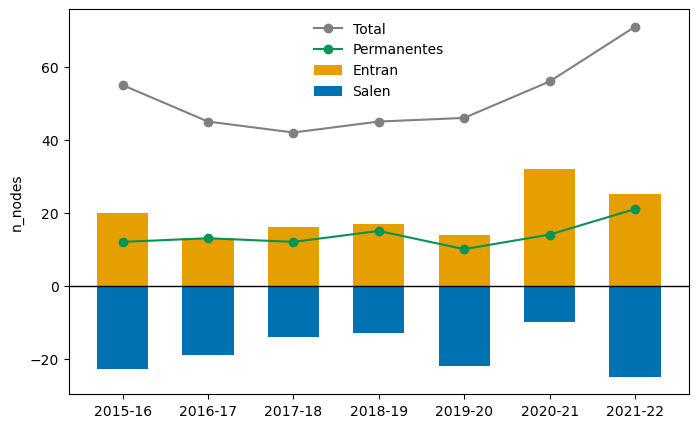

In [ ]:
node_df_site=Nodes_df.loc[site]

fig, ax = plt.subplots(figsize=(8,5))
plot_species_turnover(node_df_site, ax=ax, year_label_dict=year_label_dict,value_col='n_nodes')
plt.savefig("turnover.png", dpi=150, bbox_inches='tight')

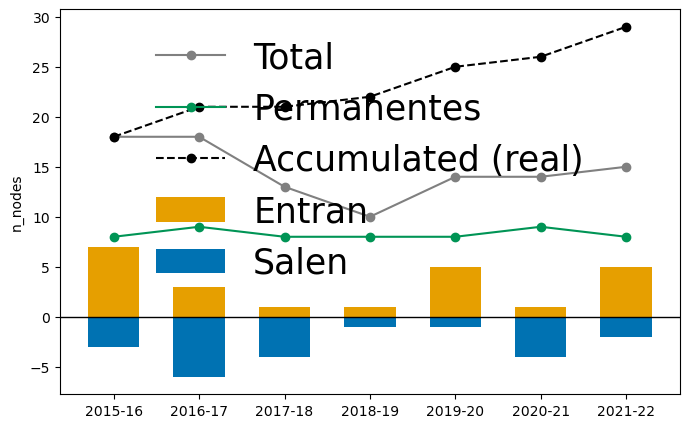

In [ ]:
site=Sites[0]
node_df_site=Nodes_df.loc[site]

fig, ax = plt.subplots(figsize=(8,5))

ax = plot_species_turnover(node_df_site, ax=ax, year_label_dict=year_label_dict,value_col='n_nodes',in_metric='P2', out_metric='P1', permanent_metric='PP')
plot_species_accumulation_curve(
    Ilist.loc[site],           # tus datos crudos (Pollinator_gen_sp/Plant_gen_sp/Frequency)
    ax=ax,
    species_col='Plant_gen_sp',   # o 'Plant_gen_sp' para plantas
    year_col='Year',                   # ajusta al nombre real de tu columna de año
    years=None                         # si lo dejas None, usa los años unicos de long_df_site
)

ax.legend(frameon=False)
plt.savefig("turnover_plants.png", dpi=150, bbox_inches='tight')

In [ ]:
def plot_species_turnover(df_site, ax=None, figsize=(8, 5),
                           in_metric='A2', out_metric='A1', permanent_metric='PA',
                           in_color='#E69F00', out_color='#0072B2',
                           total_color='gray', permanent_color='#009455',
                           year_col='year', metric_col='metric', value_col='n_nodes',
                           bar_width=0.6, marker_size=6, rotate_years=0,
                           year_label_dict=None, fontsize=20, show_legend=True):
    """
    Turnover de especies (p.ej. polinizadores) por año, para UN sitio.
 
    Eje x: años. Para cada año:
      - Barra hacia ARRIBA: numero de especies que ENTRAN ese año (in_metric,
        por defecto 'A2' -- exclusivas del año 2 de esa transicion).
      - Barra hacia ABAJO (negativa): numero de especies que SALEN (out_metric,
        por defecto 'A1' -- exclusivas del año 1).
      - Punto GRIS conectado por linea: numero TOTAL de especies ese año
        (permanentes + entran + salen -- PA+A1+A2).
      - Punto de otro color conectado por linea: numero de especies
        PERMANENTES ese año (permanent_metric, por defecto 'PA').
 
    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID (p.ej. df.loc["sitio_1"]), con columnas o
        niveles year_col/metric_col/value_col -- salida de rewiring_freq_py
        (la segunda tabla, node_counts) apilada por año.
    in_metric, out_metric, permanent_metric : str
        Nombres de fila en metric_col a usar para entran/salen/permanentes.
        Por defecto para polinizadores: 'A2'/'A1'/'PA'. Para plantas usa
        'P2'/'P1'/'PP'.
    year_label_dict : dict o None
        {año: texto legible} para el eje x.
 
    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    if year_label_dict is None:
        year_label_dict = {}
 
    df_site = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
 
    years = sorted(df_site[year_col].unique())
    x = np.arange(len(years))
 
    def get_vals(metric):
        return np.array([
            df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
 
    in_vals = get_vals(in_metric)
    out_vals = get_vals(out_metric)
    permanent_vals = get_vals(permanent_metric)
    total_vals = permanent_vals + in_vals + out_vals
 
    ax.bar(x, in_vals, color=in_color, width=bar_width, label='Entran', zorder=2)
    ax.bar(x, -out_vals, color=out_color, width=bar_width, label='Salen', zorder=2)
 
    ax.plot(x, total_vals, '-o', color=total_color, markersize=marker_size,
            label='Total', zorder=3)
    ax.plot(x, permanent_vals, '-o', color=permanent_color, markersize=marker_size,
            label='Permanentes', zorder=3)
 
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([year_label_dict.get(y, y) for y in years], rotation=rotate_years, fontsize=fontsize)

    ax.set_ylabel(value_col, fontsize=fontsize)
    ax.tick_params(axis='y', labelsize=fontsize)
    if show_legend:
        ax.legend(frameon=False, fontsize=fontsize)
 
    return ax
 


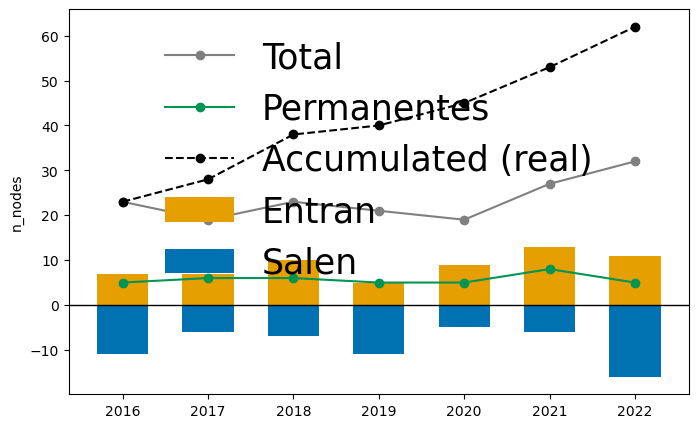

In [ ]:
site=Sites[7]
node_df_site=Nodes_df.loc[site]

ax = plot_species_turnover(node_df_site, value_col='n_nodes')
plot_species_accumulation_curve(
    Ilist.loc[site],           # tus datos crudos (Pollinator_gen_sp/Plant_gen_sp/Frequency)
    ax=ax,
    species_col='Pollinator_gen_sp',   # o 'Plant_gen_sp' para plantas
    year_col='Year',                   # ajusta al nombre real de tu columna de año
    years=None                         # si lo dejas None, usa los años unicos de long_df_site
)

ax.legend(frameon=False)

In [ ]:
def plot_species_accumulation_curve(
        long_df_site, ax, species_col='Pollinator_gen_sp', year_col='Year',
        years=None, color='black', marker_size=6, linestyle='--', lw=1.5,
        label='Accumulated (real)', zorder=4):
    """
    Curva de acumulacion REAL de especies -- a diferencia de la
    aproximacion (sumar in_vals acumulados, que asume que ninguna especie
    reaparece), esta usa la IDENTIDAD real de cada especie: para cada año,
    calcula el conjunto UNION de todas las especies vistas desde el primer
    año hasta ese año (inclusive), y cuenta cuantas son. Si una especie
    desaparece y vuelve a aparecer mas tarde, NO se cuenta dos veces --
    la curva es exacta, no una cota superior aproximada.
 
    Pensada para superponerse sobre plot_species_turnover: le pasas el
    mismo `ax` que devolvio esa funcion, y dibuja la curva acumulada
    encima, en el mismo eje.
 
    Parameters
    ----------
    long_df_site : pd.DataFrame
        Datos CRUDOS (no agregados en conteos), ya filtrados a UN Site_ID
        -- una fila por interaccion observada, con una columna con el
        nombre de la especie (species_col) y una columna de año (year_col).
    ax : matplotlib Axes
        El eje YA CREADO por plot_species_turnover, sobre el que se dibuja
        esta curva encima -- NO crea una figura nueva.
    species_col : str
        Columna con el nombre de la especie -- 'Pollinator_gen_sp' (por
        defecto) o 'Plant_gen_sp'.
    year_col : str
        Columna de año en long_df_site.
    years : list o None
        Los años a usar en el eje x, EN EL MISMO ORDEN que usa el grafico
        base -- para que las posiciones x=0,1,2... coincidan. Si None, se
        calculan los años únicos de long_df_site (ordenados).
 
    Devuelve
    -------
    ax, cumulative_counts
    """
    df = long_df_site.reset_index() if long_df_site.index.nlevels > 1 or long_df_site.index.name is not None else long_df_site.copy()
 
    if years is None:
        years = sorted(df[year_col].unique())
 
    seen = set()
    cumulative_counts = []
    for yr in years:
        yr_species = set(df.loc[df[year_col] == yr, species_col].unique())
        seen |= yr_species
        cumulative_counts.append(len(seen))
 
    x = np.arange(len(years))
    ax.plot(x[1:]-1, cumulative_counts[1:], linestyle=linestyle, marker='o', color=color,
        markersize=marker_size, lw=lw, label=label, zorder=zorder)
 
    return ax, cumulative_counts
 


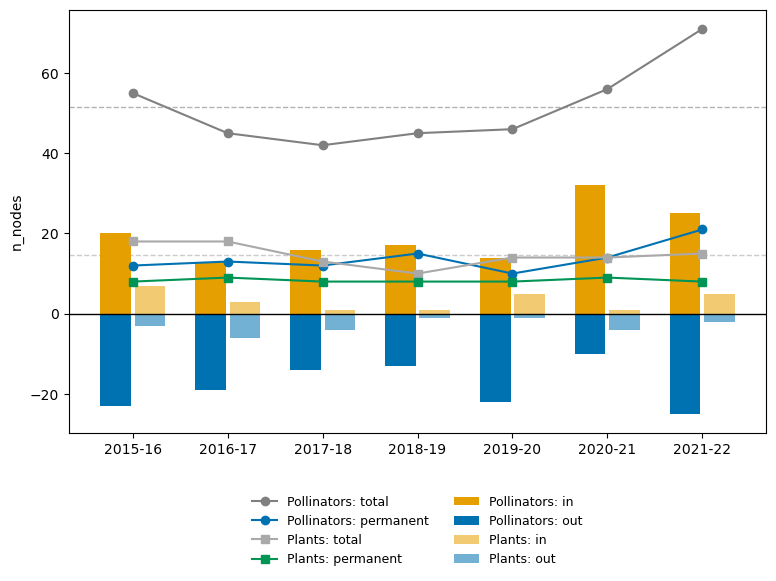

In [ ]:
fig, ax = plt.subplots(figsize=(9,5.5))
plot_species_turnover_combined(node_df_site, ax=ax, year_label_dict=year_label_dict, value_col='n_nodes')
plt.savefig("turnover_combined.png", dpi=150, bbox_inches='tight')

In [ ]:
def plot_species_turnover_combined(
        df_site, ax=None, figsize=(9, 5),
        poll_in_metric='A2', poll_out_metric='A1', poll_permanent_metric='PA',
        plant_in_metric='P2', plant_out_metric='P1', plant_permanent_metric='PP',
        poll_in_color='#E69F00', poll_out_color='#0072B2',
        poll_total_color='gray', poll_permanent_color='#0072B2',
        plant_in_color='#F1CA72', plant_out_color='#72B1D4',
        plant_total_color='darkgray', plant_permanent_color='#009455',
        bar_width=0.32, bar_offset=0.18, marker_size=6,
        year_col='year', metric_col='metric', value_col='n_nodes',
        rotate_years=0, year_label_dict=None, fontsize=10,
        show_mean_line=True, show_legend=True):
    """
    Version COMBINADA de plot_species_turnover: polinizadores Y plantas en el
    MISMO grafico, con las barras de cada grupo desplazadas ligeramente a
    izquierda/derecha dentro de cada año (dodge), para que no se solapen.

    Para cada año:
      - Polinizadores (desplazados a la IZQUIERDA de x): barra A2 arriba,
        A1 abajo.
      - Plantas (desplazadas a la DERECHA de x): barra P2 arriba, P1 abajo.
      - Lineas de puntos (SIN desplazar, en el centro x del año): total y
        permanentes de CADA grupo -- 4 lineas en total (poll. total, poll.
        permanentes, plant. total, plant. permanentes).

    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID, con year/metric/value_col -- debe contener
        tanto las metricas de polinizadores (PA/A1/A2) como las de plantas
        (PP/P1/P2) en la misma tabla.
    bar_offset : float
        Distancia horizontal (en unidades de x) entre el grupo polinizadores
        y el grupo plantas, a cada lado del año.
    bar_width : float
        Ancho de cada barra individual (mas estrecha que en la version de un
        solo grupo, porque ahora hay 2 grupos por año).
    show_mean_line : bool
        Si True, dibuja la linea discontinua con la media del total de CADA
        grupo (2 lineas discontinuas).

    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    if year_label_dict is None:
        year_label_dict = {}

    df_site = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()

    years = sorted(df_site[year_col].unique())
    x = np.arange(len(years))

    def get_vals(metric):
        return np.array([
            df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])

    poll_in = get_vals(poll_in_metric)
    poll_out = get_vals(poll_out_metric)
    poll_permanent = get_vals(poll_permanent_metric)
    poll_total = poll_permanent + poll_in + poll_out

    plant_in = get_vals(plant_in_metric)
    plant_out = get_vals(plant_out_metric)
    plant_permanent = get_vals(plant_permanent_metric)
    plant_total = plant_permanent + plant_in + plant_out

    x_poll = x - bar_offset
    x_plant = x + bar_offset

    # --- barras, desplazadas a cada lado ---
    ax.bar(x_poll, poll_in, color=poll_in_color, width=bar_width, zorder=2,
           label='Pollinators: in')
    ax.bar(x_poll, -poll_out, color=poll_out_color, width=bar_width, zorder=2,
           label='Pollinators: out')
    ax.bar(x_plant, plant_in, color=plant_in_color, width=bar_width, zorder=2,
           label='Plants: in')
    ax.bar(x_plant, -plant_out, color=plant_out_color, width=bar_width, zorder=2,
           label='Plants: out')

    # --- lineas de puntos, en el centro (sin desplazar) ---
    ax.plot(x, poll_total, '-o', color=poll_total_color, markersize=marker_size,
            zorder=3, label='Pollinators: total')
    ax.plot(x, poll_permanent, '-o', color=poll_permanent_color, markersize=marker_size,
            zorder=3, label='Pollinators: permanent')
    ax.plot(x, plant_total, '-s', color=plant_total_color, markersize=marker_size,
            zorder=3, label='Plants: total')
    ax.plot(x, plant_permanent, '-s', color=plant_permanent_color, markersize=marker_size,
            zorder=3, label='Plants: permanent')

    if show_mean_line:
        ax.axhline(poll_total.mean(), color=poll_total_color, linestyle='--', lw=1, alpha=0.6, zorder=1)
        ax.axhline(plant_total.mean(), color=plant_total_color, linestyle='--', lw=1, alpha=0.6, zorder=1)

    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([year_label_dict.get(y, y) for y in years], rotation=rotate_years, fontsize=fontsize)
    ax.set_ylabel(value_col, fontsize=fontsize)
    ax.tick_params(axis='y', labelsize=fontsize)
    if show_legend:
        ax.legend(frameon=False, fontsize=fontsize - 1, ncol=2, loc='upper center',
                  bbox_to_anchor=(0.5, -0.12))

    return ax

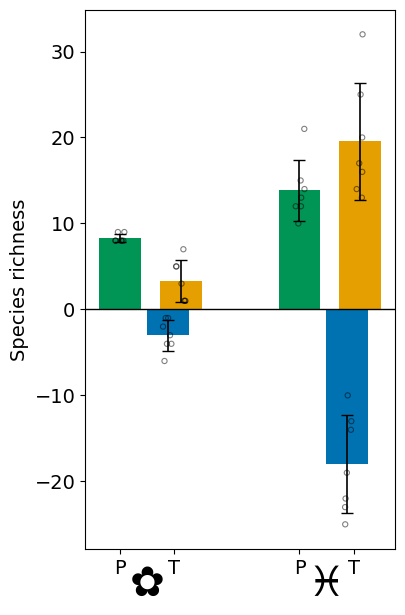

In [ ]:
fig, ax = plt.subplots(figsize=(4,7))
plot_species_summary_single(node_df_site, value_col='n_nodes', ax=ax)
plt.savefig("summary_single.png", dpi=150, bbox_inches='tight')

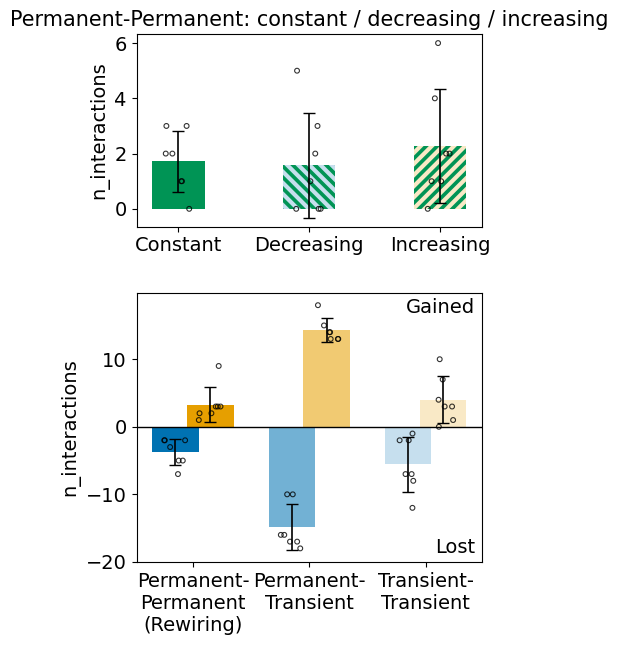

In [ ]:
fig, (ax_top, ax_bottom) = plot_interactions_summary(df_site, value_col='n_interactions')
plt.savefig("interactions_summary.png", dpi=150, bbox_inches='tight')

In [ ]:
nodes_df

,metric,n_species
0,PA,12
1,PP,8
2,A1,23
3,P1,3
4,A2,20
5,P2,7


In [ ]:
site=Sites[0] 
fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq) = plot_species_and_interactions_summary(
    Nodes_df.loc[site],   # tu tabla de especies, filtrada al sitio
    Changes_df.loc[site],        # tu tabla de interacciones, filtrada al sitio
    figsize=(15, 10),
    species_kwargs={'value_col': 'n_nodes'},
    interactions_kwargs={'value_col': 'n_interactions'},
    frequency_kwargs={'freq_col': 'freq_interactions', 'n_col': 'n_interactions'}
)
plt.savefig("composite.png", dpi=150, bbox_inches='tight')

NameError: name 'Nodes_df' is not defined

/home/gato/ownCloud/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:2237: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


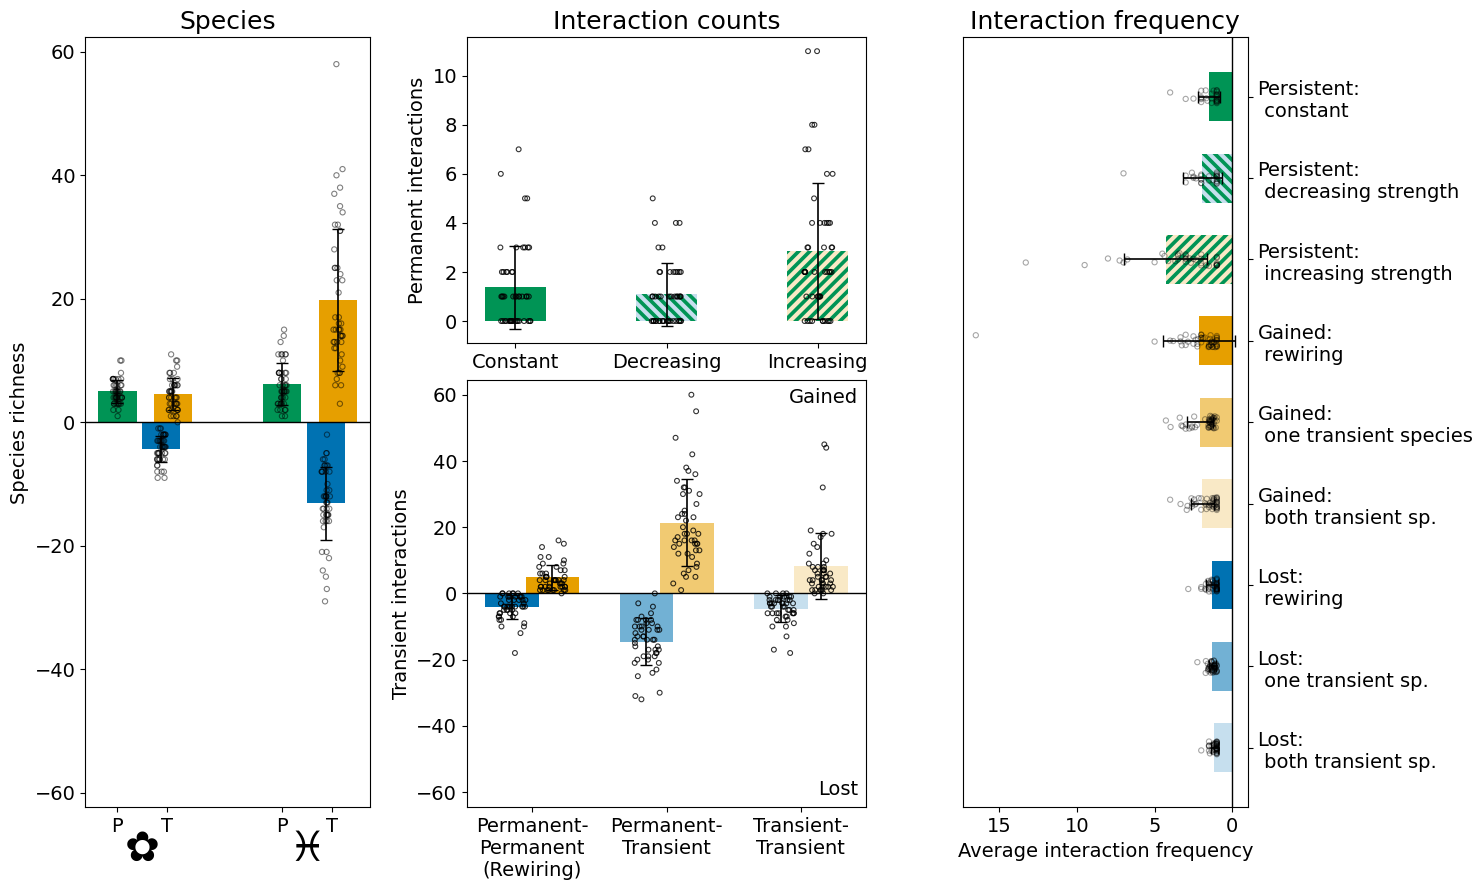

In [32]:
site=Sites[0] 
fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq) = plot_species_and_interactions_summary(
    Nodes_df,#.loc[site],   # tu tabla de especies, filtrada al sitio
    Changes_df,#.loc[site],        # tu tabla de interacciones, filtrada al sitio
    figsize=(15, 10),
    species_kwargs={'value_col': 'n_nodes'},
    interactions_kwargs={'value_col': 'n_interactions'},
    frequency_kwargs={'freq_col': 'freq_interactions', 'n_col': 'n_interactions'}
)
plt.savefig("composite_allnet.png", dpi=150, bbox_inches='tight')

In [17]:
def plot_species_summary_single(
        df_site, value_col='n_nodes', ax=None, figsize=(4.5, 7),
        year_col='year', metric_col='metric',
        plant_permanent_metric='PP', poll_permanent_metric='PA',
        plant_in_metric='P2', plant_out_metric='P1',
        poll_in_metric='A2', poll_out_metric='A1',
        plant_color='#009455', poll_color='#009455',
        plant_in_color='#E69F00', plant_out_color='#0072B2',
        poll_in_color='#E69F00', poll_out_color='#0072B2',
        within_gap=0.65, between_gap=1.5,
        bar_width=0.5, updown_offset=0.08, capsize=4, fontsize=14,
        show_points=True, point_color='black', point_alpha=0.5,
        point_size=14, jitter=0.06,
        plant_icon='\u273F', animal_icon='\u2653',
        icon_fontsize=30, icon_y=-0.03):
    """
    Version de UN SOLO PANEL de plot_species_summary: las 4 categorias
    (Permanent Plants, Transient Plants, Permanent Animals, Transient Animals)
    en el MISMO eje x, en vez de dos paneles separados.

    Espaciado: Permanent-Transient DENTRO del mismo grupo (plantas o animales)
    quedan mas cerca entre si (within_gap); el hueco ENTRE el grupo de plantas
    y el de animales es mayor (between_gap) -- para que se lean como dos
    "bloques" claramente separados.

    Cada categoria "Permanent" es una barra simple (media +- std a traves de
    los años). Cada categoria "Transient" es una barra divergente (entra
    hacia arriba, sale hacia abajo, ligeramente desplazadas entre si via
    updown_offset), igual que en el panel inferior de plot_species_summary.

    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID, con year/metric/value_col.
    within_gap : float
        Distancia en x entre la barra "Permanent" y la "Transient" del MISMO
        grupo (plantas o animales).
    between_gap : float
        Distancia en x entre el grupo de plantas y el grupo de animales
        (deberia ser mayor que within_gap).
    show_points : bool
        Superpone los valores individuales (un punto por año) con jitter.
    plant_icon, animal_icon : str
        Caracter Unicode a mostrar debajo de cada bloque de etiquetas.
        Por defecto plant_icon='\u273F', animal_icon='\u2653'
    icon_fontsize : float
        Tamaño de los iconos.
    icon_y : float
        Posicion vertical de los iconos, en fraccion del eje (coordenadas
        de ejes, no de datos) -- mas negativo = mas abajo, para dejar
        hueco a las xticklabels que ya estan debajo del eje.

    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
    rng = np.random.default_rng(0)

    def vals(metric):
        return df_flat.loc[df_flat[metric_col] == metric, value_col]

    def scatter_points(x0, values, sign=1):
        if not show_points or len(values) == 0:
            return
        jitter_x = x0 + rng.uniform(-jitter, jitter, size=len(values))
        ax.scatter(jitter_x, sign * values.values, facecolors='none', edgecolors=point_color,
                   alpha=point_alpha, s=point_size, linewidths=0.8, zorder=4)

    # ------------------------------------------------------------------
    # posiciones en x: PP -- (within_gap) -- transient_plants -- (between_gap) -- PA -- (within_gap) -- transient_animals
    # ------------------------------------------------------------------
    x_pp = 0
    x_pt = x_pp + within_gap
    x_pa = x_pt + between_gap
    x_at = x_pa + within_gap

    # --- Permanent Plants ---
    pp_vals = vals(plant_permanent_metric)
    ax.bar(x_pp, pp_vals.mean(), yerr=pp_vals.std(), color=plant_color, width=bar_width,
           capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
    scatter_points(x_pp, pp_vals)

    # --- Transient Plants (P2 arriba, P1 abajo) ---
    p2_vals = vals(plant_in_metric)
    p1_vals = vals(plant_out_metric)
    x_p2 = x_pt + updown_offset
    x_p1 = x_pt - updown_offset
    ax.bar(x_p2, p2_vals.mean(), yerr=p2_vals.std(), color=plant_in_color, width=bar_width,
           capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
    ax.bar(x_p1, -p1_vals.mean(), yerr=p1_vals.std(), color=plant_out_color, width=bar_width,
           capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
    scatter_points(x_p2, p2_vals, sign=1)
    scatter_points(x_p1, p1_vals, sign=-1)

    # --- Permanent Animals ---
    pa_vals = vals(poll_permanent_metric)
    ax.bar(x_pa, pa_vals.mean(), yerr=pa_vals.std(), color=poll_color, width=bar_width,
           capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
    scatter_points(x_pa, pa_vals)

    # --- Transient Animals (A2 arriba, A1 abajo) ---
    a2_vals = vals(poll_in_metric)
    a1_vals = vals(poll_out_metric)
    x_a2 = x_at + updown_offset
    x_a1 = x_at - updown_offset
    ax.bar(x_a2, a2_vals.mean(), yerr=a2_vals.std(), color=poll_in_color, width=bar_width,
           capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
    ax.bar(x_a1, -a1_vals.mean(), yerr=a1_vals.std(), color=poll_out_color, width=bar_width,
           capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
    scatter_points(x_a2, a2_vals, sign=1)
    scatter_points(x_a1, a1_vals, sign=-1)

    ax.axhline(0, color='black', lw=1)
    ax.set_xticks([x_pp, x_pt, x_pa, x_at])
    ax.set_xticklabels(['P', 'T',
                         'P', 'T'], fontsize=fontsize)
    ax.set_ylabel("Species richness", fontsize=fontsize)
    ax.tick_params(axis='y', labelsize=fontsize)

    # iconos debajo de cada bloque (planta bajo el par Permanent/Transient
    # Plants, animal bajo el par Permanent/Transient Animals), centrados.
    # transform=get_xaxis_transform() -- x en coordenadas de DATOS, y en
    # fraccion del eje (0=borde inferior del axes), asi el icono se coloca
    # debajo de las xticklabels independientemente del rango de datos.
    x_plant_center = (x_pp + x_pt) / 2
    x_animal_center = (x_pa + x_at) / 2
    ax.text(x_plant_center, icon_y, plant_icon, fontsize=icon_fontsize,
            ha='center', va='top', transform=ax.get_xaxis_transform())
    ax.text(x_animal_center, icon_y, animal_icon, fontsize=icon_fontsize,
            ha='center', va='top', transform=ax.get_xaxis_transform())


    return ax

In [ ]:
def plot_diverging_bars_mean_error(df, value_col='freq_sum', ax=None, figsize=(5, 5),
                                    loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
                                    gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
                                    category_labels=('Permanent-\nPermanent', 'Permanent-\nTransient', 'Transient-\nTransient'),
                                    loss_colors=('#C6DFEE', '#72B1D4', '#0072B2'),
                                    gain_colors=('#F9E9C6', '#F1CA72', '#E69F00'),
                                    year_col='year', metric_col='metric', site_level='Site_ID',
                                    bar_width=0.5, updown_offset=0.15, capsize=4, fontsize=10,
                                    show_points=True, point_color='black',
                                    point_alpha=0.35, point_size=12, jitter=0.1):
    """
    Grafico de barras con barra de error. Eje x: las 3 categorias de nodo
    (Permanent-Permanent / Permanent-Transient / Transient-Transient), NO los
    años. Para cada categoria hay DOS barras (perdida hacia abajo, ganancia
    hacia arriba), SIN apilar entre si -- y ligeramente DESPLAZADAS entre si
    (perdida a la izquierda, ganancia a la derecha) via updown_offset, para
    que no queden perfectamente alineadas.

    Altura de cada barra = media de value_col a traves de TODAS las filas de
    df para esa metrica (si pasas el df completo, sitios x años; si pasas
    df de un solo sitio, la media es solo a traves de los años de ese sitio).
    Barra de error = desviacion estandar de esa misma coleccion.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame con Site_ID/year/metric como MultiIndex o columnas. Puede
        ser el df completo (todos los sitios) o ya filtrado a un sitio.
    loss_metrics, gain_metrics : tuple de 3 str
        En el orden (CN, 1-nuevo, ambas-nuevas).
    category_labels : tuple de 3 str
        Etiquetas del eje x, mismo orden que loss_metrics/gain_metrics.
    loss_colors, gain_colors : tuple de 3 str
        Un color por categoria (mismo orden que loss_metrics/gain_metrics).
    updown_offset : float
        Desplazamiento horizontal entre la barra de perdida (se mueve a la
        IZQUIERDA) y la de ganancia (se mueve a la DERECHA) dentro de cada
        categoria. 0 = sin desplazamiento (alineadas).
    show_points : bool
        Si True (por defecto), superpone los valores individuales con jitter.

    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)

    df_flat = df.reset_index() if df.index.nlevels > 1 or df.index.name is not None else df.copy()

    x = np.arange(len(loss_metrics))

    def mean_std_vals(metric):
        vals = df_flat.loc[df_flat[metric_col] == metric, value_col]
        return vals.mean(), vals.std(), vals.values

    loss_stats = [mean_std_vals(m) for m in loss_metrics]
    gain_stats = [mean_std_vals(m) for m in gain_metrics]

    rng = np.random.default_rng(0)  # semilla fija -- jitter reproducible entre llamadas

    for i in range(len(x)):
        loss_mean, loss_std, loss_vals = loss_stats[i]
        gain_mean, gain_std, gain_vals = gain_stats[i]

        x_loss = x[i] - updown_offset
        x_gain = x[i] + updown_offset

        ax.bar(x_loss, -loss_mean, yerr=loss_std, color=loss_colors[i],
               width=bar_width, capsize=capsize,
               label='Lost' if i == 0 else None,
               error_kw={'elinewidth': 1.2}, zorder=2)
        ax.bar(x_gain, gain_mean, yerr=gain_std, color=gain_colors[i],
               width=bar_width, capsize=capsize,
               label='Gained' if i == 0 else None,
               error_kw={'elinewidth': 1.2}, zorder=2)

        if show_points:#ax_top.scatter(jitter_x, m_vals, facecolors='none', edgecolors=point_color, alpha=point_alpha, s=point_size, linewidths=0.8, zorder=3)
            jitter_x_loss = x_loss + rng.uniform(-jitter, jitter, size=len(loss_vals))
            jitter_x_gain = x_gain + rng.uniform(-jitter, jitter, size=len(gain_vals))
            ax.scatter(jitter_x_loss, -loss_vals, facecolors='none', edgecolors=point_color, alpha=point_alpha, s=point_size, linewidths=0.8, zorder=3)
            ax.scatter(jitter_x_gain, gain_vals, facecolors='none', edgecolors=point_color, alpha=point_alpha, s=point_size, linewidths=0.8, zorder=3)

    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(category_labels, fontsize=fontsize)
    ax.set_ylabel(value_col, fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=fontsize)
    ax.legend(frameon=False, fontsize=fontsize)

    return ax

In [ ]:
def plot_interactions_summary(
        df_site, value_col='freq_sum', figsize=(5, 7), height_ratios=(1, 1.4),
        year_col='year', metric_col='metric',
        constant_metrics=('CN_CI', 'CN_DI', 'CN_II'),
        constant_facecolor='#009455',
        constant_edgecolors=(None, '#C6DFEE', '#F9E9C6'),
        constant_hatches=(None, '\\\\\\', '///'),
        hatch_linewidth=3.0, top_bar_width=0.4,
        loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
        gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
        category_labels=('Permanent-\nPermanent\n(Rewiring)', 'Permanent-\nTransient', 'Transient-\nTransient'),
        loss_colors=('#0072B2', '#72B1D4', '#C6DFEE'),
        gain_colors=('#E69F00', '#F1CA72', '#F9E9C6'),
        bottom_bar_width=0.4, updown_offset=0.15, capsize=4, fontsize=14,
        show_points=True, point_color='black', point_alpha=0.8,
        point_size=12, jitter=0.1, ax_top=None, ax_bottom=None):
    """
    Figura de UN sitio (df_site) con DOS paneles, para las INTERACCIONES
    (a diferencia de plot_species_summary_single, que es para especies/nodos):
 
      - panel superior: 3 barras SIN apilar -- CN_CI (verde liso), CN_DI
        (verde + rayas azules), CN_II (verde + rayas amarillas) -- media +-
        std a traves de los AÑOS de este sitio (df_site ya viene de un
        unico Site_ID).
      - panel inferior: plot_diverging_bars_mean_error aplicada a df_site
        -- como solo se le pasa un sitio, la media +- std tambien es solo
        a traves de los años de ESE sitio. Perdida (azul) desplazada a la
        izquierda, ganancia (amarillo) desplazada a la derecha, dentro de
        cada una de las 3 categorias de nodo (Permanent-Permanent /
        Permanent-Transient / Transient-Transient).
 
    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID, con year/metric/value_col para todos los
        años de ese sitio.
    constant_metrics : tuple de 3 str
        (constante, disminuye, aumenta) -- CN_CI/CN_DI/CN_II por defecto.
    constant_edgecolors, constant_hatches : tuple de 3 (str o None)
        Estilo de cada barra del panel superior, mismo orden que
        constant_metrics. None = sin rayas (solo el color solido).
    ax_top, ax_bottom : matplotlib Axes o None
        Si se pasan AMBOS, se dibuja sobre esos ejes en vez de crear una
        figura nueva -- util para componer esta figura dentro de otra mas
        grande (p.ej. junto a plot_species_summary_single). Si se dejan en
        None (por defecto), se crea una figura nueva de 2 paneles como
        siempre.
 
    Devuelve
    -------
    Si ax_top/ax_bottom son None: fig, (ax_top, ax_bottom)
    Si se pasaron ax_top/ax_bottom: (ax_top, ax_bottom) -- sin fig, porque
    la figura ya existia de antes (la creo quien llama).
    """
    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
 
    def mean_std_vals(metric):
        vals = df_flat.loc[df_flat[metric_col] == metric, value_col]
        return vals.mean(), vals.std(), vals.values
 
    created_own_fig = ax_top is None and ax_bottom is None
    if created_own_fig:
        fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=figsize,
                                                 gridspec_kw={'height_ratios': height_ratios})
 
    # ------------------------------------------------------------------
    # panel superior: CN_CI / CN_DI / CN_II, SIN apilar, media +- std sobre años
    # ------------------------------------------------------------------
    import matplotlib as mpl
    mpl.rcParams['hatch.linewidth'] = hatch_linewidth
 
    rng = np.random.default_rng(0)
    x_top = np.arange(len(constant_metrics))
 
    for i, metric in enumerate(constant_metrics):
        m_mean, m_std, m_vals = mean_std_vals(metric)
        edgecolor = constant_edgecolors[i]
        hatch = constant_hatches[i]
        ax_top.bar(x_top[i], m_mean, yerr=m_std, facecolor=constant_facecolor,
                   edgecolor=edgecolor if edgecolor else constant_facecolor,
                   hatch=hatch, linewidth=0, width=top_bar_width,
                   capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
        if show_points:
            jitter_x = x_top[i] + rng.uniform(-jitter, jitter, size=len(m_vals))
            ax_top.scatter(jitter_x, m_vals, facecolors='none', edgecolors=point_color, alpha=point_alpha, s=point_size, linewidths=0.8, zorder=3)
                           #ax.scatter(jitter_x, sign * values.values, facecolors='none', edgecolors=point_color, alpha=point_alpha, s=point_size, linewidths=0.8, zorder=4)
 
    ax_top.set_xticks(x_top)
    ax_top.set_xticklabels(['Constant','Decreasing', 'Increasing'], fontsize=fontsize)
    ax_top.set_ylabel(value_col, fontsize=fontsize)
    ax_top.tick_params(axis='y', labelsize=fontsize)
    ax_top.set_title('Permanent-Permanent: constant / decreasing / increasing', fontsize=fontsize + 1)
 
    # ------------------------------------------------------------------
    # panel inferior: plot_diverging_bars_mean_error, reutilizada tal cual
    # ------------------------------------------------------------------
    plot_diverging_bars_mean_error(
        df_flat, value_col=value_col, ax=ax_bottom,
        loss_metrics=loss_metrics, gain_metrics=gain_metrics,
        category_labels=category_labels, loss_colors=loss_colors, gain_colors=gain_colors,
        year_col=year_col, metric_col=metric_col,
        bar_width=bottom_bar_width, updown_offset=updown_offset, capsize=capsize,
        fontsize=fontsize, show_points=show_points, point_color=point_color,
        point_alpha=point_alpha, point_size=point_size, jitter=jitter)
 
    # en vez de la leyenda automatica (arriba a la izq), colocamos "Lost
    # interactions" abajo a la derecha (junto a las barras de perdida) y
    # "Gained interactions" arriba a la derecha (junto a las de ganancia)
    legend = ax_bottom.get_legend()
    if legend is not None:
        legend.remove()
    ax_bottom.text(0.98, 0.02, 'Lost', transform=ax_bottom.transAxes,
                   ha='right', va='bottom', fontsize=fontsize)
    ax_bottom.text(0.98, 0.98, 'Gained', transform=ax_bottom.transAxes,
                   ha='right', va='top', fontsize=fontsize)
    
    
    if created_own_fig:
        plt.tight_layout()
        return fig, (ax_top, ax_bottom)
    else:
        return ax_top, ax_bottom


In [ ]:
label_dict2={'CN_CI':'Persistent:\n constant', 'CN_DI':'Persistent:\n decreasing strength', 'CN_II': 'Persistent:\n increasing strength', 'CN_LI':'Lost:\n rewiring', 
'CN_GI': 'Gained:\n rewiring', 'L1N_LI':'Lost:\n one transient sp.', 'LBN_LI': 'Lost:\n both transient sp.', 
'G1N_GI':'Gained:\n one transient species', 'GBN_GI':'Gained:\n both transient sp.'}
def plot_interaction_frequency_bars(
        df_site, freq_col='freq_sum', n_col='n_interactions', ax=None, figsize=(6, 7),
        metrics=('CN_CI', 'CN_DI', 'CN_II', 'CN_GI', 'G1N_GI', 'GBN_GI', 'CN_LI', 'L1N_LI', 'LBN_LI'),
        metric_col='metric', year_col='year',
        colors=('#009455', '#009455', '#009455',
                '#E69F00', '#F1CA72', '#F9E9C6',
                '#0072B2', '#72B1D4', '#C6DFEE' ),
        edgecolors=(None, '#C6DFEE', '#F9E9C6', None, None, None, None, None, None),
        hatches=(None, '\\\\\\', '///', None, None, None, None, None, None),
        hatch_linewidth=3.0,
        label_dict=label_dict2, bar_height=0.6, capsize=4, fontsize=14,
        show_points=True, point_color='black', point_alpha=0.35,
        point_size=14, jitter=0.08):
    """
    Grafico de barras HORIZONTALES: frecuencia media por interaccion
    (freq_sum/n_interactions) de cada una de las 9 categorias, para UN sitio.
 
    Orden de arriba a abajo (por defecto): CN_CI, CN_DI, CN_II -- bloque
    permanente; CN_GI, G1N_GI, GBN_GI -- ganancias; CN_LI, L1N_LI, LBN_LI --
    perdidas.
 
    CN_DI y CN_II llevan el MISMO estilo de rayas (hatch) que en
    plot_interactions_summary: verde de fondo + rayas azules (CN_DI) o
    amarillas (CN_II), en vez de color solido.
 
    Eje y: las 9 categorias (metrics), con su etiqueta a la IZQUIERDA (layout
    estandar de barh). Eje x: frecuencia media por interaccion. Cada fila del
    df_site (un año, una categoria) aporta un valor freq_col/n_col para los
    puntos/barra de error; la barra en si es la razon AGREGADA (suma de
    freq_col entre suma de n_col, sumando todos los años).
 
    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID -- Changes_df.loc[site].
    freq_col, n_col : str
        Columnas a dividir (freq_col / n_col).
    metrics : tuple de 9 str
        Orden de las categorias de arriba a abajo en el eje y.
    colors : tuple de 9 str
        Color de fondo (facecolor) de cada categoria, mismo orden que metrics.
    edgecolors, hatches : tuple de 9 (str o None)
        Estilo de rayas por categoria, mismo orden que metrics. None = sin
        rayas (barra solida, usa solo el color de colors).
    hatch_linewidth : float
        Grosor de las rayas del hatch.
    label_dict : dict o None
        {codigo_metrica: texto legible} para las etiquetas del eje y.
 
    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    if label_dict is None:
        label_dict = {}
 
    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
    rng = np.random.default_rng(0)
 
    import matplotlib as mpl
    mpl.rcParams['hatch.linewidth'] = hatch_linewidth
 
    y = np.arange(len(metrics))
 
    means, stds, all_vals = [], [], []
    for metric in metrics:
        sub = df_flat.loc[df_flat[metric_col] == metric]
        vals = (sub[freq_col] / sub[n_col]).replace([np.inf, -np.inf], np.nan).dropna()
        all_vals.append(vals.values)
        stds.append(vals.std())
 
        # razon AGREGADA (suma de freq_col entre suma de n_col, sumando
        # todos los años) -- no es la media de las razones por año
        total_freq = sub[freq_col].sum()
        total_n = sub[n_col].sum()
        means.append(total_freq / total_n if total_n != 0 else np.nan)
 
    for i in range(len(metrics)):
        edgecolor = edgecolors[i]
        ax.barh(y[i], means[i], xerr=stds[i], facecolor=colors[i],
                edgecolor=edgecolor if edgecolor else colors[i],
                hatch=hatches[i], linewidth=0, height=bar_height,
                capsize=capsize, error_kw={'elinewidth': 1.2}, zorder=2)
 
    if show_points:
        for i, vals in enumerate(all_vals):
            jitter_y = y[i] + rng.uniform(-jitter, jitter, size=len(vals))
            ax.scatter(vals, jitter_y, facecolors='none', edgecolors=point_color,
                       alpha=point_alpha, s=point_size, linewidths=0.8, zorder=3)
 
    ax.set_yticks(y)
    ax.set_yticklabels([label_dict.get(m, m) for m in metrics], fontsize=fontsize)
    ax.yaxis.tick_right()
    ax.invert_yaxis()  # primera categoria de la lista arriba, no abajo
    ax.invert_xaxis()  # primera categoria de la lista arriba, no abajo
    ax.set_xlabel('Average interaction frequency', fontsize=fontsize)
    ax.tick_params(axis='x', labelsize=fontsize)
    ax.axvline(0, color='black', lw=1)
 
    return ax
 


In [ ]:
def plot_species_and_interactions_summary(
        node_changes_df_site, changes_df_site,
        figsize=(15, 7), width_ratios=(1, 1.4, 1), height_ratios=(1, 1.4),
        species_kwargs=None, interactions_kwargs=None, frequency_kwargs=None):
    """
    Figura compuesta de UN sitio: plot_species_summary_single a la IZQUIERDA
    (un unico panel), plot_interactions_summary en el CENTRO (dos paneles
    apilados), y plot_interaction_frequency_bars a la DERECHA (un unico
    panel, barras horizontales) -- reutilizando las tres funciones tal cual,
    sin duplicar logica.
 
    Parameters
    ----------
    node_changes_df_site : pd.DataFrame
        Ya filtrado a UN Site_ID -- tabla de turnover de ESPECIES/NODOS
        (PP/PA/P1/P2/A1/A2 en metric_col), la misma que usas para
        plot_species_summary_single (tu "node_changes_df").
    changes_df_site : pd.DataFrame
        Ya filtrado a UN Site_ID -- tabla de cambios de INTERACCIONES
        (CN_CI/CN_DI/CN_II/CN_LI/CN_GI/L1N_LI/LBN_LI/G1N_GI/GBN_GI en
        metric_col), la misma que usas para plot_interactions_summary
        (tu "Changes_df"). Se reutiliza TAMBIEN para el panel derecho
        (plot_interaction_frequency_bars) -- misma tabla, otra vista.
    width_ratios : (float, float, float)
        Ancho relativo columna izquierda (species) / centro (interactions) /
        derecha (frequency bars).
    height_ratios : (float, float)
        Alto relativo panel superior/inferior de la columna CENTRAL (se pasa
        tal cual a plot_interactions_summary). Las columnas izquierda y
        derecha ocupan el alto TOTAL (ambas filas) cada una.
    species_kwargs : dict o None
        Parametros extra para plot_species_summary_single (ademas de
        node_changes_df_site y ax) -- p.ej. {'value_col': 'n_nodes', ...}.
    interactions_kwargs : dict o None
        Parametros extra para plot_interactions_summary (ademas de
        changes_df_site, ax_top, ax_bottom) -- p.ej. {'value_col': 'freq_sum', ...}.
    frequency_kwargs : dict o None
        Parametros extra para plot_interaction_frequency_bars (ademas de
        changes_df_site y ax) -- p.ej. {'freq_col': 'freq_sum', 'n_col': 'n_interactions', ...}.
 
    Devuelve
    -------
    fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq)
    """
    if species_kwargs is None:
        species_kwargs = {}
    if interactions_kwargs is None:
        interactions_kwargs = {}
    if frequency_kwargs is None:
        frequency_kwargs = {}
 
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(2, 3, figure=fig, width_ratios=width_ratios,
                            height_ratios=height_ratios, wspace=0.3, hspace=0.1)
 
    ax_species = fig.add_subplot(gs[:, 0])     # columna izquierda, ambas filas
    ax_int_top = fig.add_subplot(gs[0, 1])     # columna central, fila superior
    ax_int_bottom = fig.add_subplot(gs[1, 1])  # columna central, fila inferior
    ax_freq = fig.add_subplot(gs[:, 2])        # columna derecha, ambas filas
 
    plot_species_summary_single(node_changes_df_site, ax=ax_species, **species_kwargs)
    plot_interactions_summary(changes_df_site, ax_top=ax_int_top, ax_bottom=ax_int_bottom,
                               **interactions_kwargs)
    plot_interaction_frequency_bars(changes_df_site, ax=ax_freq, **frequency_kwargs)
 
    ax_species.set_title("Species", fontsize=18)
    ax_int_top.set_title("Interaction counts", fontsize=18)
    ax_int_top.set_ylabel("Permanent interactions")
    ax_int_bottom.set_ylabel("Transient interactions")
    ax_freq.set_title("Interaction frequency", fontsize=18)
 
    ymin, ymax = ax_int_bottom.get_ylim()
    m = max(abs(ymin), abs(ymax))
    ax_int_bottom.set_ylim(-m, m)
 
    ymin, ymax = ax_species.get_ylim()
    m = max(abs(ymin), abs(ymax))
    ax_species.set_ylim(-m, m)
 
    plt.tight_layout()
 
    return fig, (ax_species, ax_int_top, ax_int_bottom, ax_freq)
 


In [ ]:
site=Sites[0]

/home/gato/ownCloud/Trabajo/colaboraciones/Rewiring Alfonso/Rwiring_manuscript_code/Functions.py:1379: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


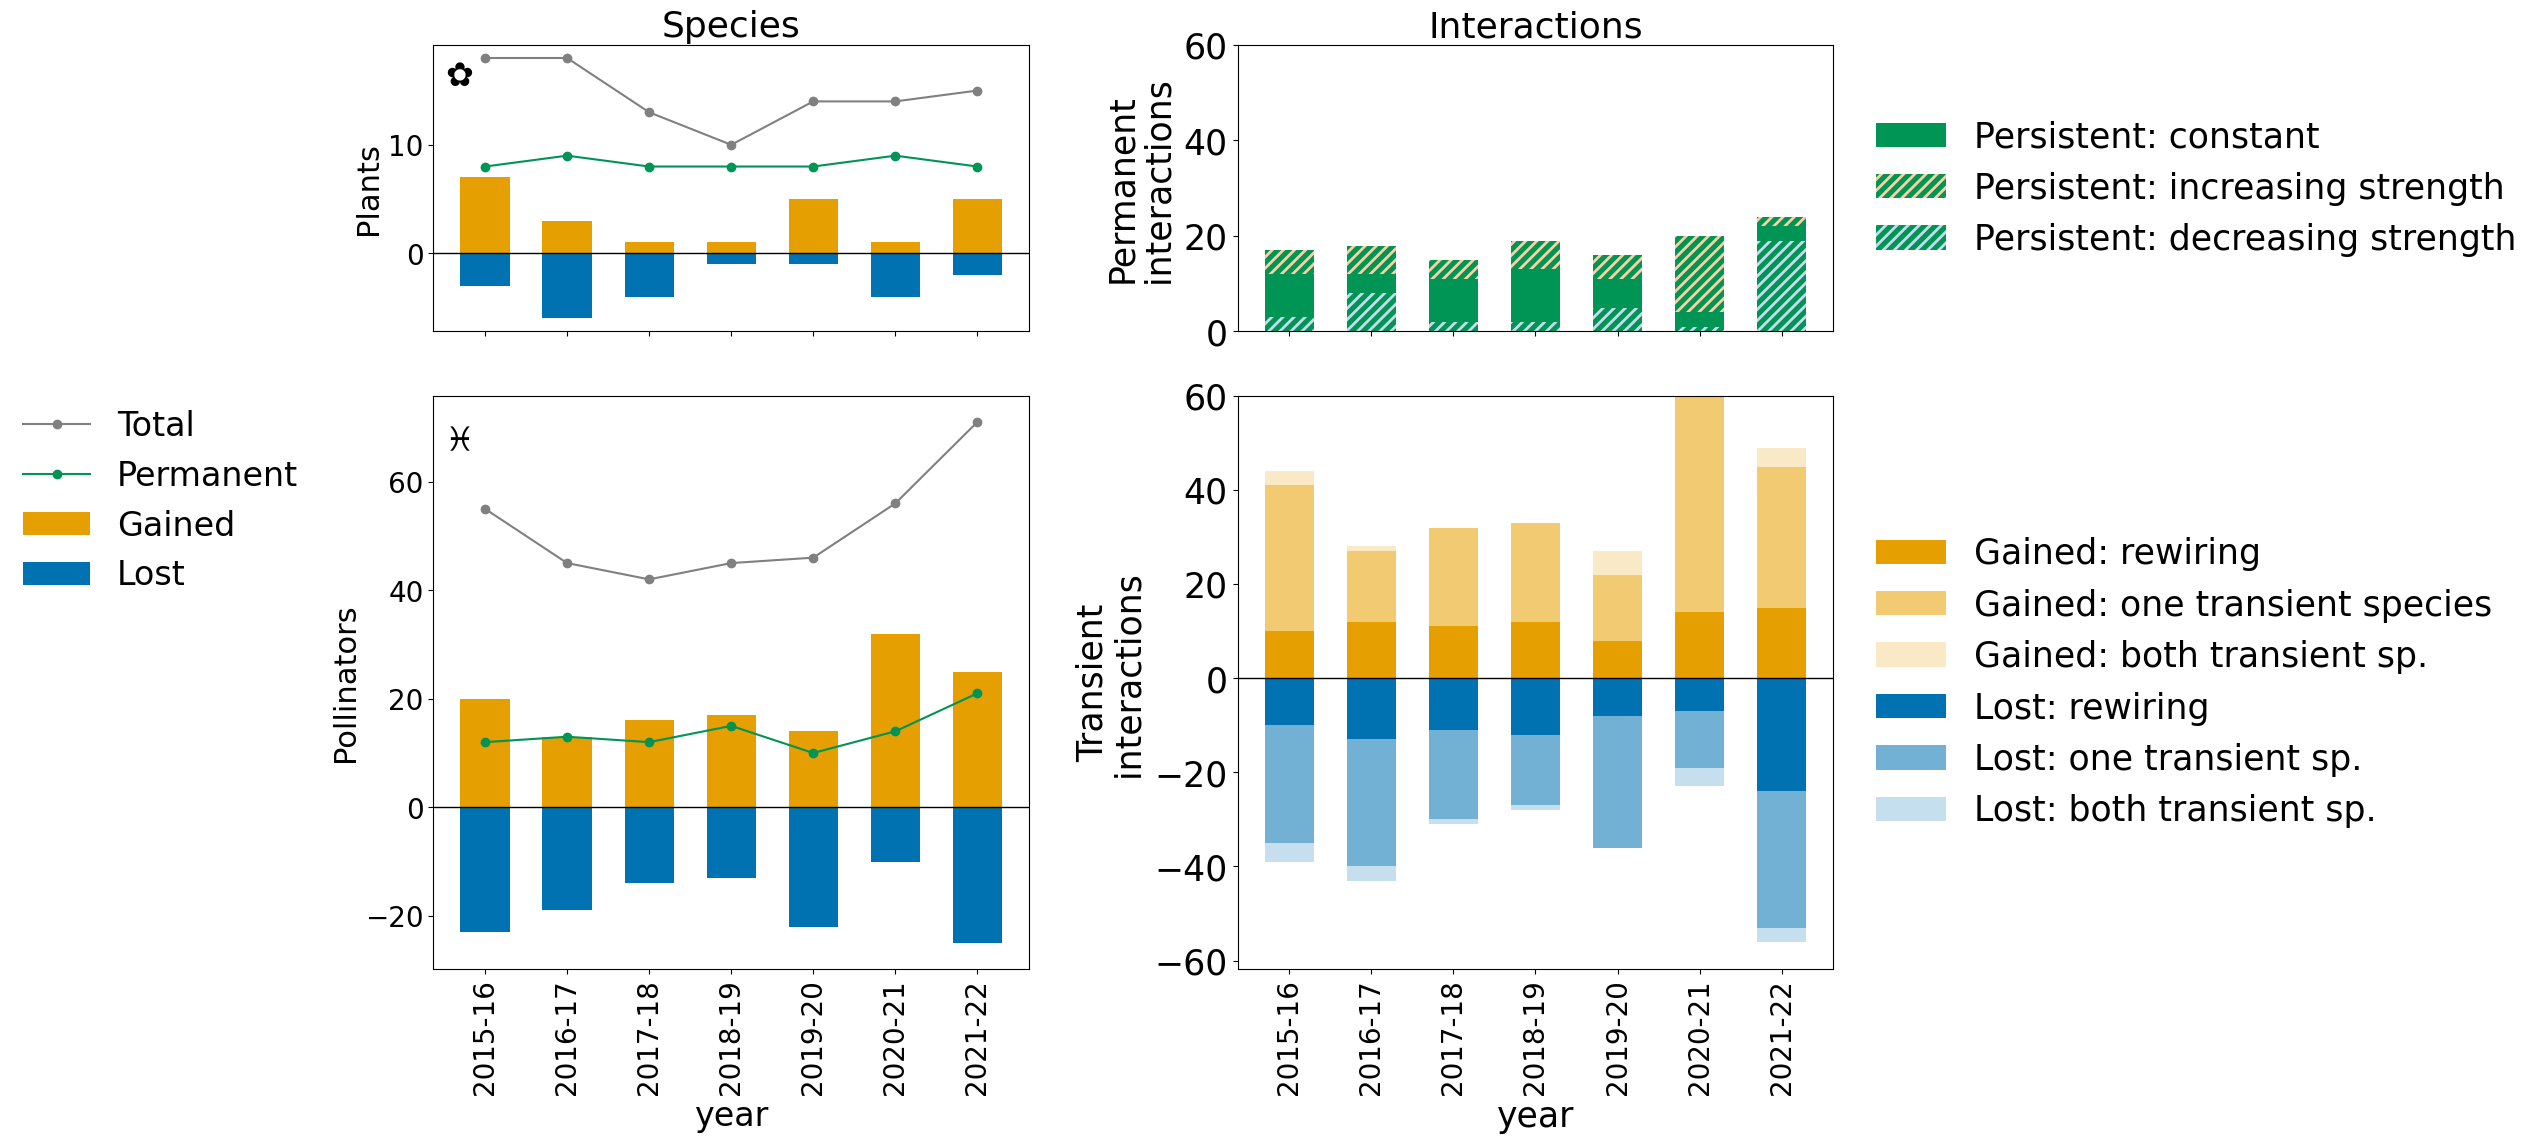

In [ ]:
fig, (ax_plants, ax_poll, ax_top, ax_bottom) = plot_species_and_turnover_summary(
    Nodes_df.loc[site],        # species 
    Changes_df.loc[site], # Changes_df del sitio
)

In [ ]:
def plot_species_turnover(df_site, ax=None, figsize=(8, 5),
                           in_metric='A2', out_metric='A1', permanent_metric='PA',
                           in_color='#E69F00', out_color='#0072B2',
                           total_color='gray', permanent_color='#009455',
                           year_col='year', metric_col='metric', value_col='n_nodes',
                           bar_width=0.6, marker_size=6, rotate_years=90,
                           year_label_dict=None, fontsize=20, show_legend=True):
    """
    Turnover de especies (p.ej. polinizadores) por año, para UN sitio.
 
    Eje x: años. Para cada año:
      - Barra hacia ARRIBA: numero de especies que ENTRAN ese año (in_metric,
        por defecto 'A2' -- exclusivas del año 2 de esa transicion).
      - Barra hacia ABAJO (negativa): numero de especies que SALEN (out_metric,
        por defecto 'A1' -- exclusivas del año 1).
      - Punto GRIS conectado por linea: numero TOTAL de especies ese año
        (permanentes + entran + salen -- PA+A1+A2).
      - Punto de otro color conectado por linea: numero de especies
        PERMANENTES ese año (permanent_metric, por defecto 'PA').
 
    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID (p.ej. df.loc["sitio_1"]), con columnas o
        niveles year_col/metric_col/value_col -- salida de rewiring_freq_py
        (la segunda tabla, node_counts) apilada por año.
    in_metric, out_metric, permanent_metric : str
        Nombres de fila en metric_col a usar para entran/salen/permanentes.
        Por defecto para polinizadores: 'A2'/'A1'/'PA'. Para plantas usa
        'P2'/'P1'/'PP'.
    year_label_dict : dict o None
        {año: texto legible} para el eje x.
 
    Devuelve
    -------
    ax
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    if year_label_dict is None:
        year_label_dict = {}
 
    df_site = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
 
    years = sorted(df_site[year_col].unique())
    x = np.arange(len(years))
 
    def get_vals(metric):
        return np.array([
            df_site.loc[(df_site[year_col] == yr) & (df_site[metric_col] == metric), value_col].sum()
            for yr in years
        ])
 
    in_vals = get_vals(in_metric)
    out_vals = get_vals(out_metric)
    permanent_vals = get_vals(permanent_metric)
    total_vals = permanent_vals + in_vals + out_vals
 
    ax.bar(x, in_vals, color=in_color, width=bar_width, label='Gained', zorder=2)
    ax.bar(x, -out_vals, color=out_color, width=bar_width, label='Lost', zorder=2)
 
    ax.plot(x, total_vals, '-o', color=total_color, markersize=marker_size,
            label='Total', zorder=3)
    ax.plot(x, permanent_vals, '-o', color=permanent_color, markersize=marker_size,
            label='Permanent', zorder=3)
 
    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels([year_label_dict.get(y, y) for y in years], rotation=rotate_years, fontsize=fontsize)

    ax.set_ylabel(value_col, fontsize=fontsize)
    ax.tick_params(axis='y', labelsize=fontsize)
    if show_legend:
        ax.legend(frameon=False, fontsize=fontsize)
 
    return ax

In [ ]:
def plot_diverging_bars_with_constant(df_site, value_col='n_interactions', figsize=(16, 15),
                                       height_ratios=(1, 2), match_scale=True,
                                       ylim_top=None,
                                       loss_metrics=('CN_LI', 'L1N_LI', 'LBN_LI'),
                                       gain_metrics=('CN_GI', 'G1N_GI', 'GBN_GI'),
                                       loss_colors=('#0072B2', '#72B1D4','#C6DFEE' ),
                                       gain_colors=('#E69F00', '#F1CA72','#F9E9C6' ),
                                       constant_metrics=('CN_DI', 'CN_CI', 'CN_II'),
                                       constant_facecolor='#009455',
                                       constant_edgecolors=('#C6DBEF', None, '#FDD0A2'),
                                       constant_hatches=('///', None, '///'),
                                       hatch_linewidth=2.0,
                                       year_col='year', metric_col='metric',
                                       rotate_years=90, year_label_dict=None,
                                       ax_top=None, ax_bottom=None,fontsize=20):
    """
    Figura de UN sitio con DOS paneles, eje x (año) compartido.
 
    NUEVO: acepta ax_top/ax_bottom externos -- si se pasan AMBOS, dibuja
    sobre esos ejes en vez de crear una figura nueva. Se corrige tambien
    el bug de year_label_dict usado sin ser parametro.
 
    Devuelve
    -------
    Si ax_top/ax_bottom son None: fig, (ax_top, ax_bottom)
    Si se pasaron: (ax_top, ax_bottom)
    """
    if year_label_dict is None:
        year_label_dict = {}
 
    created_own_fig = ax_top is None and ax_bottom is None
    if created_own_fig:
        fig, (ax_top, ax_bottom) = plt.subplots(
            2, 1, figsize=figsize, sharex=True,
            gridspec_kw={'height_ratios': height_ratios}
        )
 
    plot_constant_bars(df_site, value_col=value_col, ax=ax_top,
                        constant_metrics=constant_metrics,
                        constant_facecolor=constant_facecolor,
                        constant_edgecolors=constant_edgecolors,
                        constant_hatches=constant_hatches,
                        hatch_linewidth=hatch_linewidth,
                        year_col=year_col, metric_col=metric_col)
 
    plot_diverging_bars(df_site, value_col=value_col, ax=ax_bottom,
                         loss_metrics=loss_metrics, gain_metrics=gain_metrics,
                         loss_colors=loss_colors, gain_colors=gain_colors,
                         year_col=year_col, metric_col=metric_col)
 
    if ylim_top is not None:
        ax_top.set_ylim(*ylim_top)
    elif match_scale:
        ymax_bottom_positive = ax_bottom.get_ylim()[1]
        ax_top.set_ylim(0, ymax_bottom_positive)
 
    ax_top.yaxis.set_major_locator(MultipleLocator(20))
    ax_bottom.yaxis.set_major_locator(MultipleLocator(20))
 
    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site
    years = sorted(df_flat[year_col].unique())
    ax_bottom.set_xticklabels([year_label_dict.get(y, y) for y in years], rotation=rotate_years,fontsize=fontsize)
    ax_top.set_xlabel('')
 
    ax_top.set_ylabel('Permanent\n interactions')
    ax_bottom.set_ylabel('Transient\n interactions')
 
    if created_own_fig:
        plt.tight_layout()
        return fig, (ax_top, ax_bottom)
    else:
        return ax_top, ax_bottom
 


In [ ]:
def plot_species_and_turnover_summary(
        df_site_species, df_site_interactions,
        figsize=(20, 12), height_ratios=(1, 2),
        plant_kwargs=None, pollinator_kwargs=None, diverging_kwargs=None,rotate_years=90,fontsize=24):
    """
    Figura compuesta de UN sitio, 2x2:
      - columna izquierda: plot_species_turnover -- arriba PLANTAS
        (P2/P1/PP), abajo POLINIZADORES (A2/A1/PA).
      - columna derecha: plot_diverging_bars_with_constant -- arriba
        constante/aumenta/disminuye, abajo perdida/ganancia.
 
    Las DOS columnas comparten el MISMO height_ratios: el panel de abajo
    (polinizadores / divergente) ocupa mas alto que el de arriba (plantas /
    constante), en ambas columnas a la vez.
 
    Parameters
    ----------
    df_site_plants, df_site_pollinators : pd.DataFrame
        Tablas de turnover de especies, ya filtradas a UN Site_ID.
    df_site_interactions : pd.DataFrame
        Tabla de cambios de interacciones (Changes_df), ya filtrada a UN
        Site_ID.
    height_ratios : (float, float)
        Alto relativo arriba/abajo, aplicado a AMBAS columnas.
    plant_kwargs, pollinator_kwargs, diverging_kwargs : dict o None
        Parametros extra para cada funcion.
 
    Devuelve
    -------
    fig, (ax_plants, ax_poll, ax_top, ax_bottom)
    """
    if plant_kwargs is None:
        plant_kwargs = {}
    if pollinator_kwargs is None:
        pollinator_kwargs = {}
    if diverging_kwargs is None:
        diverging_kwargs = {}

    years=df_site_interactions.index.get_level_values('year').unique()
 
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(2, 2, figure=fig, height_ratios=height_ratios,hspace=0.15, wspace=0.35)
 
    ax_plants = fig.add_subplot(gs[0, 0])
    ax_plants.tick_params(axis='x', labelbottom=False)
    ax_poll = fig.add_subplot(gs[1, 0], sharex=ax_plants)
    ax_top = fig.add_subplot(gs[0, 1])
    ax_top.tick_params(axis='x', labelbottom=False)
    ax_bottom = fig.add_subplot(gs[1, 1], sharex=ax_top)
 
    plot_species_turnover(df_site_species, ax=ax_plants,in_metric='P2', out_metric='P1', permanent_metric='PP')
    plot_species_turnover(df_site_species, ax=ax_poll,in_metric='A2', out_metric='A1', permanent_metric='PA')
 
    plot_diverging_bars_with_constant(df_site_interactions, ax_top=ax_top, ax_bottom=ax_bottom,height_ratios=height_ratios, **diverging_kwargs)
 
    ax_plants.set_title('Species', fontsize=fontsize+2)
    ax_top.set_title('Interactions', fontsize=fontsize+2)

    ax_bottom.set_xticklabels([year_label_dict.get(y, y) for y in years], rotation=rotate_years)
    ax_poll.set_xticklabels([year_label_dict.get(y, y) for y in years], rotation=rotate_years)

    ax_plants.set_ylabel('Plants',fontsize=fontsize)
    ax_poll.set_ylabel('Pollinators',fontsize=fontsize)
    ax_poll.set_xlabel('year',fontsize=fontsize)

    #legend
    if ax_plants.get_legend():
        ax_plants.get_legend().remove()
    if ax_poll.get_legend():
        ax_poll.get_legend().remove()
    handles, labels = ax_plants.get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(-0.02, 0.5), frameon=False)

    fig.subplots_adjust(left=0.2)  # sube este valor si aun se corta

    ax_plants.text(0.02, 0.95, '\u273F', transform=ax_plants.transAxes,fontsize=fontsize, va='top', ha='left')
    ax_poll.text(0.02, 0.95, '\u2653', transform=ax_poll.transAxes, fontsize=fontsize, va='top', ha='left')
    
    plt.tight_layout()
 
    return fig, (ax_plants, ax_poll, ax_top, ax_bottom)
 


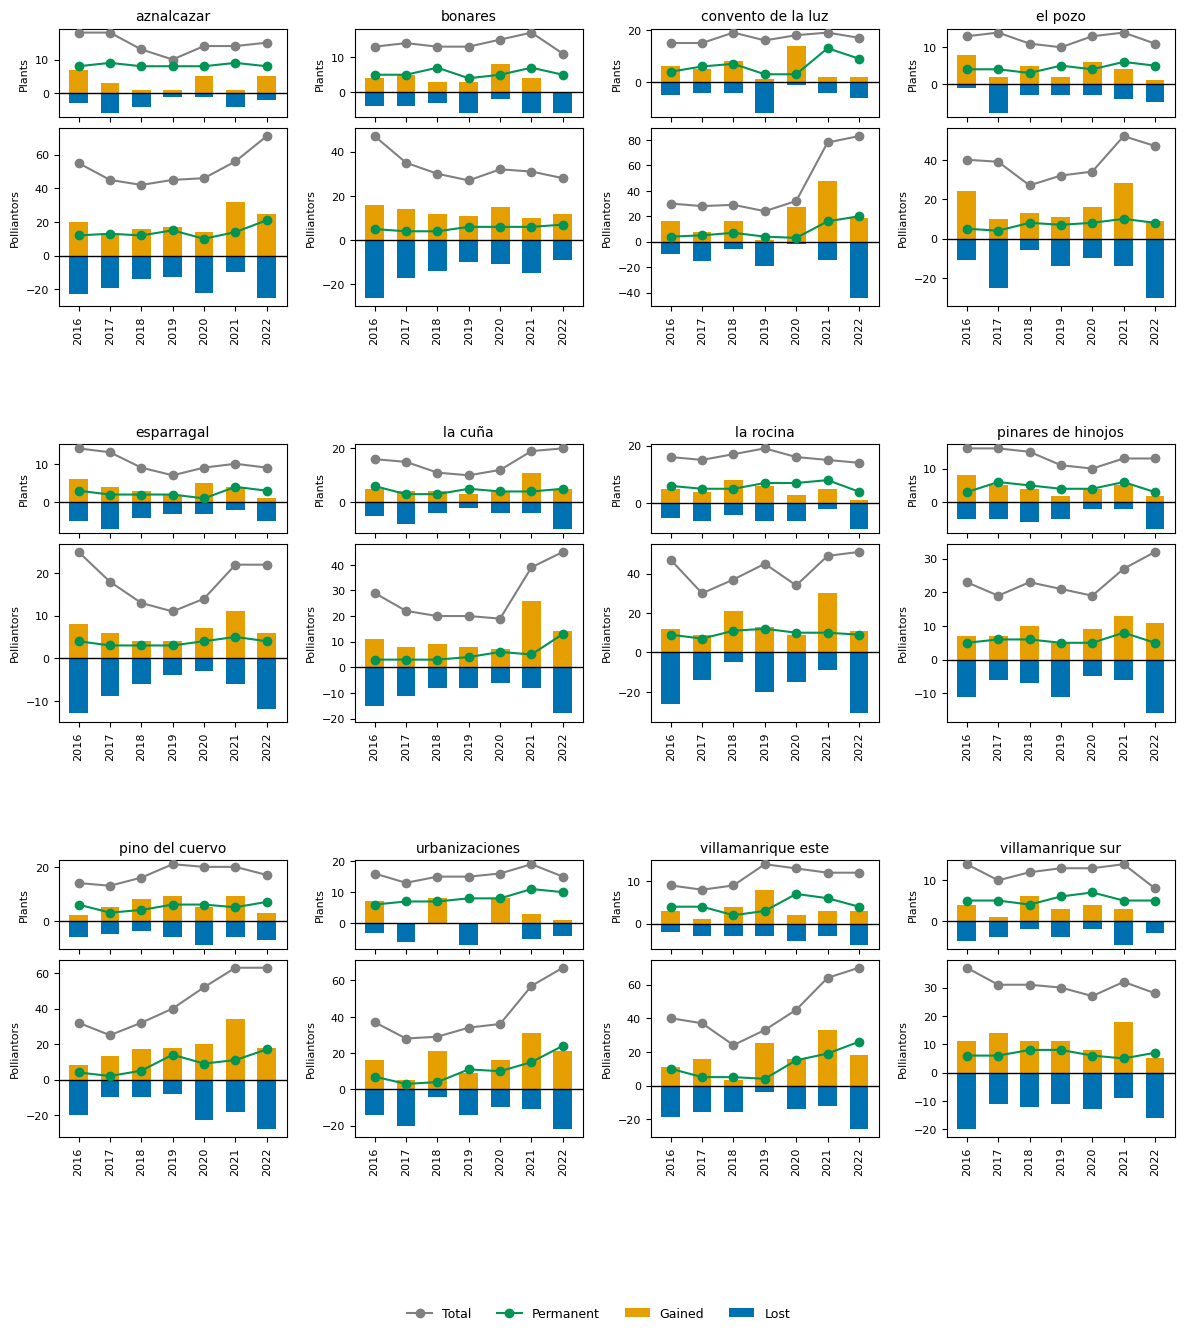

In [ ]:
fig, site_axes = plot_species_turnover_all_sites(Nodes_df)
plt.savefig("species_turnover_grid.png", dpi=150, bbox_inches='tight')

In [ ]:
def plot_species_turnover_all_sites(
        Nodes_df, ncol=4, nrow=3, figsize=None,
        height_ratios_per_site=(1, 2), site_level='Site_ID',
        year_col='year', metric_col='metric', value_col='n_nodes',
        plant_kwargs=None, pollinator_kwargs=None,
        fontsize=8, rotate_labels=90,
        inner_hspace=0.08, outer_hspace=0.5, wspace=0.3):
    """
    Version 'todos los sitios': para CADA Site_ID, dibuja los DOS paneles
    de plot_species_turnover (plantas arriba, polinizadores abajo).
 
    GridSpec ANIDADO: uno EXTERIOR controla el espacio ENTRE sitios
    (outer_hspace, mayor), y dentro de cada sitio, uno INTERIOR (2x1)
    controla el espacio entre plantas/polinizadores de ESE sitio
    (inner_hspace, menor) -- los dos espaciados se ajustan por separado.
 
    Parameters
    ----------
    height_ratios_per_site : (float, float)
        Alto relativo plantas/polinizadores DENTRO de cada sitio. Por
        defecto (1, 2).
    inner_hspace : float
        Espacio vertical entre plantas y polinizadores del MISMO sitio.
    outer_hspace : float
        Espacio vertical entre una fila de sitios y la siguiente.
    wspace : float
        Espacio horizontal entre columnas de sitios.
 
    Devuelve
    -------
    fig, site_axes : dict {site: (ax_plants, ax_poll)}
    """
    if plant_kwargs is None:
        plant_kwargs = {}
    if pollinator_kwargs is None:
        pollinator_kwargs = {}
 
    df_flat = Nodes_df.reset_index() if Nodes_df.index.nlevels > 1 or Nodes_df.index.name is not None else Nodes_df.copy()
    sites = sorted(df_flat[site_level].unique())
 
    if figsize is None:
        figsize = (3.6 * ncol, (sum(height_ratios_per_site)) * 1.6 * nrow)
 
    fig = plt.figure(figsize=figsize)
    outer_gs = gridspec.GridSpec(nrow, ncol, figure=fig,
                                  hspace=outer_hspace, wspace=wspace)
 
    site_axes = {}
    ref_x_by_col = {}
 
    for i, site in enumerate(sites):
        row_group = i // ncol
        col = i % ncol
 
        inner_gs = gridspec.GridSpecFromSubplotSpec(
            2, 1, subplot_spec=outer_gs[row_group, col],
            height_ratios=height_ratios_per_site, hspace=inner_hspace)
 
        sharex_ax = ref_x_by_col.get(col)
 
        ax_plants = fig.add_subplot(inner_gs[0], sharex=sharex_ax)
        ax_poll = fig.add_subplot(inner_gs[1], sharex=ax_plants)
 
        if col not in ref_x_by_col:
            ref_x_by_col[col] = ax_poll
 
        df_site = df_flat[df_flat[site_level] == site]
 
        plot_species_turnover(df_site, ax=ax_plants,
                               in_metric='P2', out_metric='P1', permanent_metric='PP',
                               year_col=year_col, metric_col=metric_col, value_col=value_col,
                               fontsize=fontsize, show_legend=False, **plant_kwargs)
        plot_species_turnover(df_site, ax=ax_poll,
                               in_metric='A2', out_metric='A1', permanent_metric='PA',
                               year_col=year_col, metric_col=metric_col, value_col=value_col,
                               fontsize=fontsize, show_legend=False, **pollinator_kwargs)
 
        ax_plants.set_title(str(site), fontsize=fontsize + 2)
        ax_plants.tick_params(axis='x', labelbottom=False)
 
        site_axes[site] = (ax_plants, ax_poll)
 
        years = sorted(df_site[year_col].unique())
        ax_poll.set_xticks(np.arange(len(years)))
        ax_poll.set_xticklabels(years, rotation=rotate_labels, fontsize=fontsize)

        ax_poll.set_ylabel("Polliantors")
        ax_plants.set_ylabel("Plants")
 
    first_ax = site_axes[sites[0]][1]
    handles, labels = first_ax.get_legend_handles_labels()
    if not handles:
        first_ax = site_axes[sites[0]][0]
        handles, labels = first_ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0),
               ncol=4, frameon=False, fontsize=fontsize + 1)
 
    return fig, site_axes
 


In [ ]:
#print(Changes_df.loc[site])
kw_result, posthoc_df = test_interaction_frequency_differences(Changes_df.loc[site])

Kruskal-Wallis: H=21.314, p=0.0064 (SIGNIFICATIVO a alpha=0.05)

Post-hoc de Dunn (p-valores, correccion Holm/Bonferroni):
        CN_CI   CN_DI   CN_II   CN_LI   CN_GI  L1N_LI  LBN_LI  G1N_GI  GBN_GI
CN_CI     1.0  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
CN_DI     1.0  1.0000  1.0000  0.8538  0.5121  0.4296  0.1539  0.6093  0.4410
CN_II     1.0  1.0000  1.0000  0.5831  0.3559  0.2818  0.0909  0.4341  0.3258
CN_LI     1.0  0.8538  0.5831  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
CN_GI     1.0  0.5121  0.3559  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
L1N_LI    1.0  0.4296  0.2818  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
LBN_LI    1.0  0.1539  0.0909  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
G1N_GI    1.0  0.6093  0.4341  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000
GBN_GI    1.0  0.4410  0.3258  1.0000  1.0000  1.0000  1.0000  1.0000  1.0000


In [ ]:
friedman_result, posthoc_df = test_interaction_frequency_differences_friedman(Changes_df.loc[site])

NameError: name 'test_interaction_frequency_differences_friedman' is not defined

In [ ]:
anova_result, tukey_result, assumptions = test_interaction_frequency_differences_anova(Changes_df.loc[site])

=== Chequeo de supuestos ===
  Shapiro-Wilk CN_CI: p=0.011 -> NO normal
  Shapiro-Wilk CN_DI: p=0.211 -> OK (normal)
  Shapiro-Wilk CN_II: p=0.146 -> OK (normal)
  Shapiro-Wilk CN_LI: p=0.216 -> OK (normal)
  Shapiro-Wilk CN_GI: p=0.014 -> NO normal
  Shapiro-Wilk L1N_LI: p=0.020 -> NO normal
  Shapiro-Wilk LBN_LI: p=0.045 -> NO normal
  Shapiro-Wilk G1N_GI: p=0.000 -> NO normal
  Shapiro-Wilk GBN_GI: p=0.141 -> OK (normal)
  Levene (homogeneidad de varianzas): p=0.544 -> OK (varianzas homogeneas)

  AVISO: 5 categorias no pasan normalidad y/o las varianzas no son homogeneas -- el ANOVA puede no ser fiable aqui. Considera quedarte con Kruskal-Wallis/Dunn, o usar Welch ANOVA (no asume varianzas iguales).

=== ANOVA ===
ANOVA: F=4.258, p=0.0005 (SIGNIFICATIVO a alpha=0.05)

Post-hoc de Tukey HSD:
Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
 CN_CI  CN_DI   0.7741 0.7226 -0.66

In [ ]:
from scipy.stats import kruskal
import scikit_posthocs as sp

def test_interaction_frequency_differences(
        df_site, freq_col='freq_interactions', n_col='n_interactions',
        metrics=('CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        metric_col='metric', alpha=0.05):
    """
    Test estadistico para saber si la frecuencia media por interaccion
    (freq_col/n_col) difiere entre las 9 categorias.
 
    1. Kruskal-Wallis (no parametrico, equivalente a ANOVA de un factor):
       compara las 9 categorias A LA VEZ -- responde "¿hay AL MENOS una
       categoria que difiere de las demas?", sin decir cual.
       Se usa Kruskal-Wallis en vez de ANOVA porque con pocos años por sitio
       (tipicamente ~4 puntos por categoria) no se puede asumir normalidad
       de forma fiable -- Kruskal-Wallis no la requiere.
 
    2. Test de Dunn (post-hoc, con correccion de Bonferroni): SOLO si el
       Kruskal-Wallis sale significativo, compara TODOS los pares de
       categorias entre si, para saber CUALES son las que difieren.
 
    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID (o varios, si quieres agregar mas puntos),
        con metric_col/freq_col/n_col.
    metrics : tuple de str
        Categorias a comparar.
    alpha : float
        Umbral de significacion (0.05 por defecto).
 
    Devuelve
    -------
    kw_result : dict
        {'H': estadistico, 'p_value': float, 'significant': bool}
    posthoc_df : pd.DataFrame o None
        Matriz de p-valores (Dunn, Bonferroni) para cada par de categorias --
        None si el Kruskal-Wallis no fue significativo (no tiene sentido
        mirar los pares si no hay diferencia global).
    """
    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
 
    # una lista de valores (razon freq/n por año) por cada categoria
    groups = []
    labels = []
    for metric in metrics:
        sub = df_flat.loc[df_flat[metric_col] == metric]
        vals = (sub[freq_col] / sub[n_col]).replace([np.inf, -np.inf], np.nan).dropna()
        if len(vals) > 0:
            groups.append(vals.values)
            labels.append(metric)
 
    # ------------------------------------------------------------------
    # 1) Kruskal-Wallis -- diferencia global entre las categorias
    # ------------------------------------------------------------------
    H, p_value = kruskal(*groups)
    significant = p_value < alpha
 
    kw_result = {'H': H, 'p_value': p_value, 'significant': significant}
 
    print(f"Kruskal-Wallis: H={H:.3f}, p={p_value:.4f} "
          f"({'SIGNIFICATIVO' if significant else 'no significativo'} a alpha={alpha})")
 
    # ------------------------------------------------------------------
    # 2) Post-hoc de Dunn -- SOLO si el paso 1 fue significativo
    # ------------------------------------------------------------------
    posthoc_df = None
    if significant:
        # formato "largo" que pide scikit-posthocs: una fila por valor,
        # con su categoria correspondiente
        long_data = []
        for label, vals in zip(labels, groups):
            for v in vals:
                long_data.append({'metric': label, 'value': v})
        long_df = pd.DataFrame(long_data)
 
        posthoc_df = sp.posthoc_dunn(long_df, val_col='value', group_col='metric',
                                      p_adjust='holm')#'bonferroni')
        posthoc_df = posthoc_df.loc[labels, labels]  # reordena segun 'metrics'
 
        print("\nPost-hoc de Dunn (p-valores, correccion Holm/Bonferroni):")
        print(posthoc_df.round(4))
    else:
        print("Como el Kruskal-Wallis no fue significativo, no se hace el post-hoc "
              "(no habria diferencias que localizar).")
 
    return kw_result, posthoc_df
 


In [ ]:
from scipy.stats import friedmanchisquare
import scikit_posthocs as sp

 
def test_interaction_frequency_differences_friedman(
        df_site, freq_col='freq_interactions', n_col='n_interactions',
        metrics=('CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        metric_col='metric', year_col='year', alpha=0.05):
    """
    Test de FRIEDMAN (no parametrico, para medidas repetidas/datos por
    bloques) -- alternativa a Kruskal-Wallis mas apropiada cuando se mira
    UN SOLO SITIO.
 
    Por que Friedman en vez de Kruskal-Wallis:
    Kruskal-Wallis asume que las 9 categorias son muestras INDEPENDIENTES.
    Pero aqui, dentro de un mismo sitio, CADA AÑO aporta un valor a las 9
    categorias A LA VEZ -- no son independientes, son medidas repetidas
    sobre el MISMO conjunto de años (el año actua como "bloque"). Friedman
    compara las categorias DENTRO de cada año (les asigna rangos año a año,
    no globalmente), eliminando la variabilidad de fondo comun a todas las
    categorias en un año dado (p.ej. un año especialmente activo o parco
    para TODA la red) -- esto da mas potencia con pocos años, que es
    justo el caso de un solo sitio.
 
    Requiere que TODOS los años tengan valor en TODAS las categorias (datos
    "completos", sin huecos) -- si a un sitio le falta una categoria en
    algun año, esa fila se descarta.
 
    1. Friedman: ¿hay AL MENOS una categoria que difiere de las demas?
    2. Post-hoc de Nemenyi (el que se usa habitualmente junto con Friedman):
       SOLO si el paso 1 es significativo, compara todos los pares.
 
    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID, con year/metric/freq_col/n_col.
    metrics : tuple de str
        Categorias a comparar.
    alpha : float
        Umbral de significacion.
 
    Devuelve
    -------
    friedman_result : dict
        {'statistic': float, 'p_value': float, 'significant': bool, 'n_blocks': int}
    posthoc_df : pd.DataFrame o None
        Matriz de p-valores (Nemenyi) para cada par -- None si Friedman no
        fue significativo.
    """
    #print(df_site)
    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
 
    df_flat = df_flat.copy()
    df_flat['_ratio'] = (df_flat[freq_col] / df_flat[n_col]).replace([np.inf, -np.inf], np.nan).fillna(0)
    #print("----------------------")
    #print(df_flat)
    #print("----------------------")
    # tabla año x categoria -- cada fila un año (bloque), cada columna una
    # categoria. dropna() quita años con algun hueco (Friedman necesita
    # datos completos, sin missing, en todos los bloques)
    wide = df_flat.pivot_table(index=year_col, columns=metric_col, values='_ratio')
    wide = wide[list(metrics)].dropna()
    #print("ahora wide")
    #print(wide)
    #print("---------------------")
    n_blocks = len(wide)
    if n_blocks < 3:
        raise ValueError(f"Friedman necesita al menos 3 años completos; solo hay {n_blocks}.")
 
    # ------------------------------------------------------------------
    # 1) Friedman -- diferencia global, respetando la estructura por bloques
    # ------------------------------------------------------------------
    stat, p_value = friedmanchisquare(*[wide[m].values for m in metrics])
    significant = p_value < alpha
 
    friedman_result = {'statistic': stat, 'p_value': p_value,
                        'significant': significant, 'n_blocks': n_blocks}
 
    print(f"Friedman (n={n_blocks} años completos): stat={stat:.3f}, p={p_value:.4f} "
          f"({'SIGNIFICATIVO' if significant else 'no significativo'} a alpha={alpha})")
 
    # ------------------------------------------------------------------
    # 2) Post-hoc de Nemenyi -- SOLO si el paso 1 fue significativo
    # ------------------------------------------------------------------
    posthoc_df = None
    if significant:
        posthoc_df = sp.posthoc_nemenyi_friedman(wide[list(metrics)].values)
        posthoc_df.index = metrics
        posthoc_df.columns = metrics
 
        print("\nPost-hoc de Nemenyi (p-valores):")
        print(posthoc_df.round(4))
    else:
        print("Como el Friedman no fue significativo, no se hace el post-hoc.")
 
    return friedman_result, posthoc_df
 


In [ ]:
from scipy.stats import f_oneway, shapiro, levene
from statsmodels.stats.multicomp import pairwise_tukeyhsd

def test_interaction_frequency_differences_anova(
        df_site, freq_col='freq_interactions', n_col='n_interactions',
        metrics=('CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        metric_col='metric', alpha=0.05):
    """
    ANOVA de una via (parametrico) + post-hoc de Tukey HSD, alternativa a
    Kruskal-Wallis/Dunn. Suele tener MAS POTENCIA que la version no
    parametrica (puede detectar diferencias por pares que Dunn no detecta),
    pero a cambio ASUME:
      1. Normalidad de los datos DENTRO de cada categoria.
      2. Homogeneidad de varianzas ENTRE categorias (varianzas parecidas).
 
    Con pocos años (7-8) por categoria, estos supuestos son dificiles de
    verificar con seguridad -- por eso esta funcion los CHEQUEA explicitamente
    (Shapiro-Wilk por categoria, Levene entre categorias) y te avisa si se
    incumplen, para que sepas si puedes fiarte del resultado del ANOVA o si
    deberias quedarte con la version no parametrica (Kruskal-Wallis/Dunn).
 
    Parameters
    ----------
    df_site : pd.DataFrame
        Ya filtrado a UN Site_ID (o varios, si agregas mas puntos).
    metrics : tuple de str
        Categorias a comparar.
    alpha : float
        Umbral de significacion.
 
    Devuelve
    -------
    anova_result : dict
        {'F': float, 'p_value': float, 'significant': bool}
    tukey_result : statsmodels TukeyHSDResults o None
        Resultado del post-hoc de Tukey -- None si el ANOVA no fue
        significativo. Tiene un metodo .summary() para verlo en tabla, y
        .plot_simultaneous() para verlo graficamente.
    assumptions : dict
        Resultados de los chequeos de normalidad (Shapiro por categoria) y
        homogeneidad de varianzas (Levene) -- para que decidas si el ANOVA
        es de fiar aqui.
    """
    df_flat = df_site.reset_index() if df_site.index.nlevels > 1 or df_site.index.name is not None else df_site.copy()
 
    groups = []
    labels = []
    for metric in metrics:
        sub = df_flat.loc[df_flat[metric_col] == metric]
        vals = (sub[freq_col] / sub[n_col]).replace([np.inf, -np.inf], np.nan).fillna(0).dropna()
        if len(vals) > 0:
            groups.append(vals.values)
            labels.append(metric)
 
    # ------------------------------------------------------------------
    # chequeo de supuestos -- ANTES de fiarnos del ANOVA
    # ------------------------------------------------------------------
    print("=== Chequeo de supuestos ===")
    shapiro_results = {}
    for label, vals in zip(labels, groups):
        if len(vals) >= 3:
            stat, p = shapiro(vals)
            shapiro_results[label] = p
            flag = "OK (normal)" if p >= alpha else "NO normal"
            print(f"  Shapiro-Wilk {label}: p={p:.3f} -> {flag}")
        else:
            shapiro_results[label] = None
            print(f"  Shapiro-Wilk {label}: <3 puntos, no se puede testar")
 
    n_non_normal = sum(1 for p in shapiro_results.values() if p is not None and p < alpha)
 
    levene_stat, levene_p = levene(*groups)
    levene_ok = levene_p >= alpha
    print(f"  Levene (homogeneidad de varianzas): p={levene_p:.3f} -> "
          f"{'OK (varianzas homogeneas)' if levene_ok else 'NO homogeneas'}")
 
    if n_non_normal > 0 or not levene_ok:
        print(f"\n  AVISO: {n_non_normal} categorias no pasan normalidad y/o las varianzas "
              f"no son homogeneas -- el ANOVA puede no ser fiable aqui. Considera quedarte "
              f"con Kruskal-Wallis/Dunn, o usar Welch ANOVA (no asume varianzas iguales).")
 
    assumptions = {'shapiro_p_values': shapiro_results, 'levene_p_value': levene_p,
                   'levene_homogeneous': levene_ok, 'n_non_normal_groups': n_non_normal}
 
    # ------------------------------------------------------------------
    # 1) ANOVA -- diferencia global
    # ------------------------------------------------------------------
    F, p_value = f_oneway(*groups)
    significant = p_value < alpha
    anova_result = {'F': F, 'p_value': p_value, 'significant': significant}
 
    print(f"\n=== ANOVA ===")
    print(f"ANOVA: F={F:.3f}, p={p_value:.4f} "
          f"({'SIGNIFICATIVO' if significant else 'no significativo'} a alpha={alpha})")
 
    # ------------------------------------------------------------------
    # 2) Post-hoc de Tukey HSD -- SOLO si el ANOVA fue significativo
    # ------------------------------------------------------------------
    tukey_result = None
    if significant:
        long_values = np.concatenate(groups)
        long_labels = np.concatenate([[label] * len(vals) for label, vals in zip(labels, groups)])
        tukey_result = pairwise_tukeyhsd(long_values, long_labels, alpha=alpha)
 
        print("\nPost-hoc de Tukey HSD:")
        print(tukey_result.summary())
    else:
        print("Como el ANOVA no fue significativo, no se hace el post-hoc.")
 
    return anova_result, tukey_result, assumptions
 


In [ ]:
Changes_df.loc[site]

n_interactions freq_interactions
year metric                                 
2016 CN_CI               9              12.0
     CN_DI               3               5.0
     CN_GI              10              11.0
     CN_II               5              13.0
     CN_LI              10              10.0
...                    ...               ...
2022 CN_LI              24              67.0
     G1N_GI             30              37.0
     GBN_GI              4               5.0
     L1N_LI             29              67.0
     LBN_LI              3              10.0

[63 rows x 2 columns]

In [16]:
site=Sites[0]
print(site)
result = summarize_reorganization(Changes_df.loc[site], Nodes_df.loc[site])

aznalcazar
n comparisons: 7
total interactions range: 78-129, mean±SD: 94.0 ± 18.5
lost or gained (changed): 75.6 ± 15.9
% persistent: 19.8 ± 2.1%
% one-transient (of changed): 63.1 ± 5.1%
% two-transient (of changed): 5.2 ± 2.8%
% rewiring (of changed): 31.6 ± 6.4%
% gained (of changed): 51.3 ± 10.7%
% lost (of changed): 48.7 ± 10.7%
% comparisons where gains > losses: 57%
% pollinators persistent: 27.0 ± 4.3%
% pollinators lost: 35.3 ± 10.0%
% pollinators gained: 37.7 ± 9.3%
% plants persistent: 58.7 ± 11.6%
% plants lost: 20.0 ± 10.7%
% plants gained: 21.3 ± 14.1%


In [6]:

def summarize_reorganization(changes_df, node_changes_df,
                              site_level='Site_ID', year_col='year', metric_col='metric',
                              value_col_changes='n_interactions', value_col_nodes='n_nodes',
                              sites=None):
    """
    Calcula, a partir de Changes_df y node_changes_df (todos los sitios o
    una lista concreta), las estadisticas necesarias para escribir un
    parrafo de resultados como el de referencia -- una por una, listas
    para insertar en el texto.
 
    Cada "comparacion" = una fila (Site_ID, year) -- una transicion entre
    dos redes sucesivas no vacias (lag=1).
 
    Parameters
    ----------
    changes_df : pd.DataFrame
        Tabla de cambios de interacciones (tu "Changes_df"), con las 9
        categorias en metric_col: CN_CI, CN_DI, CN_II (persistentes),
        CN_LI, CN_GI (rewiring entre permanentes), L1N_LI, G1N_GI (turnover
        de 1 especie transitoria), LBN_LI, GBN_GI (turnover de 2 especies
        transitorias).
    node_changes_df : pd.DataFrame
        Tabla de turnover de especies (tu "node_changes_df"), con PA/PP
        (permanentes) y A1/P1 (perdidas), A2/P2 (ganadas) en metric_col.
    sites : list de str o None
        Si None, usa TODOS los sitios presentes en changes_df. Si le pasas
        una lista, filtra solo a esos sitios.
 
    Devuelve
    -------
    dict con todas las estadisticas, listas para insertar en el texto.
    """
    df = changes_df.reset_index() if changes_df.index.nlevels > 1 or changes_df.index.name is not None else changes_df.copy()
    ndf = node_changes_df.reset_index() if node_changes_df.index.nlevels > 1 or node_changes_df.index.name is not None else node_changes_df.copy()
 
    # si ya viene filtrado a UN sitio (p.ej. Changes_df.loc[site]), la
    # columna site_level puede haber desaparecido al hacer el .loc -- se
    # añade de vuelta con un valor generico para que el resto de la
    # funcion (que agrupa por site_level+year_col) siga funcionando igual
    if site_level not in df.columns:
        df[site_level] = 'site'
    if site_level not in ndf.columns:
        ndf[site_level] = 'site'
 
    if sites is not None:
        df = df[df[site_level].isin(sites)]
        ndf = ndf[ndf[site_level].isin(sites)]
 
    comparisons = df[[site_level, year_col]].drop_duplicates()
    n_comparisons = len(comparisons)
 
    persistent_cats = ['CN_CI', 'CN_DI', 'CN_II']
    rewiring_cats = ['CN_LI', 'CN_GI']
    one_transient_cats = ['L1N_LI', 'G1N_GI']
    two_transient_cats = ['LBN_LI', 'GBN_GI']
    lost_cats = ['CN_LI', 'L1N_LI', 'LBN_LI']
    gained_cats = ['CN_GI', 'G1N_GI', 'GBN_GI']
    changed_cats = rewiring_cats + one_transient_cats + two_transient_cats
 
    def sum_cats(sub, cats):
        return sub.loc[sub[metric_col].isin(cats), value_col_changes].sum()
 
    rows = []
    for _, (site, yr) in comparisons.iterrows():
        sub = df[(df[site_level] == site) & (df[year_col] == yr)]
 
        total = sub[value_col_changes].sum()
        persistent = sum_cats(sub, persistent_cats)
        changed = sum_cats(sub, changed_cats)
        rewiring = sum_cats(sub, rewiring_cats)
        one_trans = sum_cats(sub, one_transient_cats)
        two_trans = sum_cats(sub, two_transient_cats)
        lost = sum_cats(sub, lost_cats)
        gained = sum_cats(sub, gained_cats)
 
        rows.append({
            'Site_ID': site, 'year': yr, 'total': total, 'persistent': persistent,
            'changed': changed, 'rewiring': rewiring, 'one_transient': one_trans,
            'two_transient': two_trans, 'lost': lost, 'gained': gained,
            'pct_persistent': 100 * persistent / total if total else np.nan,
            'pct_rewiring_of_changed': 100 * rewiring / changed if changed else np.nan,
            'pct_one_transient_of_changed': 100 * one_trans / changed if changed else np.nan,
            'pct_two_transient_of_changed': 100 * two_trans / changed if changed else np.nan,
            'pct_gained_of_changed': 100 * gained / changed if changed else np.nan,
            'pct_lost_of_changed': 100 * lost / changed if changed else np.nan,
            'gain_exceeds_loss': gained > lost,
        })
 
    comp_df = pd.DataFrame(rows)
 
    node_rows = []
    for _, (site, yr) in comparisons.iterrows():
        sub = ndf[(ndf[site_level] == site) & (ndf[year_col] == yr)]
 
        def val(m):
            v = sub.loc[sub[metric_col] == m, value_col_nodes]
            return v.sum() if len(v) else 0
 
        pa, a1, a2 = val('PA'), val('A1'), val('A2')
        pp, p1, p2 = val('PP'), val('P1'), val('P2')
        poll_total = pa + a1 + a2
        plant_total = pp + p1 + p2
 
        node_rows.append({
            'Site_ID': site, 'year': yr,
            'pct_poll_persistent': 100 * pa / poll_total if poll_total else np.nan,
            'pct_poll_lost': 100 * a1 / poll_total if poll_total else np.nan,
            'pct_poll_gained': 100 * a2 / poll_total if poll_total else np.nan,
            'pct_plant_persistent': 100 * pp / plant_total if plant_total else np.nan,
            'pct_plant_lost': 100 * p1 / plant_total if plant_total else np.nan,
            'pct_plant_gained': 100 * p2 / plant_total if plant_total else np.nan,
        })
    node_comp_df = pd.DataFrame(node_rows)
 
    def m_sd(series):
        return series.mean(), series.std()
 
    result = {
        'n_comparisons': n_comparisons,
        'total_range': (comp_df['total'].min(), comp_df['total'].max()),
        'total_mean_sd': m_sd(comp_df['total']),
        'changed_mean_sd': m_sd(comp_df['changed']),
        'pct_persistent_mean_sd': m_sd(comp_df['pct_persistent']),
        'pct_one_transient_mean_sd': m_sd(comp_df['pct_one_transient_of_changed']),
        'pct_two_transient_mean_sd': m_sd(comp_df['pct_two_transient_of_changed']),
        'pct_rewiring_mean_sd': m_sd(comp_df['pct_rewiring_of_changed']),
        'pct_gained_mean_sd': m_sd(comp_df['pct_gained_of_changed']),
        'pct_lost_mean_sd': m_sd(comp_df['pct_lost_of_changed']),
        'pct_comparisons_gain_exceeds_loss': 100 * comp_df['gain_exceeds_loss'].mean(),
        'pct_poll_persistent_mean_sd': m_sd(node_comp_df['pct_poll_persistent']),
        'pct_poll_lost_mean_sd': m_sd(node_comp_df['pct_poll_lost']),
        'pct_poll_gained_mean_sd': m_sd(node_comp_df['pct_poll_gained']),
        'pct_plant_persistent_mean_sd': m_sd(node_comp_df['pct_plant_persistent']),
        'pct_plant_lost_mean_sd': m_sd(node_comp_df['pct_plant_lost']),
        'pct_plant_gained_mean_sd': m_sd(node_comp_df['pct_plant_gained']),
        'comp_df': comp_df,
        'node_comp_df': node_comp_df,
    }
 
    _print_summary(result)
    return result
 
 
def _print_summary(r):
    print(f"n comparisons: {r['n_comparisons']}")
    print(f"total interactions range: {r['total_range'][0]:.0f}-{r['total_range'][1]:.0f}, "
          f"mean±SD: {r['total_mean_sd'][0]:.1f} ± {r['total_mean_sd'][1]:.1f}")
    print(f"lost or gained (changed): {r['changed_mean_sd'][0]:.1f} ± {r['changed_mean_sd'][1]:.1f}")
    print(f"% persistent: {r['pct_persistent_mean_sd'][0]:.1f} ± {r['pct_persistent_mean_sd'][1]:.1f}%")
    print(f"% one-transient (of changed): {r['pct_one_transient_mean_sd'][0]:.1f} ± {r['pct_one_transient_mean_sd'][1]:.1f}%")
    print(f"% two-transient (of changed): {r['pct_two_transient_mean_sd'][0]:.1f} ± {r['pct_two_transient_mean_sd'][1]:.1f}%")
    print(f"% rewiring (of changed): {r['pct_rewiring_mean_sd'][0]:.1f} ± {r['pct_rewiring_mean_sd'][1]:.1f}%")
    print(f"% gained (of changed): {r['pct_gained_mean_sd'][0]:.1f} ± {r['pct_gained_mean_sd'][1]:.1f}%")
    print(f"% lost (of changed): {r['pct_lost_mean_sd'][0]:.1f} ± {r['pct_lost_mean_sd'][1]:.1f}%")
    print(f"% comparisons where gains > losses: {r['pct_comparisons_gain_exceeds_loss']:.0f}%")
    print(f"% pollinators persistent: {r['pct_poll_persistent_mean_sd'][0]:.1f} ± {r['pct_poll_persistent_mean_sd'][1]:.1f}%")
    print(f"% pollinators lost: {r['pct_poll_lost_mean_sd'][0]:.1f} ± {r['pct_poll_lost_mean_sd'][1]:.1f}%")
    print(f"% pollinators gained: {r['pct_poll_gained_mean_sd'][0]:.1f} ± {r['pct_poll_gained_mean_sd'][1]:.1f}%")
    print(f"% plants persistent: {r['pct_plant_persistent_mean_sd'][0]:.1f} ± {r['pct_plant_persistent_mean_sd'][1]:.1f}%")
    print(f"% plants lost: {r['pct_plant_lost_mean_sd'][0]:.1f} ± {r['pct_plant_lost_mean_sd'][1]:.1f}%")
    print(f"% plants gained: {r['pct_plant_gained_mean_sd'][0]:.1f} ± {r['pct_plant_gained_mean_sd'][1]:.1f}%")
 


In [5]:

def summarize_reorganization(changes_df, node_changes_df,
                              site_level='Site_ID', year_col='year', metric_col='metric',
                              value_col_changes='n_interactions', value_col_nodes='n_nodes',
                              sites=None):
    """
    Calcula, a partir de Changes_df y node_changes_df (todos los sitios o
    una lista concreta), las estadisticas necesarias para escribir un
    parrafo de resultados como el de referencia -- una por una, listas
    para insertar en el texto.
 
    Cada "comparacion" = una fila (Site_ID, year) -- una transicion entre
    dos redes sucesivas no vacias (lag=1).
 
    Parameters
    ----------
    changes_df : pd.DataFrame
        Tabla de cambios de interacciones (tu "Changes_df"), con las 9
        categorias en metric_col: CN_CI, CN_DI, CN_II (persistentes),
        CN_LI, CN_GI (rewiring entre permanentes), L1N_LI, G1N_GI (turnover
        de 1 especie transitoria), LBN_LI, GBN_GI (turnover de 2 especies
        transitorias).
    node_changes_df : pd.DataFrame
        Tabla de turnover de especies (tu "node_changes_df"), con PA/PP
        (permanentes) y A1/P1 (perdidas), A2/P2 (ganadas) en metric_col.
    sites : list de str o None
        Si None, usa TODOS los sitios presentes en changes_df. Si le pasas
        una lista, filtra solo a esos sitios.
 
    Devuelve
    -------
    dict con todas las estadisticas, listas para insertar en el texto.
    """
    df = changes_df.reset_index() if changes_df.index.nlevels > 1 or changes_df.index.name is not None else changes_df.copy()
    ndf = node_changes_df.reset_index() if node_changes_df.index.nlevels > 1 or node_changes_df.index.name is not None else node_changes_df.copy()
 
    if sites is not None:
        df = df[df[site_level].isin(sites)]
        ndf = ndf[ndf[site_level].isin(sites)]
 
    comparisons = df[[site_level, year_col]].drop_duplicates()
    n_comparisons = len(comparisons)
 
    persistent_cats = ['CN_CI', 'CN_DI', 'CN_II']
    rewiring_cats = ['CN_LI', 'CN_GI']
    one_transient_cats = ['L1N_LI', 'G1N_GI']
    two_transient_cats = ['LBN_LI', 'GBN_GI']
    lost_cats = ['CN_LI', 'L1N_LI', 'LBN_LI']
    gained_cats = ['CN_GI', 'G1N_GI', 'GBN_GI']
    changed_cats = rewiring_cats + one_transient_cats + two_transient_cats
 
    def sum_cats(sub, cats):
        return sub.loc[sub[metric_col].isin(cats), value_col_changes].sum()
 
    rows = []
    for _, (site, yr) in comparisons.iterrows():
        sub = df[(df[site_level] == site) & (df[year_col] == yr)]
 
        total = sub[value_col_changes].sum()
        persistent = sum_cats(sub, persistent_cats)
        changed = sum_cats(sub, changed_cats)
        rewiring = sum_cats(sub, rewiring_cats)
        one_trans = sum_cats(sub, one_transient_cats)
        two_trans = sum_cats(sub, two_transient_cats)
        lost = sum_cats(sub, lost_cats)
        gained = sum_cats(sub, gained_cats)
 
        rows.append({
            'Site_ID': site, 'year': yr, 'total': total, 'persistent': persistent,
            'changed': changed, 'rewiring': rewiring, 'one_transient': one_trans,
            'two_transient': two_trans, 'lost': lost, 'gained': gained,
            'pct_persistent': 100 * persistent / total if total else np.nan,
            'pct_rewiring_of_changed': 100 * rewiring / changed if changed else np.nan,
            'pct_one_transient_of_changed': 100 * one_trans / changed if changed else np.nan,
            'pct_two_transient_of_changed': 100 * two_trans / changed if changed else np.nan,
            'pct_gained_of_changed': 100 * gained / changed if changed else np.nan,
            'pct_lost_of_changed': 100 * lost / changed if changed else np.nan,
            'gain_exceeds_loss': gained > lost,
        })
 
    comp_df = pd.DataFrame(rows)
 
    node_rows = []
    for _, (site, yr) in comparisons.iterrows():
        sub = ndf[(ndf[site_level] == site) & (ndf[year_col] == yr)]
 
        def val(m):
            v = sub.loc[sub[metric_col] == m, value_col_nodes]
            return v.sum() if len(v) else 0
 
        pa, a1, a2 = val('PA'), val('A1'), val('A2')
        pp, p1, p2 = val('PP'), val('P1'), val('P2')
        poll_total = pa + a1 + a2
        plant_total = pp + p1 + p2
 
        node_rows.append({
            'Site_ID': site, 'year': yr,
            'pct_poll_persistent': 100 * pa / poll_total if poll_total else np.nan,
            'pct_poll_lost': 100 * a1 / poll_total if poll_total else np.nan,
            'pct_poll_gained': 100 * a2 / poll_total if poll_total else np.nan,
            'pct_plant_persistent': 100 * pp / plant_total if plant_total else np.nan,
            'pct_plant_lost': 100 * p1 / plant_total if plant_total else np.nan,
            'pct_plant_gained': 100 * p2 / plant_total if plant_total else np.nan,
        })
    node_comp_df = pd.DataFrame(node_rows)
 
    def m_sd(series):
        return series.mean(), series.std()
 
    result = {
        'n_comparisons': n_comparisons,
        'total_range': (comp_df['total'].min(), comp_df['total'].max()),
        'total_mean_sd': m_sd(comp_df['total']),
        'changed_mean_sd': m_sd(comp_df['changed']),
        'pct_persistent_mean_sd': m_sd(comp_df['pct_persistent']),
        'pct_one_transient_mean_sd': m_sd(comp_df['pct_one_transient_of_changed']),
        'pct_two_transient_mean_sd': m_sd(comp_df['pct_two_transient_of_changed']),
        'pct_rewiring_mean_sd': m_sd(comp_df['pct_rewiring_of_changed']),
        'pct_gained_mean_sd': m_sd(comp_df['pct_gained_of_changed']),
        'pct_lost_mean_sd': m_sd(comp_df['pct_lost_of_changed']),
        'pct_comparisons_gain_exceeds_loss': 100 * comp_df['gain_exceeds_loss'].mean(),
        'pct_poll_persistent_mean_sd': m_sd(node_comp_df['pct_poll_persistent']),
        'pct_poll_lost_mean_sd': m_sd(node_comp_df['pct_poll_lost']),
        'pct_poll_gained_mean_sd': m_sd(node_comp_df['pct_poll_gained']),
        'pct_plant_persistent_mean_sd': m_sd(node_comp_df['pct_plant_persistent']),
        'pct_plant_lost_mean_sd': m_sd(node_comp_df['pct_plant_lost']),
        'pct_plant_gained_mean_sd': m_sd(node_comp_df['pct_plant_gained']),
        'comp_df': comp_df,
        'node_comp_df': node_comp_df,
    }
 
    _print_summary(result)
    return result
 
 
def _print_summary(r):
    print(f"n comparisons: {r['n_comparisons']}")
    print(f"total interactions range: {r['total_range'][0]:.0f}-{r['total_range'][1]:.0f}, "
          f"mean±SD: {r['total_mean_sd'][0]:.1f} ± {r['total_mean_sd'][1]:.1f}")
    print(f"lost or gained (changed): {r['changed_mean_sd'][0]:.1f} ± {r['changed_mean_sd'][1]:.1f}")
    print(f"% persistent: {r['pct_persistent_mean_sd'][0]:.1f} ± {r['pct_persistent_mean_sd'][1]:.1f}%")
    print(f"% one-transient (of changed): {r['pct_one_transient_mean_sd'][0]:.1f} ± {r['pct_one_transient_mean_sd'][1]:.1f}%")
    print(f"% two-transient (of changed): {r['pct_two_transient_mean_sd'][0]:.1f} ± {r['pct_two_transient_mean_sd'][1]:.1f}%")
    print(f"% rewiring (of changed): {r['pct_rewiring_mean_sd'][0]:.1f} ± {r['pct_rewiring_mean_sd'][1]:.1f}%")
    print(f"% gained (of changed): {r['pct_gained_mean_sd'][0]:.1f} ± {r['pct_gained_mean_sd'][1]:.1f}%")
    print(f"% lost (of changed): {r['pct_lost_mean_sd'][0]:.1f} ± {r['pct_lost_mean_sd'][1]:.1f}%")
    print(f"% comparisons where gains > losses: {r['pct_comparisons_gain_exceeds_loss']:.0f}%")
    print(f"% pollinators persistent: {r['pct_poll_persistent_mean_sd'][0]:.1f} ± {r['pct_poll_persistent_mean_sd'][1]:.1f}%")
    print(f"% pollinators lost: {r['pct_poll_lost_mean_sd'][0]:.1f} ± {r['pct_poll_lost_mean_sd'][1]:.1f}%")
    print(f"% pollinators gained: {r['pct_poll_gained_mean_sd'][0]:.1f} ± {r['pct_poll_gained_mean_sd'][1]:.1f}%")
    print(f"% plants persistent: {r['pct_plant_persistent_mean_sd'][0]:.1f} ± {r['pct_plant_persistent_mean_sd'][1]:.1f}%")
    print(f"% plants lost: {r['pct_plant_lost_mean_sd'][0]:.1f} ± {r['pct_plant_lost_mean_sd'][1]:.1f}%")
    print(f"% plants gained: {r['pct_plant_gained_mean_sd'][0]:.1f} ± {r['pct_plant_gained_mean_sd'][1]:.1f}%")
 


## Unweighted

In [ ]:
value_col="n_interactions"    
wide = Changes_df[value_col].unstack('metric')

rewiring = wide['CN_LI'] + wide['CN_GI']
trans_perm = wide['L1N_LI'] + wide['G1N_GI']
trans_trans = wide['LBN_LI'] + wide['GBN_GI']
total = rewiring + trans_perm + trans_trans

props_UW = pd.DataFrame({
    'persistent-persistent': rewiring / total,
    'transient-persistent': trans_perm / total,
    'transient-transient': trans_trans / total,
    'total_changes': total,
})
props_UW
wide_UW=wide

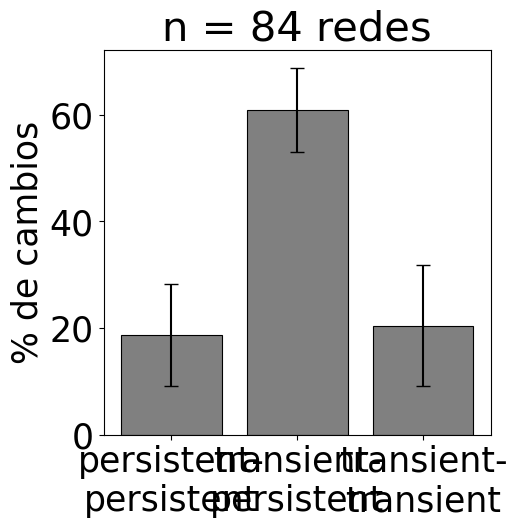

In [ ]:
props=props_UW
categories=('persistent-persistent','transient-persistent','transient-transient')
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['persistent-\npersistent','transient-\npersistent','transient-\ntransient']

means = props[list(categories)].mean()
stds = props[list(categories)].std()
n = props[list(categories)].notna().all(axis=1).sum()

x = np.arange(len(categories))
ax.bar(x, means.values * 100, yerr=stds.values * 100, capsize=5,
        color="gray", edgecolor='black', linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('% de cambios')
ax.set_title(f'n = {n} redes')
plt.show()

## Weighted

Pa el weighted los que vamos a sacar por en una es peso total del cambio de las persistent-persistent, transient-persistent y trnasient-transient. Para que sea equitativo entre redes vamos a normalizar con la suma total de cambios. 

In [ ]:
value_col="freq_interactions"    
wide = Changes_df[value_col].unstack('metric')

rewiring = wide['CN_LI'] + wide['CN_GI']
trans_perm = wide['L1N_LI'] + wide['G1N_GI']
trans_trans = wide['LBN_LI'] + wide['GBN_GI']
total = rewiring + trans_perm + trans_trans

props_WN = pd.DataFrame({
    'persistent-persistent': rewiring / total,
    'transient-persistent': trans_perm / total,
    'transient-transient': trans_trans / total,
    'total_changes': total,
})
props_WN

persistent-persistent transient-persistent  \
Site_ID           year                                              
aznalcazar        2016                  0.21                 0.69   
                  2017              0.305263             0.642105   
                  2018              0.348837             0.639535   
                  2019              0.470588             0.517647   
                  2020              0.296296              0.62963   
...                                      ...                  ...   
villamanrique sur 2018              0.230769             0.557692   
                  2019              0.265306             0.510204   
                  2020              0.277778             0.611111   
                  2021              0.265957              0.62766   
                  2022              0.056818             0.602273   

                       transient-transient total_changes  
Site_ID           year                                    
aznalcazar        2016                 0.1         100.0  
                  2017            0.052632          95.0  
                  2018            0.011628          86.0  
                  2019            0.011765          85.0  
                  2020            0.074074          81.0  
...                                    ...           ...  
villamanrique sur 2018            0.211538          52.0  
                  2019             0.22449          49.0  
                  2020            0.111111          54.0  
                  2021            0.106383          94.0  
                  2022            0.340909          88.0  

[84 rows x 4 columns]

In [ ]:
wide/wide_UW

metric                     CN_CI     CN_DI     CN_GI     CN_II     CN_LI  \
Site_ID           year                                                     
aznalcazar        2016  1.333333  1.666667       1.1       2.6       1.0   
                  2017       1.5     1.375  1.083333  1.333333  1.230769   
                  2018  1.444444       3.0  1.272727       3.0  1.454545   
                  2019  1.545455       3.0  1.666667       2.0  1.666667   
                  2020  1.666667       2.2     1.125       3.0     1.875   
...                          ...       ...       ...       ...       ...   
villamanrique sur 2018       1.0       1.0       1.0       1.0       1.5   
                  2019  1.333333       1.0  1.571429       1.0       1.0   
                  2020       1.0       NaN  1.333333       4.0  1.571429   
                  2021       2.0       NaN  3.428571       2.5       1.0   
                  2022       2.0       1.0       1.0       1.0       2.0   

metric                    G1N_GI GBN_GI    L1N_LI    LBN_LI  
Site_ID           year                                       
aznalcazar        2016  1.290323    2.0      1.16       1.0  
                  2017       1.4    1.0  1.481481  1.333333  
                  2018  1.285714    NaN  1.473684       1.0  
                  2019  1.190476    NaN  1.266667       1.0  
                  2020  1.357143    1.2  1.142857       NaN  
...                          ...    ...       ...       ...  
villamanrique sur 2018      1.25    2.0    1.1875       1.0  
                  2019  1.071429    1.0       1.0  2.666667  
                  2020       1.1    1.0  1.157895       1.0  
                  2021       2.4    2.0       1.1       1.0  
                  2022  1.166667    NaN  3.066667       3.0  

[84 rows x 9 columns]

In [ ]:
wide_UW

metric                 CN_CI CN_DI CN_GI CN_II CN_LI G1N_GI GBN_GI L1N_LI  \
Site_ID           year                                                      
aznalcazar        2016     9     3    10     5    10     31      3     25   
                  2017     4     8    12     6    13     15      1     27   
                  2018     9     2    11     4    11     21      0     19   
                  2019    11     2    12     6    12     21      0     15   
                  2020     6     5     8     5     8     14      5     28   
...                      ...   ...   ...   ...   ...    ...    ...    ...   
villamanrique sur 2018     3     2     3     1     6      8      5     16   
                  2019     3     3     7     1     2     14      3     10   
                  2020     2     0     3     1     7     10      4     19   
                  2021     1     0     7     2     1     20      2     10   
                  2022     3     2     3     1     1      6      0     15   

metric                 LBN_LI  
Site_ID           year         
aznalcazar        2016      4  
                  2017      3  
                  2018      1  
                  2019      1  
                  2020      0  
...                       ...  
villamanrique sur 2018      1  
                  2019      3  
                  2020      2  
                  2021      6  
                  2022     10  

[84 rows x 9 columns]

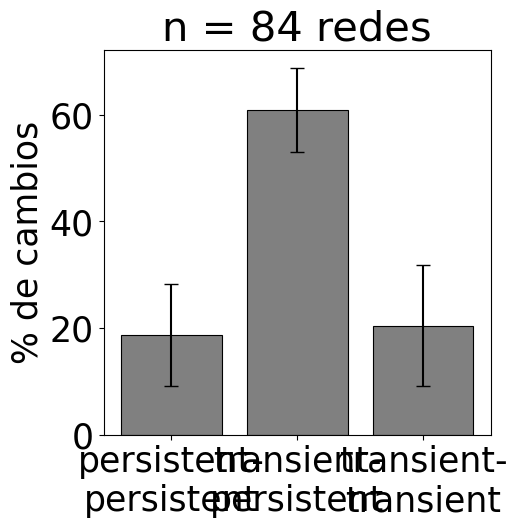

In [ ]:
props_WN
categories=('persistent-persistent','transient-persistent','transient-transient')
fig, ax = plt.subplots(figsize=(5, 5))
labels = ['persistent-\npersistent','transient-\npersistent','transient-\ntransient']

means = props[list(categories)].mean()
stds = props[list(categories)].std()
n = props[list(categories)].notna().all(axis=1).sum()

x = np.arange(len(categories))
ax.bar(x, means.values * 100, yerr=stds.values * 100, capsize=5,
        color="gray", edgecolor='black', linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('% de cambios')
ax.set_title(f'n = {n} redes')
plt.show()

Esta es muy parecida a la no pesada pq importa mucho que el numero en si mismo de interacciones se va sumando y al final determina cuanto cambia. 

Lo que nos interesa es saber si las interacciones entre transient o permanentes tienen per se más frecuencia, por ejemplo

In [ ]:
mean_str_df=Changes_df["freq_interactions"]/Changes_df["n_interactions"]

Mean=mean_str_df.groupby("metric").mean()
Std=mean_str_df.groupby("metric").std()

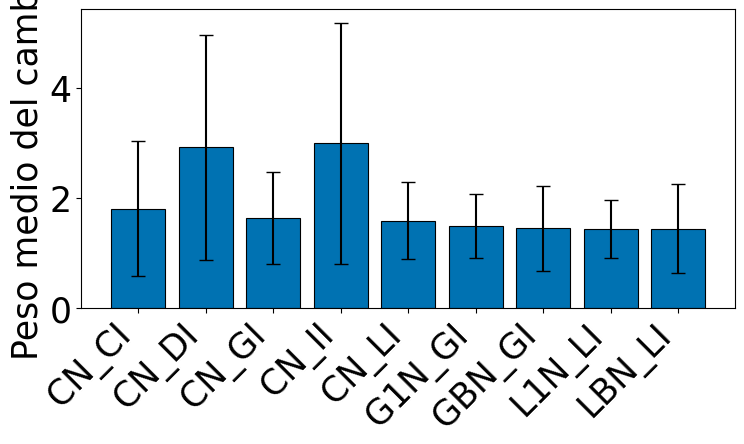

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(Mean))
ax.bar(x, Mean.values, yerr=Std.values, capsize=5,
       color="#0072B2", edgecolor="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(Mean.index, rotation=45, ha='right')
ax.set_ylabel("Peso medio del cambio")
plt.tight_layout()

<AxesSubplot: ylabel='freq_interactions'>

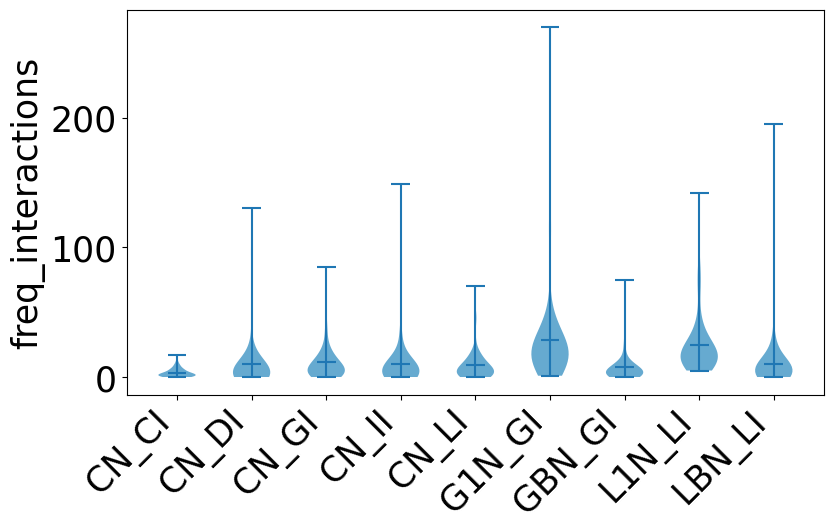

In [ ]:
def plot_changes_violin(Changes_df, value_col="freq_interactions",
                         metric_order=None, ax=None, color="#0072B2",
                         color_by_site=False, jitter=0.06, point_size=25,
                         site_palette=None, legend=True, zero_offset=None):
    """
    Violin plot de la distribucion de `value_col` para cada categoria de cambio,
    usando TODAS las redes (todas las filas Site_ID/year) de Changes_df.

    Parameters
    ----------
    color_by_site : bool
        Si True, superpone los puntos individuales (una red = un punto) encima
        del violin, coloreados por Site_ID, con un poco de jitter horizontal
        para que no se amontonen.
    jitter : float
        Dispersion horizontal maxima de los puntos (en unidades del eje x).
    site_palette : dict {site: color} o None
        Si None, se genera automaticamente con un colormap cualitativo.
    zero_offset : float o None
        Si no es None, sustituye los valores EXACTAMENTE 0 por este numero
        (p.ej. 0.1) antes de graficar. Necesario para usar escala logaritmica
        (ax.set_yscale('log')), ya que log(0) no existe. Los valores >0 no se
        tocan -- solo se desplazan los ceros para que sean visibles cerca del
        fondo del grafico en vez de desaparecer.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))

    if metric_order is None:
        metric_order = Changes_df.index.get_level_values('metric').unique().tolist()

    data_by_metric = [
        Changes_df.xs(m, level='metric')[value_col].dropna().astype(float)
        for m in metric_order
    ]

    if zero_offset is not None:
        data_by_metric = [d.replace(0, zero_offset) for d in data_by_metric]

    parts = ax.violinplot([d.values for d in data_by_metric], showmeans=True, showextrema=True)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_alpha(0.4 if color_by_site else 0.6)

    if color_by_site:
        sites = Changes_df.index.get_level_values('Site_ID').unique().tolist()
        if site_palette is None:
            cmap = plt.get_cmap('tab10' if len(sites) <= 10 else 'tab20')
            site_palette = {s: cmap(i % cmap.N) for i, s in enumerate(sites)}

        rng = np.random.default_rng(0)  # semilla fija -> jitter reproducible
        plotted_sites = set()
        for i, series in enumerate(data_by_metric, start=1):
            site_labels = series.index.get_level_values('Site_ID')
            x = i + rng.uniform(-jitter, jitter, size=len(series))
            for site in site_labels.unique():
                mask = site_labels == site
                label = site if (legend and site not in plotted_sites) else None
                ax.scatter(x[mask], series.values[mask], color=site_palette[site],
                           s=point_size, edgecolor='black', linewidth=0.4,
                           zorder=3, label=label)
                plotted_sites.add(site)

        if legend:
            ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, title='Site')

    ax.set_xticks(np.arange(1, len(metric_order) + 1))
    ax.set_xticklabels(metric_order, rotation=45, ha='right')
    ax.set_ylabel(value_col)

    return ax
plot_changes_violin(Changes_df)

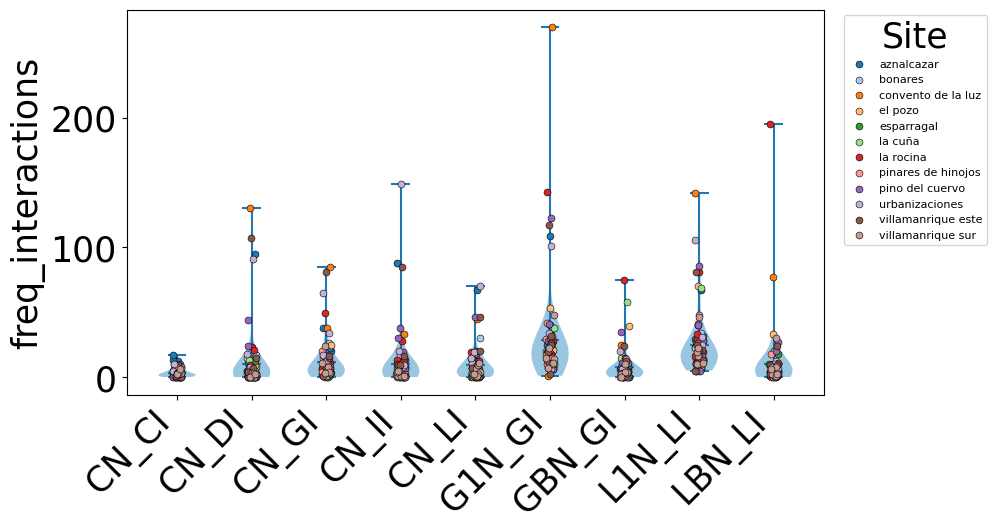

In [ ]:
plot_changes_violin(Changes_df, value_col="freq_interactions", color_by_site=True);

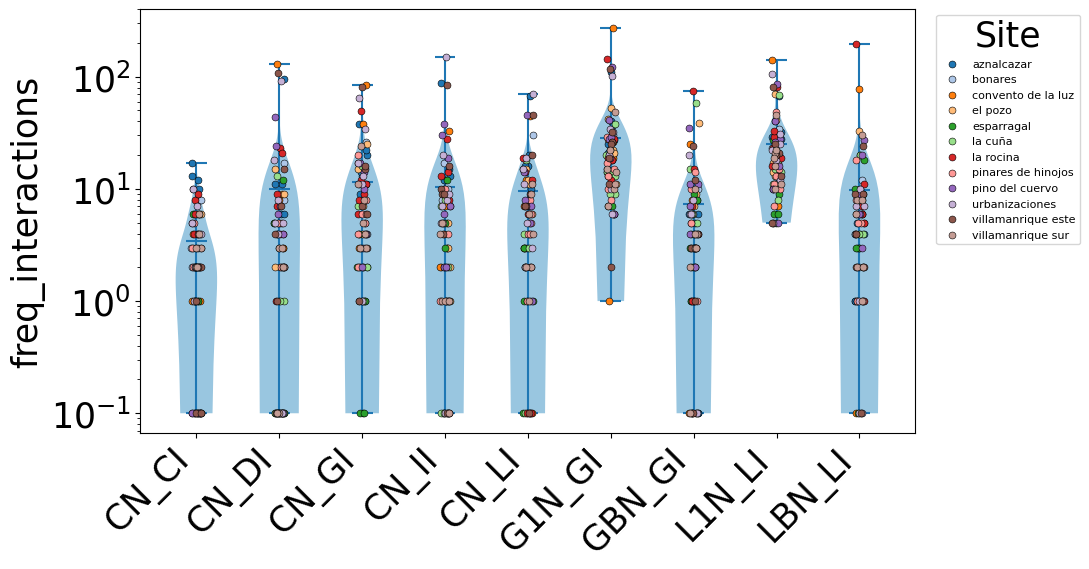

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_changes_violin(Changes_df, value_col="freq_interactions", ax=ax, color_by_site=True, zero_offset=0.1)
ax.set_yscale('log')

# Temporality



In [24]:
#Generamos los diccionaros con las 4 dataframes
#metric=['CN_CI', 'CN_DI', 'CN_II', 'CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI']
#metric_N=["PA","PP","A1","P1","A2","P2"]
#mi2=pd.MultiIndex.from_product([Sites,Years[1::],metric],names=["Site_ID", "year","metric"])
#mi2N=pd.MultiIndex.from_product([Sites,Years[1::],metric_N],names=["Site_ID", "year","metric"])
All_Changes={}
All_Nodes={}
for N in range(1,5):
    Changes_df=pd.DataFrame(index=mi2,columns=["n_interactions","freq_interactions"])
    Changes_df.sort_index(inplace=True)
    
    Nodes_df=pd.DataFrame(index=mi2N,columns=["n_nodes"])
    Nodes_df.sort_index(inplace=True)
    
    for site in Sites:
        for year in Years[0:-N]:
            changes, nodes = rewiring_freq_py(networks[site][year], networks[site][year+N])
            changes = changes.set_index('metric')          # <- AÑADIR esto
            nodes = nodes.set_index('metric')          # <- AÑADIR esto
            for m in changes.index:                        # <- 'm', NO 'metric'
                Changes_df.loc[(site, year+N, m), 'n_interactions'] = changes.loc[m, 'n_interactions']
                Changes_df.loc[(site, year+N, m), 'freq_interactions'] = changes.loc[m, 'freq_sum']
            for m in nodes.index:                        # <- 'm', NO 'metric'
                Nodes_df.loc[(site, year+N, m), 'n_nodes'] = nodes.loc[m, 'n_species']

    All_Changes[N]=Changes_df
    All_Nodes[N]=Nodes_df
  

In [25]:
All_Nodes



{1:                               n_nodes
 Site_ID           year metric        
 aznalcazar        2016 A1          23
                        A2          20
                        P1           3
                        P2           7
                        PA          12
 ...                               ...
 villamanrique sur 2022 A2           5
                        P1           3
                        P2           0
                        PA           7
                        PP           5
 
 [504 rows x 1 columns],
 2:                               n_nodes
 Site_ID           year metric        
 aznalcazar        2016 A1         NaN
                        A2         NaN
                        P1         NaN
                        P2         NaN
                        PA         NaN
 ...                               ...
 villamanrique sur 2022 A2           9
                        P1           8
                        P2           2
                        PA     

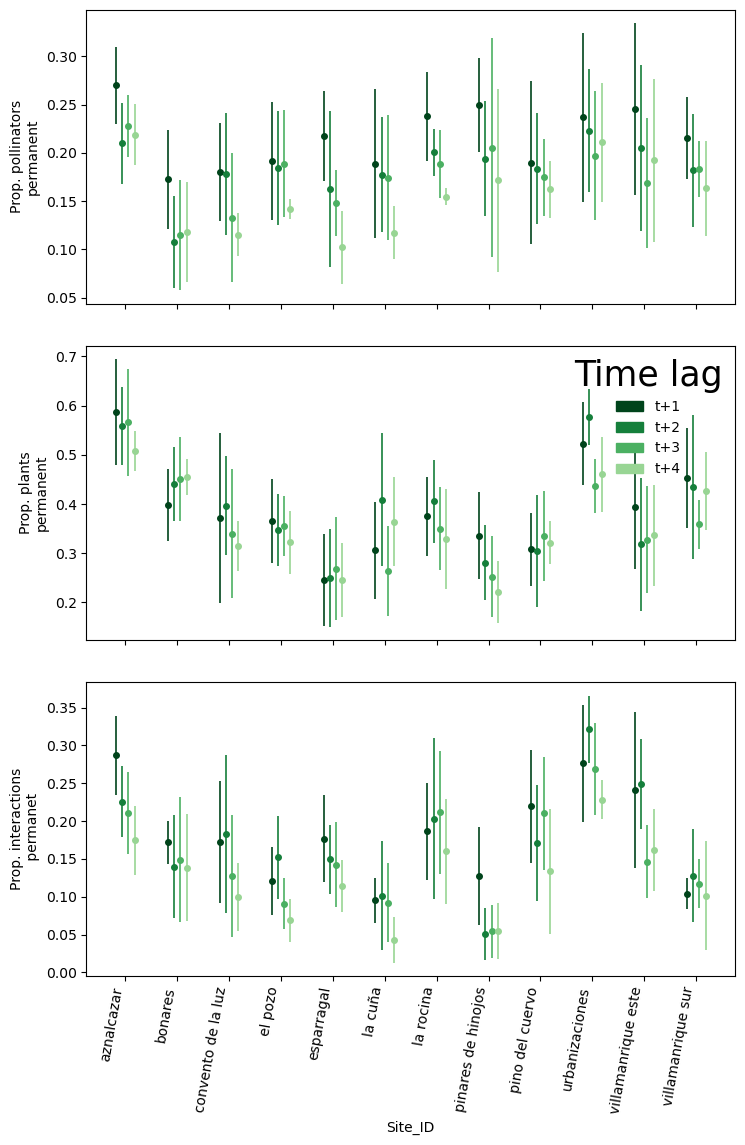

In [26]:
fig, axes, extra_data = plot_lag_summary_combined(All_Nodes, All_Changes)
plt.show()
#plt.savefig("lag_summary_combined.png", dpi=150, bbox_inches='tight')


In [ ]:
def _compute_site_year_metrics(
        nodes_df_lag, changes_df_lag, site_level, metric_col, year_col,
        value_col_nodes, value_col_changes,
        permanent_int_categories, change_categories,
        poll_permanent, poll_transient, plant_permanent, plant_transient):
    """
    Helper interno: calcula, por sitio y año, las variables (proporcion de
    polinizadores permanentes, de plantas permanentes, numero total de
    cambios de interaccion, y proporcion de interacciones permanentes) para
    UN lag. Devuelve 4 dicts {site: [valores por año]}.
 
    "Permanente" (interaccion) = la interaccion SIGUE EXISTIENDO en ambos
    tiempos, cambie o no de intensidad -- CN_CI + CN_DI + CN_II.
    "Cambio" = la interaccion aparece o desaparece del todo -- el resto de
    categorias (CN_LI, CN_GI, L1N_LI, LBN_LI, G1N_GI, GBN_GI).
    """
    nodes_flat = nodes_df_lag.reset_index() if nodes_df_lag.index.nlevels > 1 or nodes_df_lag.index.name is not None else nodes_df_lag.copy()
    changes_flat = changes_df_lag.reset_index() if changes_df_lag.index.nlevels > 1 or changes_df_lag.index.name is not None else changes_df_lag.copy()
 
    sites = sorted(nodes_flat[site_level].unique())
 
    def get_node_val(df_site_year, metric):
        v = df_site_year.loc[df_site_year[metric_col] == metric, value_col_nodes]
        return v.sum() if len(v) else 0
 
    poll_ratios = {s: [] for s in sites}
    plant_ratios = {s: [] for s in sites}
    n_changes = {s: [] for s in sites}
    prop_permanent_int = {s: [] for s in sites}
 
    for site in sites:
        sub_nodes = nodes_flat[nodes_flat[site_level] == site]
        sub_changes = changes_flat[changes_flat[site_level] == site]
        years = sorted(sub_nodes[year_col].unique())
 
        for yr in years:
            yr_nodes = sub_nodes[sub_nodes[year_col] == yr]
 
            pa = get_node_val(yr_nodes, poll_permanent)
            a_trans = sum(get_node_val(yr_nodes, m) for m in poll_transient)
            poll_total = pa + a_trans
            poll_ratios[site].append(pa / poll_total if poll_total > 0 else np.nan)
 
            pp = get_node_val(yr_nodes, plant_permanent)
            p_trans = sum(get_node_val(yr_nodes, m) for m in plant_transient)
            plant_total = pp + p_trans
            plant_ratios[site].append(pp / plant_total if plant_total > 0 else np.nan)
 
            yr_changes = sub_changes[sub_changes[year_col] == yr]
            n_permanent_int = yr_changes.loc[yr_changes[metric_col].isin(permanent_int_categories), value_col_changes].sum()
            n_change = yr_changes.loc[yr_changes[metric_col].isin(change_categories), value_col_changes].sum()
            n_all_int = n_permanent_int + n_change
 
            n_changes[site].append(n_change)
            prop_permanent_int[site].append(n_permanent_int / n_all_int if n_all_int > 0 else np.nan)
 
    return poll_ratios, plant_ratios, n_changes, prop_permanent_int

def plot_lag_summary_combined(
        All_Nodes, All_Changes, lags=(1, 2, 3, 4), figsize=(8, 12),
        site_level='Site_ID', metric_col='metric', year_col='year',
        value_col_nodes='n_nodes', value_col_changes='n_interactions',
        permanent_int_categories=('CN_CI', 'CN_DI', 'CN_II'),
        change_categories=('CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        poll_permanent='PA', poll_transient=('A1', 'A2'),
        plant_permanent='PP', plant_transient=('P1', 'P2'),
        offset=0.12, cmap=None, cmap_range=(1.0,0.4),
        fontsize=10, capsize=0, marker='.', markersize=8,
        rotate_labels=80, label_dict=None, legend_loc='upper right'):
    """
    Version 'todos los lags juntos' de plot_lag_summary_by_site: los 3
    paneles (proporcion polinizadores permanentes, proporcion plantas
    permanentes, numero total de cambios de interaccion) muestran los 4
    lags (t+1, t+2, t+3, t+4) A LA VEZ, cada uno ligeramente desplazado a
    la derecha dentro de la posicion de cada sitio, coloreados con un
    degradado (verde por defecto, mas oscuro = lag mayor).
 
    Definiciones de interaccion "permanente" vs "cambio" (panel 3):
      - PERMANENTE: la interaccion SIGUE EXISTIENDO en ambos tiempos, cambie
        o no de intensidad -- CN_CI + CN_DI + CN_II (por defecto).
      - CAMBIO: la interaccion aparece o desaparece del todo -- el resto de
        categorias (CN_LI, CN_GI, L1N_LI, LBN_LI, G1N_GI, GBN_GI, por defecto).
 
    Ademas de dibujar el NUMERO total de cambios (panel 3), se calcula
    tambien -- aunque no se dibuja por ahora -- la PROPORCION de
    interacciones permanentes: (CN_CI+CN_DI+CN_II) / (suma de las 9
    categorias). Se devuelve en el diccionario extra_data por si prefieres
    usarla en vez del numero absoluto.
 
    Parameters
    ----------
    All_Nodes, All_Changes : dict {lag: pd.DataFrame}
        Tus diccionarios, con una clave por lag (1, 2, 3, 4...) y como valor
        la tabla de ESE lag.
    lags : tuple de int
        Que claves de All_Nodes/All_Changes dibujar, y en que orden.
    permanent_int_categories, change_categories : tuple de str
        Que categorias de changes_df_lag cuentan como "permanente" / "cambio"
        (ver definiciones arriba).
    offset, cmap, cmap_range, label_dict, legend_loc :
        Igual que antes -- estetica del grafico.
 
    Devuelve
    -------
    fig, (ax1, ax2, ax3), extra_data
    extra_data : dict {lag: {'prop_permanent_int': {site: [valores por año]}}}
        La proporcion de interacciones permanentes por sitio y año, para
        cada lag -- calculada pero NO dibujada en esta figura.
    """
    if cmap is None:
        cmap = plt.cm.Greens
    if label_dict is None:
        label_dict = {'poll': 'Prop. pollinators\npermanent',
                       'plant': 'Prop. plants\npermanent',
                       'changes': 'Prop. interactions\n permanet'}
 
    colors = cmap(np.linspace(cmap_range[0], cmap_range[1], len(lags)))
 
    nodes_flat0 = All_Nodes[lags[0]]
    nodes_flat0 = nodes_flat0.reset_index() if nodes_flat0.index.nlevels > 1 or nodes_flat0.index.name is not None else nodes_flat0
    sites = sorted(nodes_flat0[site_level].unique())
    x = np.arange(len(sites))
 
    n = len(lags)
    offsets = [(i - (n - 1) / 2) * offset for i in range(n)]
 
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=figsize, sharex=True)
 
    extra_data = {}
    for i, lag in enumerate(lags):
        poll_ratios, plant_ratios, n_changes, prop_permanent_int = _compute_site_year_metrics(
            All_Nodes[lag], All_Changes[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
 
        extra_data[lag] = {'prop_permanent_int': prop_permanent_int}
 
        x_off = x + offsets[i]
        color = colors[i]
 
        for ax, data_dict in zip((ax1, ax2, ax3), (poll_ratios, plant_ratios, prop_permanent_int )):#n_changes
            means = [np.nanmean(data_dict[s]) for s in sites]
            stds = [np.nanstd(data_dict[s]) for s in sites]
            ax.errorbar(x_off, means, yerr=stds, fmt=marker, capsize=capsize,
                        color=color, markersize=markersize, elinewidth=1.2)
 
    ax1.set_ylabel(label_dict['poll'], fontsize=fontsize)
    ax2.set_ylabel(label_dict['plant'], fontsize=fontsize)
    ax3.set_ylabel(label_dict['changes'], fontsize=fontsize)
    for ax in (ax1, ax2, ax3):
        ax.tick_params(axis='y', labelsize=fontsize)
 
    ax3.set_xticks(x)
    ax3.set_xticklabels(sites, rotation=rotate_labels, ha='right', fontsize=fontsize)
    ax3.set_xlabel(site_level, fontsize=fontsize)
 
    handles = [mpatches.Patch(color=colors[i], label=f't+{lags[i]}') for i in range(n)]
    ax2.legend(handles=handles, title='Time lag', loc=legend_loc, frameon=False, fontsize=fontsize)
 
    plt.tight_layout()
 
    return fig, (ax1, ax2, ax3), extra_data
 
 

In [ ]:
def _compute_site_year_metrics(
        nodes_df_lag, changes_df_lag, site_level, metric_col, year_col,
        value_col_nodes, value_col_changes,
        permanent_int_categories, change_categories,
        poll_permanent, poll_transient, plant_permanent, plant_transient):
    """
    Helper interno: calcula, por sitio y año, las variables (proporcion de
    polinizadores permanentes, de plantas permanentes, numero total de
    cambios de interaccion, y proporcion de interacciones permanentes) para
    UN lag. Devuelve 4 dicts {site: [valores por año]}.
 
    "Permanente" (interaccion) = la interaccion SIGUE EXISTIENDO en ambos
    tiempos, cambie o no de intensidad -- CN_CI + CN_DI + CN_II.
    "Cambio" = la interaccion aparece o desaparece del todo -- el resto de
    categorias (CN_LI, CN_GI, L1N_LI, LBN_LI, G1N_GI, GBN_GI).
    """
    nodes_flat = nodes_df_lag.reset_index() if nodes_df_lag.index.nlevels > 1 or nodes_df_lag.index.name is not None else nodes_df_lag.copy()
    changes_flat = changes_df_lag.reset_index() if changes_df_lag.index.nlevels > 1 or changes_df_lag.index.name is not None else changes_df_lag.copy()
 
    sites = sorted(nodes_flat[site_level].unique())
 
    def get_node_val(df_site_year, metric):
        v = df_site_year.loc[df_site_year[metric_col] == metric, value_col_nodes]
        return v.sum() if len(v) else 0
 
    poll_ratios = {s: [] for s in sites}
    plant_ratios = {s: [] for s in sites}
    n_changes = {s: [] for s in sites}
    prop_permanent_int = {s: [] for s in sites}
 
    for site in sites:
        sub_nodes = nodes_flat[nodes_flat[site_level] == site]
        sub_changes = changes_flat[changes_flat[site_level] == site]
        years = sorted(sub_nodes[year_col].unique())
 
        for yr in years:
            yr_nodes = sub_nodes[sub_nodes[year_col] == yr]
 
            pa = get_node_val(yr_nodes, poll_permanent)
            a_trans = sum(get_node_val(yr_nodes, m) for m in poll_transient)
            poll_total = pa + a_trans
            poll_ratios[site].append(pa / poll_total if poll_total > 0 else np.nan)
 
            pp = get_node_val(yr_nodes, plant_permanent)
            p_trans = sum(get_node_val(yr_nodes, m) for m in plant_transient)
            plant_total = pp + p_trans
            plant_ratios[site].append(pp / plant_total if plant_total > 0 else np.nan)
 
            yr_changes = sub_changes[sub_changes[year_col] == yr]
            n_permanent_int = yr_changes.loc[yr_changes[metric_col].isin(permanent_int_categories), value_col_changes].sum()
            n_change = yr_changes.loc[yr_changes[metric_col].isin(change_categories), value_col_changes].sum()
            n_all_int = n_permanent_int + n_change
 
            n_changes[site].append(n_change)
            prop_permanent_int[site].append(n_permanent_int / n_all_int if n_all_int > 0 else np.nan)
 
    return poll_ratios, plant_ratios, n_changes, prop_permanent_int
 
 
def plot_lag_summary_combined(
        All_Nodes, All_Changes, lags=(1, 2, 3, 4), figsize=(8, 12),
        site_level='Site_ID', metric_col='metric', year_col='year',
        value_col_nodes='n_nodes', value_col_changes='n_interactions',
        permanent_int_categories=('CN_CI', 'CN_DI', 'CN_II'),
        change_categories=('CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        poll_permanent='PA', poll_transient=('A1', 'A2'),
        plant_permanent='PP', plant_transient=('P1', 'P2'),
        offset=0.12, cmap=None, cmap_range=(1.0, 0.4),
        fontsize=10, capsize=0, marker='.', markersize=8,
        rotate_labels=80, label_dict=None, legend_loc='upper right',
        site=None):
    """
    Los 3 paneles (proporcion polinizadores permanentes, proporcion plantas
    permanentes, proporcion de interacciones permanentes) muestran los 4
    lags (t+1, t+2, t+3, t+4) A LA VEZ, cada uno ligeramente desplazado a
    la derecha dentro de la posicion de cada sitio, coloreados con un
    degradado (verde por defecto, mas oscuro = lag mayor).
 
    Definiciones de interaccion "permanente" vs "cambio" (panel 3):
      - PERMANENTE: la interaccion SIGUE EXISTIENDO en ambos tiempos, cambie
        o no de intensidad -- CN_CI + CN_DI + CN_II (por defecto).
      - CAMBIO: la interaccion aparece o desaparece del todo -- el resto de
        categorias (CN_LI, CN_GI, L1N_LI, LBN_LI, G1N_GI, GBN_GI, por defecto).
 
    Parameters
    ----------
    All_Nodes, All_Changes : dict {lag: pd.DataFrame}
        Tus diccionarios, con una clave por lag (1, 2, 3, 4...) y como valor
        la tabla de ESE lag (todos los sitios).
    lags : tuple de int
        Que claves de All_Nodes/All_Changes dibujar, y en que orden.
    value_col_changes : str
        Columna de Changes_df a usar para la proporcion de interacciones
        permanentes -- 'n_interactions' (conteo, por defecto) o
        'freq_interactions' (frecuencia observada). Cambia este parametro
        para alternar entre las dos versiones sin tocar nada mas.
    site : str o None
        Si es None (por defecto), se representan TODOS los sitios (eje x =
        sitios), igual que antes. Si le pasas el nombre de un sitio, la
        figura se filtra internamente a ESE sitio unicamente -- el eje x
        queda con un solo tick, mostrando solo sus 4 lags. No hace falta
        filtrar All_Nodes/All_Changes tu mismo antes de llamar.
    permanent_int_categories, change_categories : tuple de str
        Que categorias de changes_df_lag cuentan como "permanente" / "cambio".
 
    Devuelve
    -------
    fig, (ax1, ax2, ax3), extra_data
    """
    if cmap is None:
        cmap = plt.cm.Greens
    if label_dict is None:
        label_dict = {'poll': 'Prop. pollinators\npermanent',
                       'plant': 'Prop. plants\npermanent',
                       'changes': 'Prop. interactions\npermanent'}
 
    colors = cmap(np.linspace(cmap_range[0], cmap_range[1], len(lags)))
 
    # ------------------------------------------------------------------
    # filtro opcional por sitio -- se hace UNA VEZ aqui, antes del bucle,
    # asi el resto de la funcion (que ya funcionaba) no cambia en nada
    # ------------------------------------------------------------------
    if site is not None:
        All_Nodes_use = {}
        All_Changes_use = {}
        for lag in lags:
            nodes_flat = All_Nodes[lag]
            nodes_flat = nodes_flat.reset_index() if nodes_flat.index.nlevels > 1 or nodes_flat.index.name is not None else nodes_flat.copy()
            changes_flat = All_Changes[lag]
            changes_flat = changes_flat.reset_index() if changes_flat.index.nlevels > 1 or changes_flat.index.name is not None else changes_flat.copy()
 
            All_Nodes_use[lag] = nodes_flat[nodes_flat[site_level] == site]
            All_Changes_use[lag] = changes_flat[changes_flat[site_level] == site]
    else:
        All_Nodes_use = All_Nodes
        All_Changes_use = All_Changes
 
    nodes_flat0 = All_Nodes_use[lags[0]]
    nodes_flat0 = nodes_flat0.reset_index() if nodes_flat0.index.nlevels > 1 or nodes_flat0.index.name is not None else nodes_flat0
    sites = sorted(nodes_flat0[site_level].unique())
    x = np.arange(len(sites))
 
    n = len(lags)
    offsets = [(i - (n - 1) / 2) * offset for i in range(n)]
 
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=figsize, sharex=True)
 
    extra_data = {}
    for i, lag in enumerate(lags):
        poll_ratios, plant_ratios, n_changes, prop_permanent_int = _compute_site_year_metrics(
            All_Nodes_use[lag], All_Changes_use[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
 
        extra_data[lag] = {'prop_permanent_int': prop_permanent_int}
 
        x_off = x + offsets[i]
        color = colors[i]
 
        for ax, data_dict in zip((ax1, ax2, ax3), (poll_ratios, plant_ratios, prop_permanent_int)):
            means = [np.nanmean(data_dict.get(s, [np.nan])) for s in sites]
            stds = [np.nanstd(data_dict.get(s, [np.nan])) for s in sites]
            ax.errorbar(x_off, means, yerr=stds, fmt=marker, capsize=capsize,
                        color=color, markersize=markersize, elinewidth=1.2)
 
    ax1.set_ylabel(label_dict['poll'], fontsize=fontsize)
    ax2.set_ylabel(label_dict['plant'], fontsize=fontsize)
    ax3.set_ylabel(label_dict['changes'], fontsize=fontsize)
    for ax in (ax1, ax2, ax3):
        ax.tick_params(axis='y', labelsize=fontsize)
 
    ax3.set_xticks(x)
    ax3.set_xticklabels(sites, rotation=rotate_labels, ha='right', fontsize=fontsize)
    ax3.set_xlabel(site_level, fontsize=fontsize)
 
    handles = [mpatches.Patch(color=colors[i], label=f't+{lags[i]}') for i in range(n)]
    ax2.legend(handles=handles, title='Time lag', loc=legend_loc, frameon=False, fontsize=fontsize)
 
    plt.tight_layout()
 
    return fig, (ax1, ax2, ax3), extra_data
 


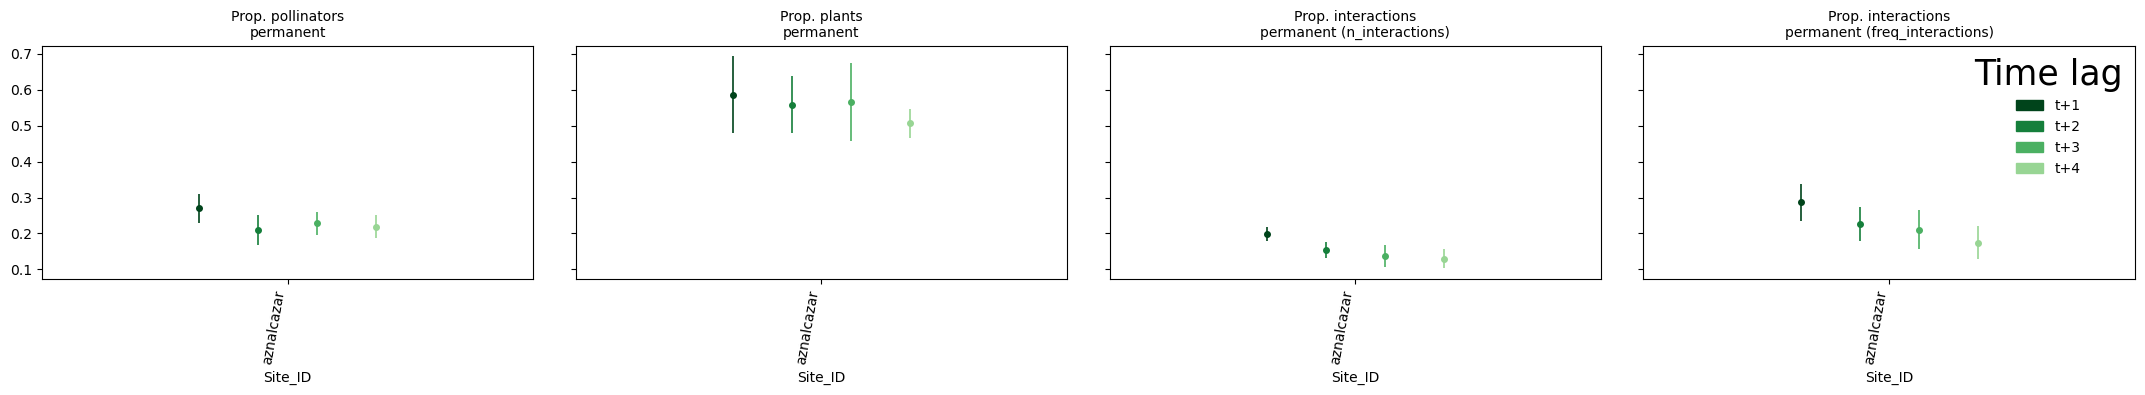

In [27]:
site=Sites[0]
fig, axes, extra_data = plot_lag_summary_combined_horizontal(All_Nodes, All_Changes, site=site)
plt.show()

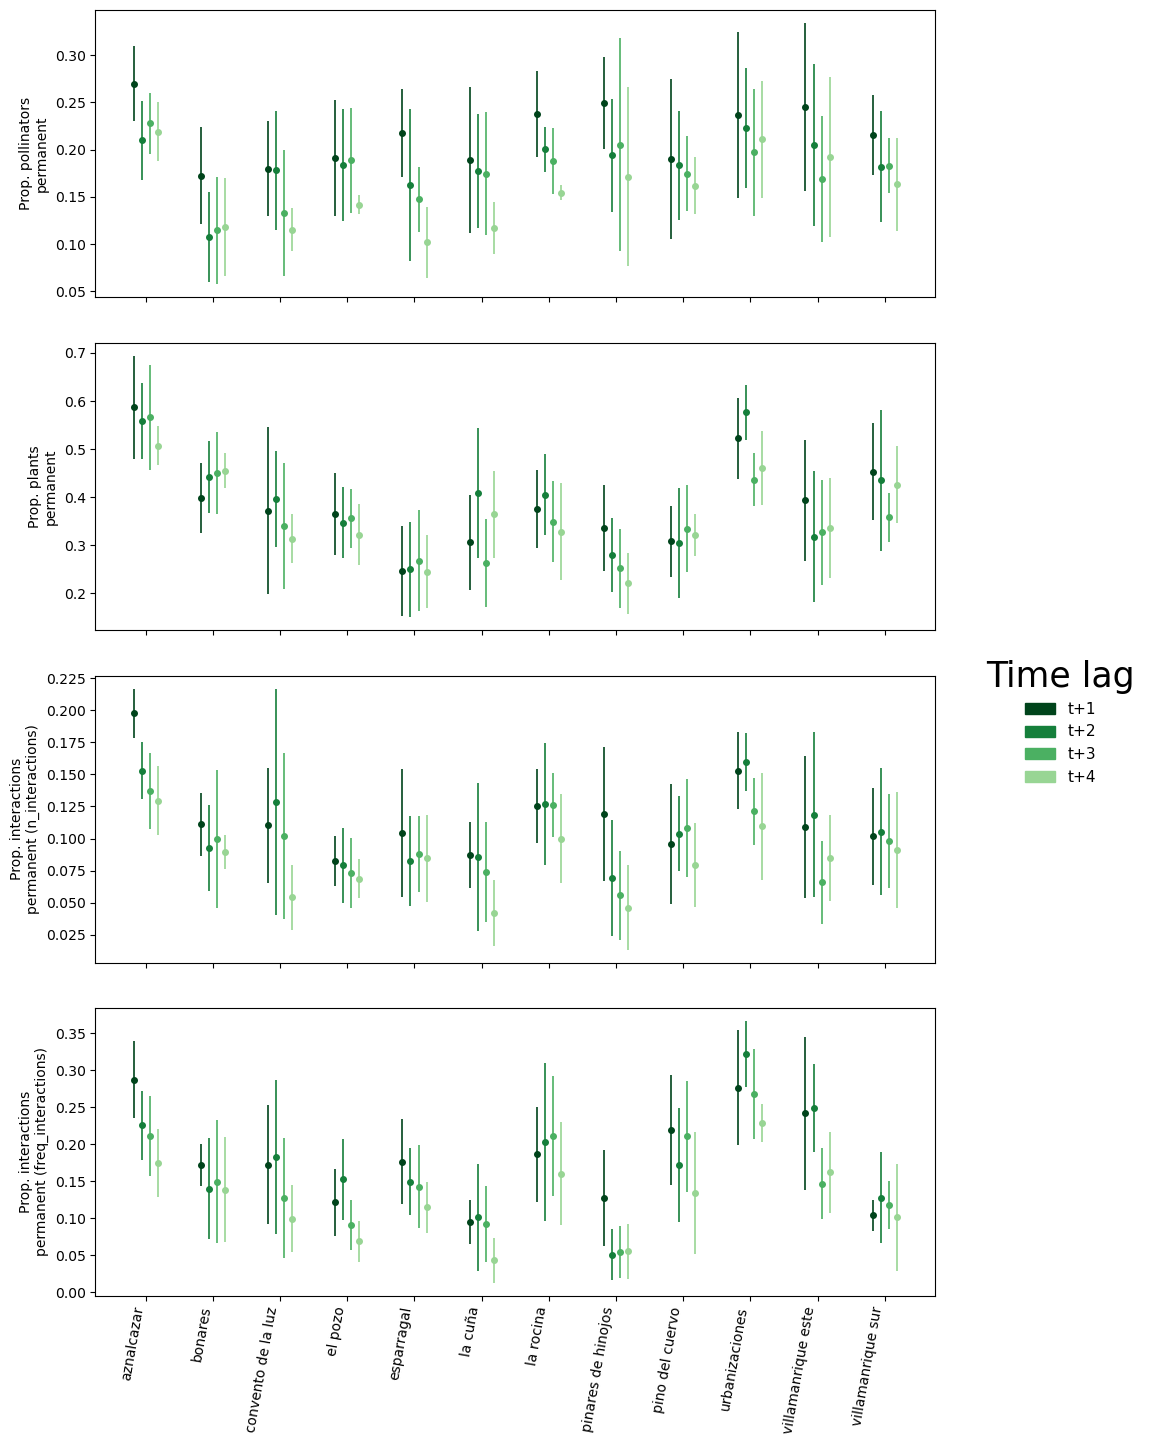

In [ ]:
site=Sites[0]
#fig, axes, extra_data = plot_lag_summary_combined_horizontal(All_Nodes, All_Changes, site=site)
#fig, axes, extra_data = plot_lag_summary_combined_horizontal(All_Nodes, All_Changes,sharey=False, offset=0.12)
fig, axes, extra_data = plot_lag_summary_combined_vertical(All_Nodes, All_Changes,sharey=False, offset=0.12)
plt.show()

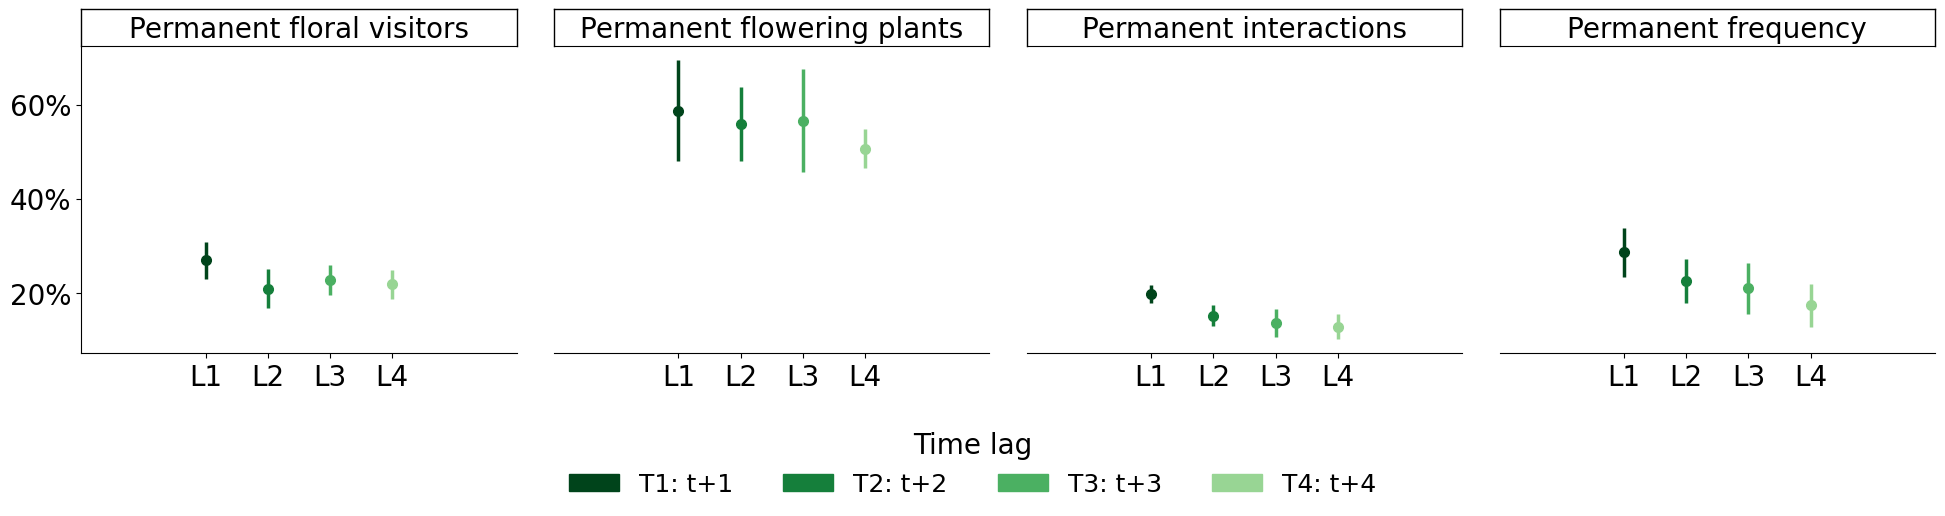

In [31]:
fig, axes, summary_df = plot_lag_summary_temporal(All_Nodes, All_Changes, site=Sites[0])
plt.savefig("temporal_diff.png", dpi=150, bbox_inches='tight')

In [28]:
from matplotlib.ticker import PercentFormatter
def plot_lag_summary_temporal(
        All_Nodes, All_Changes, site, lags=(1, 2, 3, 4), ax=None, figsize=(20, 4.5),
        site_level='Site_ID', metric_col='metric', year_col='year',
        value_col_nodes='n_nodes',
        value_col_changes_1='n_interactions', value_col_changes_2='freq_interactions',
        permanent_int_categories=('CN_CI', 'CN_DI', 'CN_II'),
        change_categories=('CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        poll_permanent='PA', poll_transient=('A1', 'A2'),
        plant_permanent='PP', plant_transient=('P1', 'P2'),
        cmap=None, cmap_range=(1.0, 0.4),
        marker='.', markersize=14, capsize=0, elinewidth=2.5,
        fontsize=20, sharey=True, rotate_labels=0,
        titles=('Permanent floral visitors', 'Permanent flowering plants','Permanent interactions', 'Permanent frequency')):
    """
    Version TEMPORAL de plot_persistence_by_distance -- caso particular de
    plot_lag_summary_combined_horizontal, filtrado SIEMPRE a UN sitio: el
    eje x son directamente los LAGS (t+1, t+2, t+3, t+4) de ESE sitio --
    un punto por lag, sin desplazamiento (ya no compiten varias series en
    la misma posicion x).
 
    4 paneles horizontales, mismo estilo que plot_persistence_by_distance.
 
    Parameters
    ----------
    All_Nodes, All_Changes : dict {lag: pd.DataFrame}
        Tus diccionarios completos.
    site : str
        El Site_ID a representar -- SIEMPRE se filtra a este sitio.
    lags : tuple de int
        Que lags mostrar, en el eje x.
    ax : lista de 4 matplotlib Axes o None
        Si se pasa, dibuja sobre esos 4 ejes. Si no, crea figura nueva.
 
    Devuelve
    -------
    fig (o None si se pasaron ejes), axes (lista de 4), summary_df
    """
    if cmap is None:
        cmap = plt.cm.Greens
    colors = cmap(np.linspace(cmap_range[0], cmap_range[1], len(lags)))
 
    All_Nodes_site = {}
    All_Changes_site = {}
    for lag in lags:
        nodes_flat = All_Nodes[lag]
        nodes_flat = nodes_flat.reset_index() if nodes_flat.index.nlevels > 1 or nodes_flat.index.name is not None else nodes_flat.copy()
        changes_flat = All_Changes[lag]
        changes_flat = changes_flat.reset_index() if changes_flat.index.nlevels > 1 or changes_flat.index.name is not None else changes_flat.copy()
 
        All_Nodes_site[lag] = nodes_flat[nodes_flat[site_level] == site]
        All_Changes_site[lag] = changes_flat[changes_flat[site_level] == site]
 
    plant_means, plant_stds = [], []
    poll_means, poll_stds = [], []
    prop1_means, prop1_stds = [], []
    prop2_means, prop2_stds = [], []
 
    for lag in lags:
        poll_r, plant_r, _, prop_1 = _compute_site_year_metrics(
            All_Nodes_site[lag], All_Changes_site[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes_1,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
 
        _, _, _, prop_2 = _compute_site_year_metrics(
            All_Nodes_site[lag], All_Changes_site[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes_2,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
 
        poll_vals = poll_r.get(site, [])
        plant_vals = plant_r.get(site, [])
        prop1_vals = prop_1.get(site, [])
        prop2_vals = prop_2.get(site, [])
 
        poll_means.append(np.nanmean(poll_vals) if len(poll_vals) else np.nan)
        poll_stds.append(np.nanstd(poll_vals) if len(poll_vals) else np.nan)
        plant_means.append(np.nanmean(plant_vals) if len(plant_vals) else np.nan)
        plant_stds.append(np.nanstd(plant_vals) if len(plant_vals) else np.nan)
        prop1_means.append(np.nanmean(prop1_vals) if len(prop1_vals) else np.nan)
        prop1_stds.append(np.nanstd(prop1_vals) if len(prop1_vals) else np.nan)
        prop2_means.append(np.nanmean(prop2_vals) if len(prop2_vals) else np.nan)
        prop2_stds.append(np.nanstd(prop2_vals) if len(prop2_vals) else np.nan)
 
    lag_labels = [f't+{lag}' for lag in lags]
    summary_df = pd.DataFrame({
        'lag': lag_labels,
        'plant_mean': plant_means, 'plant_std': plant_stds,
        'pollinator_mean': poll_means, 'pollinator_std': poll_stds,
        'interaction_1_mean': prop1_means, 'interaction_1_std': prop1_stds,
        'interaction_2_mean': prop2_means, 'interaction_2_std': prop2_stds,
    }).set_index('lag')
 
    created_own_fig = ax is None
    if created_own_fig:
        fig, axes = plt.subplots(1, 4, figsize=figsize, sharey=sharey)
    else:
        fig = None
        axes = ax
 
    all_means = [ poll_means, plant_means,prop1_means, prop2_means]
    all_stds = [ poll_stds, plant_stds,prop1_stds, prop2_stds]
 
    x = np.arange(len(lags))
 
    for panel_ax, means, stds, title in zip(axes, all_means, all_stds, titles):
        for i in range(len(lags)):
            panel_ax.errorbar(x[i], means[i], yerr=stds[i], fmt=marker,
                               color=colors[i], markersize=markersize, capsize=capsize,
                               elinewidth=elinewidth)
        panel_ax.set_title(title, fontsize=fontsize)
        panel_ax.set_xticks(x)
        panel_ax.set_xticklabels(lag_labels, rotation=rotate_labels, fontsize=fontsize)
        panel_ax.tick_params(axis='y', labelsize=fontsize)
        panel_ax.set_xlim(-2,5)
        panel_ax.yaxis.set_major_locator(MultipleLocator(0.2))
        panel_ax.set_xticklabels(['L1', 'L2', 'L3', 'L4'])
        panel_ax.plot([0, 1], [1.12, 1.12], transform=panel_ax.transAxes,color='black', lw=1, clip_on=False)
        panel_ax.plot([0, 0], [1.0, 1.12], transform=panel_ax.transAxes,color='black', lw=1, clip_on=False)
        panel_ax.plot([1, 1], [1.0, 1.12], transform=panel_ax.transAxes,color='black', lw=1, clip_on=False)
        panel_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
 
    if sharey and created_own_fig:
        for panel_ax in axes[1:]:
            panel_ax.tick_params(axis='y', labelleft=False)
    
    for i, panel_ax in enumerate(axes):
        #panel_ax.spines['top'].set_visible(False)
        panel_ax.spines['right'].set_visible(False)
        if i > 0:
            panel_ax.spines['left'].set_visible(False)
            panel_ax.tick_params(axis='y', left=False)  # tambien quita las marcas de tick, no solo la linea
 
    handles = [mpatches.Patch(color=colors[i], label=f"T{i+1}: {lag}") for i, lag in enumerate(lag_labels)]
    fig.legend(handles=handles, title='Time lag', loc='lower center', bbox_to_anchor=(0.5, -0.2),ncol=len(lag_labels), frameon=False, fontsize=fontsize-2, title_fontsize=fontsize)

    if created_own_fig:
        plt.tight_layout()
        return fig, axes, summary_df
    else:
        return axes, summary_df
 


In [30]:
def _compute_site_year_metrics(
        nodes_df_lag, changes_df_lag, site_level, metric_col, year_col,
        value_col_nodes, value_col_changes,
        permanent_int_categories, change_categories,
        poll_permanent, poll_transient, plant_permanent, plant_transient):
    """
    Helper interno: calcula, por sitio y año, las variables para UN lag.
    """
    nodes_flat = nodes_df_lag.reset_index() if nodes_df_lag.index.nlevels > 1 or nodes_df_lag.index.name is not None else nodes_df_lag.copy()
    changes_flat = changes_df_lag.reset_index() if changes_df_lag.index.nlevels > 1 or changes_df_lag.index.name is not None else changes_df_lag.copy()
 
    sites = sorted(nodes_flat[site_level].unique())
 
    def get_node_val(df_site_year, metric):
        v = df_site_year.loc[df_site_year[metric_col] == metric, value_col_nodes]
        return v.sum() if len(v) else 0
 
    poll_ratios = {s: [] for s in sites}
    plant_ratios = {s: [] for s in sites}

    n_changes = {s: [] for s in sites}
    prop_permanent_int = {s: [] for s in sites}
 
    for site in sites:
        sub_nodes = nodes_flat[nodes_flat[site_level] == site]
        sub_changes = changes_flat[changes_flat[site_level] == site]
        years = sorted(sub_nodes[year_col].unique())
 
        for yr in years:
            yr_nodes = sub_nodes[sub_nodes[year_col] == yr]
 
            pa = get_node_val(yr_nodes, poll_permanent)
            a_trans = sum(get_node_val(yr_nodes, m) for m in poll_transient)
            poll_total = pa + a_trans
            poll_ratios[site].append(pa / poll_total if poll_total > 0 else np.nan)
 
            pp = get_node_val(yr_nodes, plant_permanent)
            p_trans = sum(get_node_val(yr_nodes, m) for m in plant_transient)
            plant_total = pp + p_trans
            plant_ratios[site].append(pp / plant_total if plant_total > 0 else np.nan)
 
            yr_changes = sub_changes[sub_changes[year_col] == yr]
            n_permanent_int = yr_changes.loc[yr_changes[metric_col].isin(permanent_int_categories), value_col_changes].sum()
            n_change = yr_changes.loc[yr_changes[metric_col].isin(change_categories), value_col_changes].sum()
            n_all_int = n_permanent_int + n_change
 
            n_changes[site].append(n_change)
            prop_permanent_int[site].append(n_permanent_int / n_all_int if n_all_int > 0 else np.nan)
 
    return poll_ratios, plant_ratios, n_changes, prop_permanent_int
 
 
def plot_lag_summary_combined_horizontal(
        All_Nodes, All_Changes, lags=(1, 2, 3, 4), figsize=(22, 4.5),
        site_level='Site_ID', metric_col='metric', year_col='year',
        value_col_nodes='n_nodes',
        value_col_changes_1='n_interactions', value_col_changes_2='freq_interactions',
        permanent_int_categories=('CN_CI', 'CN_DI', 'CN_II'),
        change_categories=('CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        poll_permanent='PA', poll_transient=('A1', 'A2'),
        plant_permanent='PP', plant_transient=('P1', 'P2'),
        offset=0.12, cmap=None, cmap_range=(1.0, 0.4),
        fontsize=10, capsize=0, marker='.', markersize=8,
        rotate_labels=80, label_dict=None, legend_loc='upper right',
        site=None, sharey=True):
    """
    Version HORIZONTAL con 4 PANELES en fila, compartiendo el eje y:
      1. Prop. pollinators permanent
      2. Prop. plants permanent
      3. Prop. interactions permanent -- usando value_col_changes_1
         (por defecto 'n_interactions')
      4. Prop. interactions permanent -- usando value_col_changes_2
         (por defecto 'freq_interactions')
 
    Los paneles 3 y 4 usan la MISMA logica, solo cambia la columna de
    Changes_df -- asi comparas directamente contar vs pesar por frecuencia.
 
    Devuelve
    -------
    fig, (ax1, ax2, ax3, ax4), extra_data
    """
    if cmap is None:
        cmap = plt.cm.Greens
    if label_dict is None:
        label_dict = {
            'poll': 'Prop. pollinators\npermanent',
            'plant': 'Prop. plants\npermanent',
            'prop1': f'Prop. interactions\npermanent ({value_col_changes_1})',
            'prop2': f'Prop. interactions\npermanent ({value_col_changes_2})',
        }
 
    colors = cmap(np.linspace(cmap_range[0], cmap_range[1], len(lags)))
 
    if site is not None:
        All_Nodes_use = {}
        All_Changes_use = {}
        for lag in lags:
            nodes_flat = All_Nodes[lag]
            nodes_flat = nodes_flat.reset_index() if nodes_flat.index.nlevels > 1 or nodes_flat.index.name is not None else nodes_flat.copy()
            changes_flat = All_Changes[lag]
            changes_flat = changes_flat.reset_index() if changes_flat.index.nlevels > 1 or changes_flat.index.name is not None else changes_flat.copy()
 
            All_Nodes_use[lag] = nodes_flat[nodes_flat[site_level] == site]
            All_Changes_use[lag] = changes_flat[changes_flat[site_level] == site]
    else:
        All_Nodes_use = All_Nodes
        All_Changes_use = All_Changes
 
    nodes_flat0 = All_Nodes_use[lags[0]]
    nodes_flat0 = nodes_flat0.reset_index() if nodes_flat0.index.nlevels > 1 or nodes_flat0.index.name is not None else nodes_flat0
    sites = sorted(nodes_flat0[site_level].unique())
    x = np.arange(len(sites))
 
    n = len(lags)
    offsets = [(i - (n - 1) / 2) * offset for i in range(n)]
 
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=figsize, sharey=sharey)
 
    extra_data = {}
    for i, lag in enumerate(lags):
        poll_ratios, plant_ratios, _, prop_1 = _compute_site_year_metrics(
            All_Nodes_use[lag], All_Changes_use[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes_1,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
        #plant_ratios = {s: (1 - np.array(vals)).tolist() for s, vals in plant_ratios.items()}
        _, _, _, prop_2 = _compute_site_year_metrics(
            All_Nodes_use[lag], All_Changes_use[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes_2,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
        
        extra_data[lag] = {'prop_1': prop_1, 'prop_2': prop_2}
 
        x_off = x + offsets[i]
        color = colors[i]
 
        for ax, data_dict in zip((ax1, ax2, ax3, ax4), (poll_ratios, plant_ratios, prop_1, prop_2)):
            means = [np.nanmean(data_dict.get(s, [np.nan])) for s in sites]
            stds = [np.nanstd(data_dict.get(s, [np.nan])) for s in sites]
            ax.errorbar(x_off, means, yerr=stds, fmt=marker, capsize=capsize,
                        color=color, markersize=markersize, elinewidth=1.2)
 
    ax1.set_title(label_dict['poll'], fontsize=fontsize)
    ax2.set_title(label_dict['plant'], fontsize=fontsize)
    ax3.set_title(label_dict['prop1'], fontsize=fontsize)
    ax4.set_title(label_dict['prop2'], fontsize=fontsize)
 
    for ax in (ax1, ax2, ax3, ax4):
        ax.set_xticks(x)
        ax.set_xticklabels(sites, rotation=rotate_labels, ha='right', fontsize=fontsize)
        ax.set_xlabel(site_level, fontsize=fontsize)
        ax.tick_params(axis='y', labelsize=fontsize)
        ax.set_xlim(-0.5, len(sites) - 0.5)
 
    if sharey:
        for ax in (ax2, ax3, ax4):
            ax.tick_params(axis='y', labelleft=False)
 
    handles = [mpatches.Patch(color=colors[i], label=f't+{lags[i]}') for i in range(n)]
    ax4.legend(handles=handles, title='Time lag', loc=legend_loc, frameon=False, fontsize=fontsize)
 
    plt.tight_layout()
 
    return fig, (ax1, ax2, ax3, ax4), extra_data


def plot_lag_summary_combined_vertical(
        All_Nodes, All_Changes, lags=(1, 2, 3, 4), figsize=(10, 15),
        site_level='Site_ID', metric_col='metric', year_col='year',
        value_col_nodes='n_nodes',
        value_col_changes_1='n_interactions', value_col_changes_2='freq_interactions',
        permanent_int_categories=('CN_CI', 'CN_DI', 'CN_II'),
        change_categories=('CN_LI', 'CN_GI', 'L1N_LI', 'LBN_LI', 'G1N_GI', 'GBN_GI'),
        poll_permanent='PA', poll_transient=('A1', 'A2'),
        plant_permanent='PP', plant_transient=('P1', 'P2'),
        offset=0.12, cmap=None, cmap_range=(1.0, 0.4),
        fontsize=10, capsize=0, marker='.', markersize=8,
        rotate_labels=80, label_dict=None, legend_loc='upper right',
        site=None, sharey=True):
    """
    Version HORIZONTAL con 4 PANELES en fila, compartiendo el eje y:
      1. Prop. pollinators permanent
      2. Prop. plants permanent
      3. Prop. interactions permanent -- usando value_col_changes_1
         (por defecto 'n_interactions')
      4. Prop. interactions permanent -- usando value_col_changes_2
         (por defecto 'freq_interactions')
 
    Los paneles 3 y 4 usan la MISMA logica, solo cambia la columna de
    Changes_df -- asi comparas directamente contar vs pesar por frecuencia.
 
    Devuelve
    -------
    fig, (ax1, ax2, ax3, ax4), extra_data
    """
    if cmap is None:
        cmap = plt.cm.Greens
    if label_dict is None:
        label_dict = {
            'poll': 'Prop. pollinators\npermanent',
            'plant': 'Prop. plants\npermanent',
            'prop1': f'Prop. interactions\npermanent ({value_col_changes_1})',
            'prop2': f'Prop. interactions\npermanent ({value_col_changes_2})',
        }
 
    colors = cmap(np.linspace(cmap_range[0], cmap_range[1], len(lags)))
 
    if site is not None:
        All_Nodes_use = {}
        All_Changes_use = {}
        for lag in lags:
            nodes_flat = All_Nodes[lag]
            nodes_flat = nodes_flat.reset_index() if nodes_flat.index.nlevels > 1 or nodes_flat.index.name is not None else nodes_flat.copy()
            changes_flat = All_Changes[lag]
            changes_flat = changes_flat.reset_index() if changes_flat.index.nlevels > 1 or changes_flat.index.name is not None else changes_flat.copy()
 
            All_Nodes_use[lag] = nodes_flat[nodes_flat[site_level] == site]
            All_Changes_use[lag] = changes_flat[changes_flat[site_level] == site]
    else:
        All_Nodes_use = All_Nodes
        All_Changes_use = All_Changes
 
    nodes_flat0 = All_Nodes_use[lags[0]]
    nodes_flat0 = nodes_flat0.reset_index() if nodes_flat0.index.nlevels > 1 or nodes_flat0.index.name is not None else nodes_flat0
    sites = sorted(nodes_flat0[site_level].unique())
    x = np.arange(len(sites))
 
    n = len(lags)
    offsets = [(i - (n - 1) / 2) * offset for i in range(n)]
 
    fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=figsize, sharey=sharey, sharex=True)
 
    extra_data = {}
    for i, lag in enumerate(lags):
        poll_ratios, plant_ratios, _, prop_1 = _compute_site_year_metrics(
            All_Nodes_use[lag], All_Changes_use[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes_1,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
        #plant_ratios = {s: (1 - np.array(vals)).tolist() for s, vals in plant_ratios.items()}
        _, _, _, prop_2 = _compute_site_year_metrics(
            All_Nodes_use[lag], All_Changes_use[lag], site_level, metric_col, year_col,
            value_col_nodes, value_col_changes_2,
            permanent_int_categories, change_categories,
            poll_permanent, poll_transient, plant_permanent, plant_transient)
        
        extra_data[lag] = {'prop_1': prop_1, 'prop_2': prop_2}
 
        x_off = x + offsets[i]
        color = colors[i]
 
        for ax, data_dict in zip((ax1, ax2, ax3, ax4), (poll_ratios, plant_ratios, prop_1, prop_2)):
            means = [np.nanmean(data_dict.get(s, [np.nan])) for s in sites]
            stds = [np.nanstd(data_dict.get(s, [np.nan])) for s in sites]
            ax.errorbar(x_off, means, yerr=stds, fmt=marker, capsize=capsize,
                        color=color, markersize=markersize, elinewidth=1.2)
 
    ax1.set_ylabel(label_dict['poll'], fontsize=fontsize)
    ax2.set_ylabel(label_dict['plant'], fontsize=fontsize)
    ax3.set_ylabel(label_dict['prop1'], fontsize=fontsize)
    ax4.set_ylabel(label_dict['prop2'], fontsize=fontsize)
 
    for ax in (ax1, ax2, ax3, ax4):
        ax.set_xticks(x)
        ax.set_xticklabels(sites, rotation=rotate_labels, ha='right', fontsize=fontsize)
        #ax.set_xlabel(site_level, fontsize=fontsize)
        ax.tick_params(axis='y', labelsize=fontsize)
        
 
    if sharey:
        for ax in (ax2, ax3, ax4):
            ax.tick_params(axis='y', labelleft=False)
 
    handles = [mpatches.Patch(color=colors[i], label=f't+{lags[i]}') for i in range(n)]
    labels = [h.get_label() for h in handles]
    #ax4.legend(handles=handles, title='Time lag', loc=legend_loc, frameon=False, fontsize=fontsize)
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5),ncol=1, frameon=False, fontsize=fontsize + 1, title="Time lag")
 
    plt.tight_layout()
 
    return fig, (ax1, ax2, ax3, ax4), extra_data
 

 
